In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
file_path = "IPL_ball_by_ball_updated.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 243815
Columns: 22


In [3]:
print(df.columns.tolist())

['match_id', 'season', 'start_date', 'venue', 'innings', 'ball', 'batting_team', 'bowling_team', 'striker', 'non_striker', 'bowler', 'runs_off_bat', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_type', 'player_dismissed', 'other_wicket_type', 'other_player_dismissed']


In [4]:
df.head()

,match_id,season,start_date,venue,innings,ball,batting_team,bowling_team,striker,non_striker,...,extras,wides,noballs,byes,legbyes,penalty,wicket_type,player_dismissed,other_wicket_type,other_player_dismissed
0,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.1,Kolkata Knight Riders,Royal Challengers Bangalore,SC Ganguly,BB McCullum,...,1,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
1,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.2,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.3,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,...,1,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.4,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.5,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 243815 entries, 0 to 243814
Data columns (total 22 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   match_id                243815 non-null  int64  
 1   season                  243815 non-null  int64  
 2   start_date              243815 non-null  str    
 3   venue                   243815 non-null  str    
 4   innings                 243815 non-null  int64  
 5   ball                    243815 non-null  float64
 6   batting_team            243815 non-null  str    
 7   bowling_team            243815 non-null  str    
 8   striker                 243815 non-null  str    
 9   non_striker             243815 non-null  str    
 10  bowler                  243815 non-null  str    
 11  runs_off_bat            243815 non-null  int64  
 12  extras                  243815 non-null  int64  
 13  wides                   7652 non-null    float64
 14  noballs                 1018 no

In [6]:
missing_values = df.isnull().sum()

print(missing_values)

match_id                       0
season                         0
start_date                     0
venue                          0
innings                        0
ball                           0
batting_team                   0
bowling_team                   0
striker                        0
non_striker                    0
bowler                         0
runs_off_bat                   0
extras                         0
wides                     236163
noballs                   242797
byes                      243187
legbyes                   240037
penalty                   243813
wicket_type               231748
player_dismissed          231748
other_wicket_type         243815
other_player_dismissed    243815
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
print("Seasons:", sorted(df["season"].unique()))

Seasons: [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]


In [9]:
print("Total matches:", df["match_id"].nunique())

Total matches: 1024


In [10]:
# Step 2 — Data Cleaning

In [11]:
df = df.drop(columns=[
    "other_wicket_type",
    "other_player_dismissed"
])

print(df.shape)

(243815, 20)


In [12]:
df["start_date"] = pd.to_datetime(
    df["start_date"],
    errors="coerce"
)

print(df["start_date"].dtype)

datetime64[us]


In [13]:
print("Invalid dates:", df["start_date"].isna().sum())

Invalid dates: 0


In [14]:
event_columns = [
    "wides",
    "noballs",
    "byes",
    "legbyes",
    "penalty"
]

df[event_columns] = df[event_columns].fillna(0)

In [15]:
print(df[event_columns].isnull().sum())

wides      0
noballs    0
byes       0
legbyes    0
penalty    0
dtype: int64


In [16]:
df["wicket_type"] = df["wicket_type"].fillna("No Wicket")

df["player_dismissed"] = df["player_dismissed"].fillna("No Dismissal")

In [17]:
print(df.isnull().sum())

match_id            0
season              0
start_date          0
venue               0
innings             0
ball                0
batting_team        0
bowling_team        0
striker             0
non_striker         0
bowler              0
runs_off_bat        0
extras              0
wides               0
noballs             0
byes                0
legbyes             0
penalty             0
wicket_type         0
player_dismissed    0
dtype: int64


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 243815 entries, 0 to 243814
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   match_id          243815 non-null  int64         
 1   season            243815 non-null  int64         
 2   start_date        243815 non-null  datetime64[us]
 3   venue             243815 non-null  str           
 4   innings           243815 non-null  int64         
 5   ball              243815 non-null  float64       
 6   batting_team      243815 non-null  str           
 7   bowling_team      243815 non-null  str           
 8   striker           243815 non-null  str           
 9   non_striker       243815 non-null  str           
 10  bowler            243815 non-null  str           
 11  runs_off_bat      243815 non-null  int64         
 12  extras            243815 non-null  int64         
 13  wides             243815 non-null  float64       
 14  noballs        

In [19]:
cleaned_file = "IPL_ball_by_ball_cleaned.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [20]:
# Step 3 — Exploratory Data Analysis (EDA)

In [21]:
print("Total Seasons:", df["season"].nunique())

print("\nSeasons:")
print(sorted(df["season"].unique()))

Total Seasons: 16

Seasons:
[np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]


In [22]:
total_matches = df["match_id"].nunique()

print("Total Matches:", total_matches)

Total Matches: 1024


In [23]:
matches_per_season = df.groupby("season")["match_id"].nunique()

print(matches_per_season)

season
2008    58
2009    57
2010    60
2011    73
2012    74
2013    76
2014    60
2015    59
2016    60
2017    59
2018    60
2019    60
2020    60
2021    60
2022    74
2023    74
Name: match_id, dtype: int64


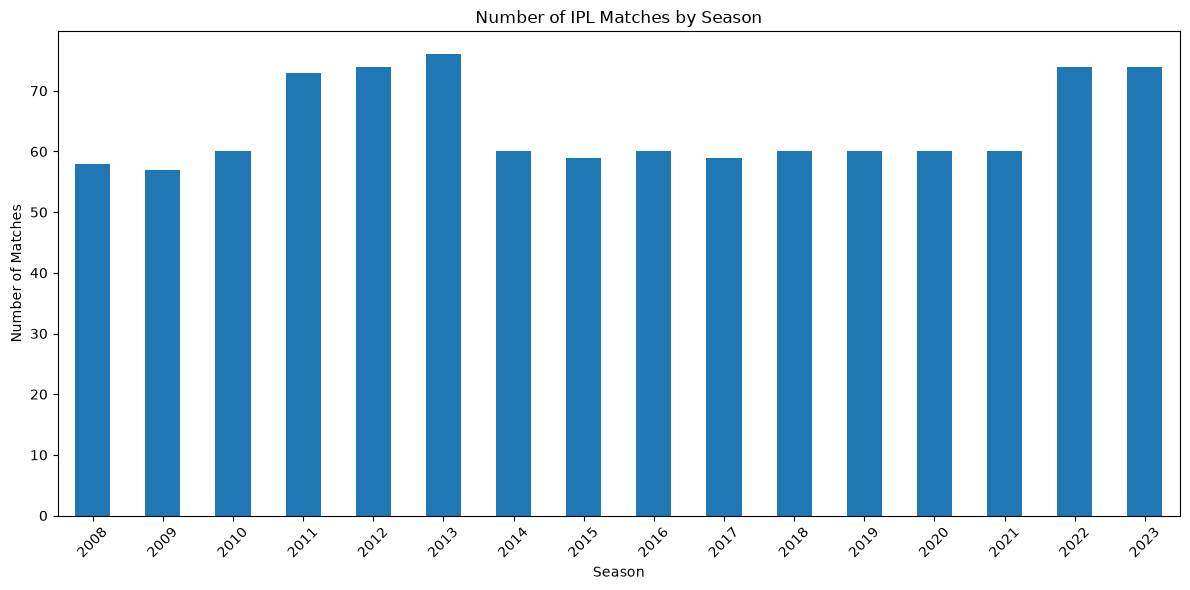

In [24]:
plt.figure(figsize=(12, 6))

matches_per_season.plot(kind="bar")

plt.title("Number of IPL Matches by Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
teams = sorted(set(df["batting_team"].unique()) |
               set(df["bowling_team"].unique()))

print("Total Teams:", len(teams))

print("\nTeams:")
for team in teams:
    print(team)

Total Teams: 18

Teams:
Chennai Super Kings
Deccan Chargers
Delhi Capitals
Delhi Daredevils
Gujarat Lions
Gujarat Titans
Kings XI Punjab
Kochi Tuskers Kerala
Kolkata Knight Riders
Lucknow Super Giants
Mumbai Indians
Pune Warriors
Punjab Kings
Rajasthan Royals
Rising Pune Supergiant
Rising Pune Supergiants
Royal Challengers Bangalore
Sunrisers Hyderabad


In [26]:
batting_matches = df.groupby("batting_team")["match_id"].nunique()

bowling_matches = df.groupby("bowling_team")["match_id"].nunique()

team_matches = pd.concat(
    [batting_matches, bowling_matches],
    axis=1
)

team_matches.columns = [
    "Batting Matches",
    "Bowling Matches"
]

print(team_matches)

                             Batting Matches  Bowling Matches
Chennai Super Kings                      223              224
Deccan Chargers                           75               75
Delhi Capitals                            77               77
Delhi Daredevils                         161              160
Gujarat Lions                             30               30
Gujarat Titans                            33               33
Kings XI Punjab                          190              190
Kochi Tuskers Kerala                      14               14
Kolkata Knight Riders                    237              237
Lucknow Super Giants                      30               29
Mumbai Indians                           247              247
Pune Warriors                             45               46
Punjab Kings                              42               42
Rajasthan Royals                         205              206
Rising Pune Supergiant                    16               16
Rising P

In [27]:
team_runs = (
    df.groupby("batting_team")["runs_off_bat"]
      .sum()
      .sort_values(ascending=False)
)

print(team_runs)

batting_team
Mumbai Indians                 37523
Royal Challengers Bangalore    35810
Kolkata Knight Riders          34668
Chennai Super Kings            34334
Rajasthan Royals               30541
Kings XI Punjab                28541
Sunrisers Hyderabad            24735
Delhi Daredevils               23022
Delhi Capitals                 11764
Deccan Chargers                10885
Punjab Kings                    6670
Pune Warriors                   6040
Gujarat Titans                  5423
Lucknow Super Giants            4731
Gujarat Lions                   4629
Rising Pune Supergiant          2370
Rising Pune Supergiants         1962
Kochi Tuskers Kerala            1758
Name: runs_off_bat, dtype: int64


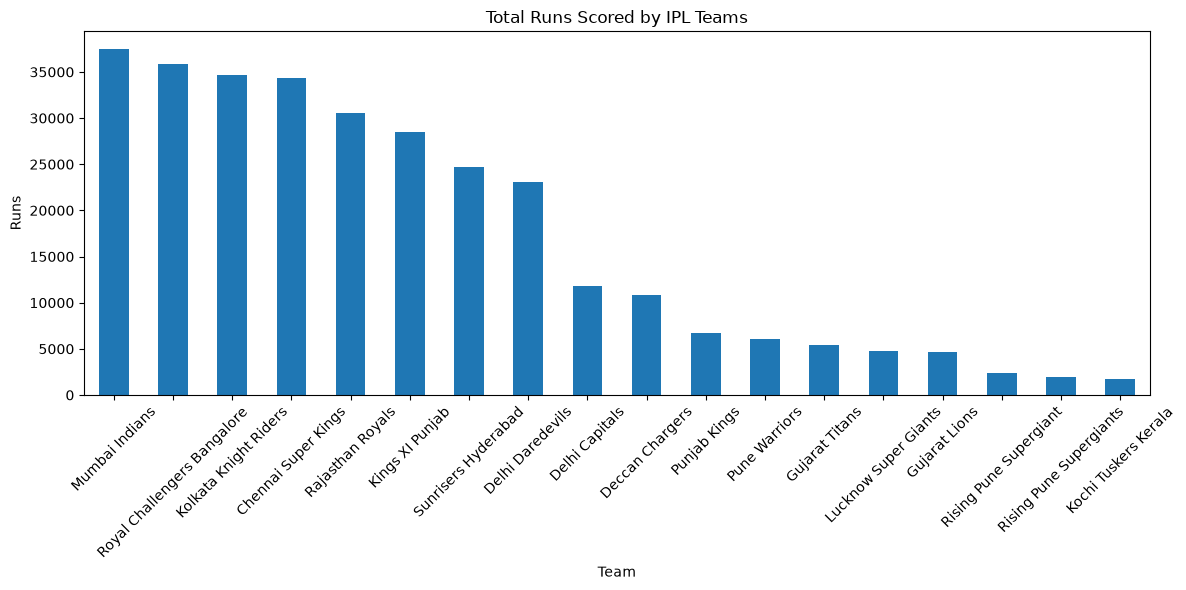

In [28]:
plt.figure(figsize=(12, 6))

team_runs.plot(kind="bar")

plt.title("Total Runs Scored by IPL Teams")
plt.xlabel("Team")
plt.ylabel("Runs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
wickets = df[df["wicket_type"] != "No Wicket"]

print("Total Wicket Events:", len(wickets))

Total Wicket Events: 12067


In [30]:
team_wickets = (
    wickets.groupby("bowling_team")
           .size()
           .sort_values(ascending=False)
)

print(team_wickets)

bowling_team
Mumbai Indians                 1506
Royal Challengers Bangalore    1406
Chennai Super Kings            1402
Kolkata Knight Riders          1354
Rajasthan Royals               1181
Kings XI Punjab                1076
Sunrisers Hyderabad             991
Delhi Daredevils                912
Delhi Capitals                  487
Deccan Chargers                 446
Pune Warriors                   238
Punjab Kings                    234
Gujarat Titans                  227
Lucknow Super Giants            193
Gujarat Lions                   151
Rising Pune Supergiant          113
Rising Pune Supergiants          76
Kochi Tuskers Kerala             74
dtype: int64


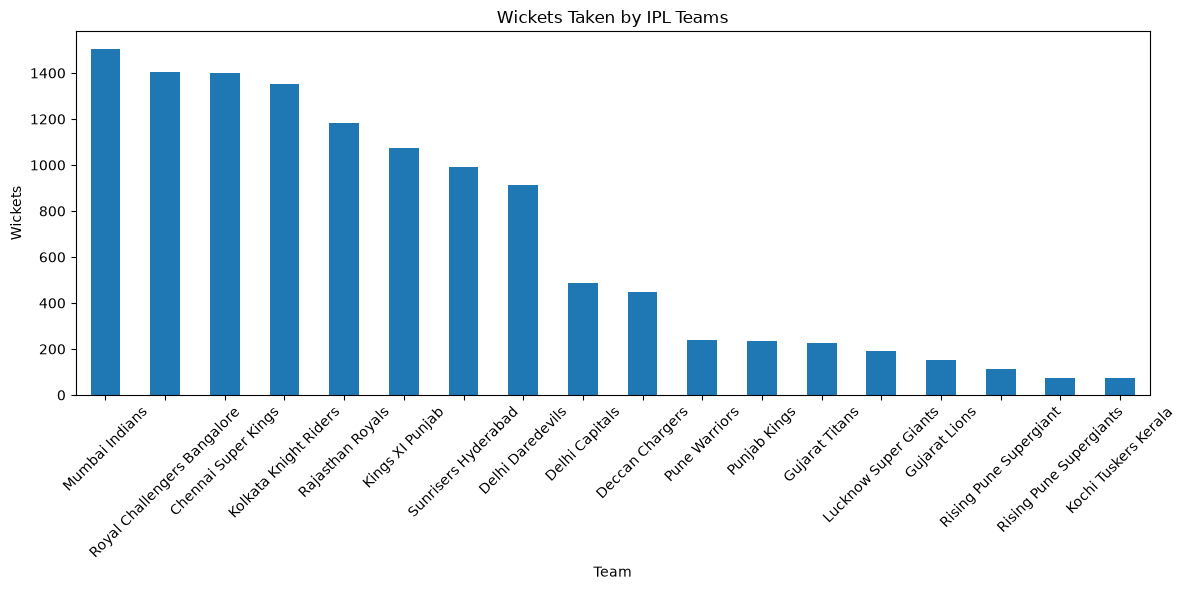

In [31]:
plt.figure(figsize=(12, 6))

team_wickets.plot(kind="bar")

plt.title("Wickets Taken by IPL Teams")
plt.xlabel("Team")
plt.ylabel("Wickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
top_batters = (
    df.groupby("striker")["runs_off_bat"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_batters)

striker
V Kohli           7273
S Dhawan          6617
DA Warner         6399
RG Sharma         6213
SK Raina          5536
AB de Villiers    5181
MS Dhoni          5082
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4517
Name: runs_off_bat, dtype: int64


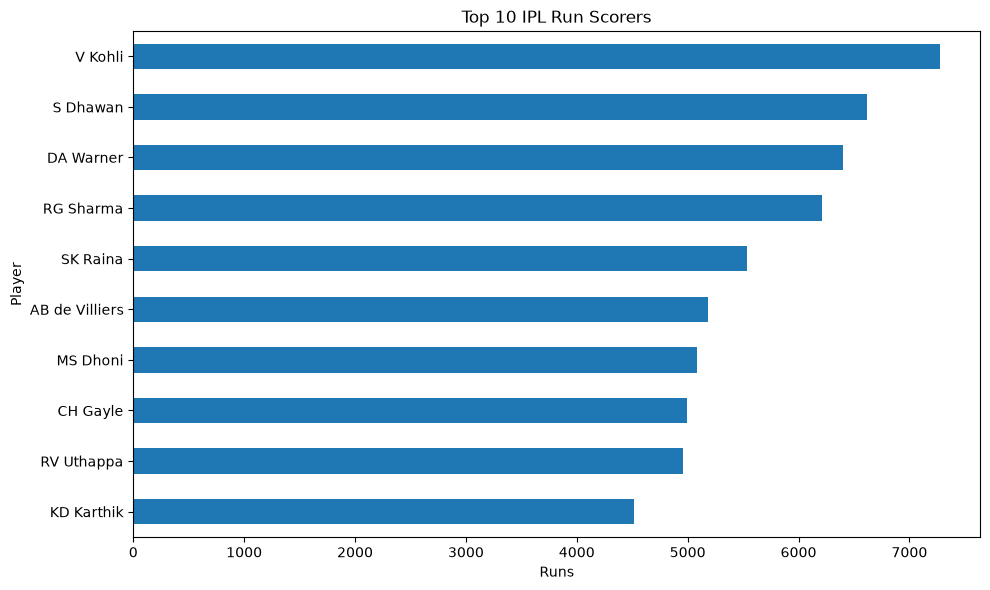

In [33]:
plt.figure(figsize=(10, 6))

top_batters.sort_values().plot(kind="barh")

plt.title("Top 10 IPL Run Scorers")
plt.xlabel("Runs")
plt.ylabel("Player")

plt.tight_layout()
plt.show()

In [34]:
top_bowlers = (
    wickets.groupby("bowler")
           .size()
           .sort_values(ascending=False)
           .head(10)
)

print(top_bowlers)

bowler
DJ Bravo      207
YS Chahal     194
R Ashwin      189
SL Malinga    188
PP Chawla     188
B Kumar       184
SP Narine     182
A Mishra      182
RA Jadeja     161
JJ Bumrah     161
dtype: int64


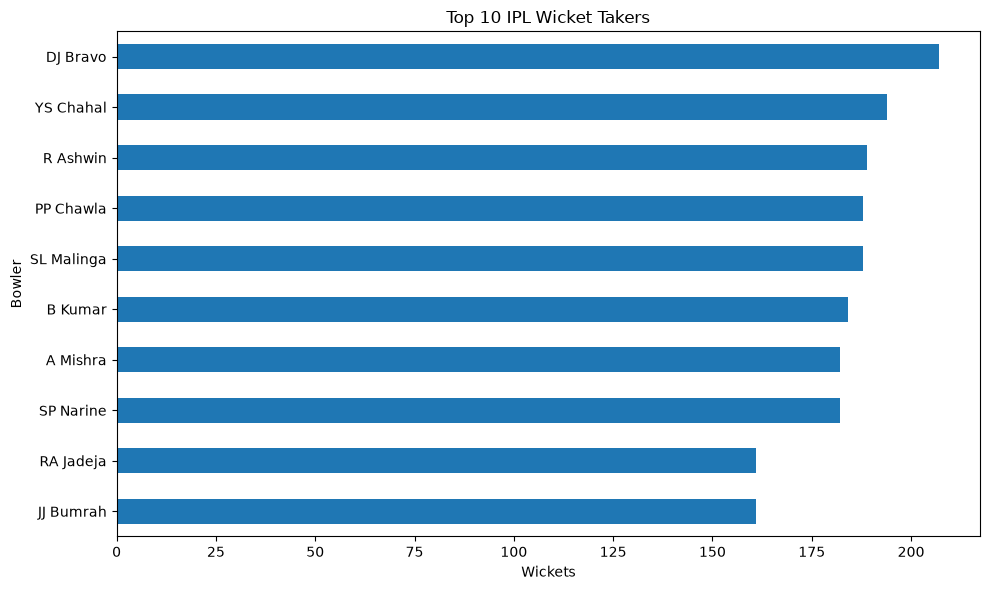

In [35]:
plt.figure(figsize=(10, 6))

top_bowlers.sort_values().plot(kind="barh")

plt.title("Top 10 IPL Wicket Takers")
plt.xlabel("Wickets")
plt.ylabel("Bowler")

plt.tight_layout()
plt.show()

In [36]:
venue_matches = (
    df.groupby("venue")["match_id"]
      .nunique()
      .sort_values(ascending=False)
      .head(10)
)

print(venue_matches)

venue
Eden Gardens                                  77
Wankhede Stadium                              73
M Chinnaswamy Stadium                         65
Feroz Shah Kotla                              60
Rajiv Gandhi International Stadium, Uppal     49
MA Chidambaram Stadium, Chepauk               48
Sawai Mansingh Stadium                        47
Dubai International Cricket Stadium           46
Wankhede Stadium, Mumbai                      38
Punjab Cricket Association Stadium, Mohali    35
Name: match_id, dtype: int64


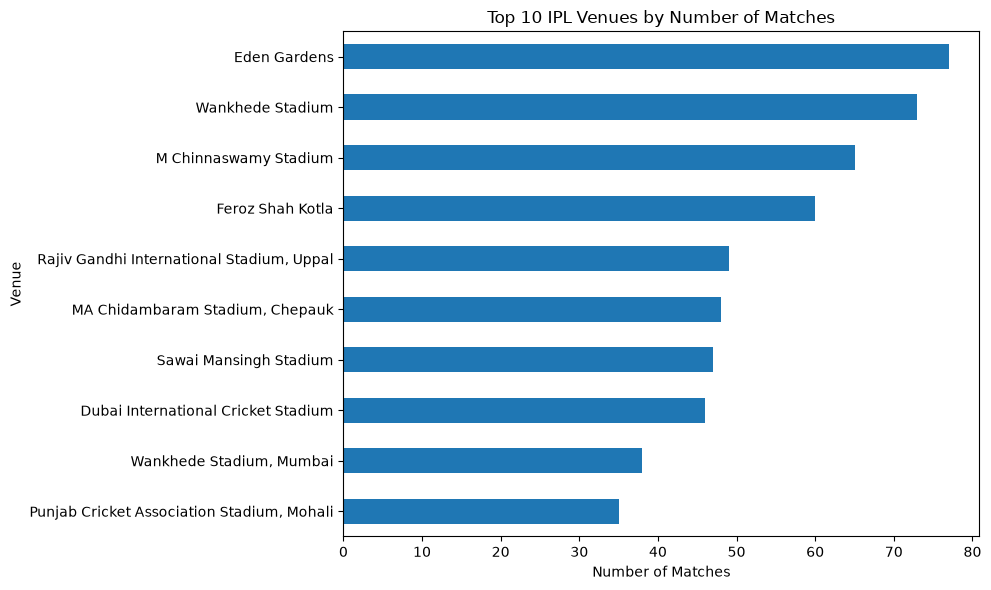

In [37]:
plt.figure(figsize=(10, 6))

venue_matches.sort_values().plot(kind="barh")

plt.title("Top 10 IPL Venues by Number of Matches")
plt.xlabel("Number of Matches")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

In [38]:
team_mapping = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Rising Pune Supergiant": "Rising Pune Supergiants"
}

df["batting_team"] = df["batting_team"].replace(team_mapping)
df["bowling_team"] = df["bowling_team"].replace(team_mapping)

In [39]:
teams = sorted(
    set(df["batting_team"].unique()) |
    set(df["bowling_team"].unique())
)

print("Total Teams:", len(teams))

for team in teams:
    print(team)

Total Teams: 15
Chennai Super Kings
Deccan Chargers
Delhi Capitals
Gujarat Lions
Gujarat Titans
Kochi Tuskers Kerala
Kolkata Knight Riders
Lucknow Super Giants
Mumbai Indians
Pune Warriors
Punjab Kings
Rajasthan Royals
Rising Pune Supergiants
Royal Challengers Bangalore
Sunrisers Hyderabad


In [40]:
total_matches = df["match_id"].nunique()

print("Total Matches:", total_matches)

Total Matches: 1024


In [41]:
matches_per_season = df.groupby("season")["match_id"].nunique()

print(matches_per_season)

season
2008    58
2009    57
2010    60
2011    73
2012    74
2013    76
2014    60
2015    59
2016    60
2017    59
2018    60
2019    60
2020    60
2021    60
2022    74
2023    74
Name: match_id, dtype: int64


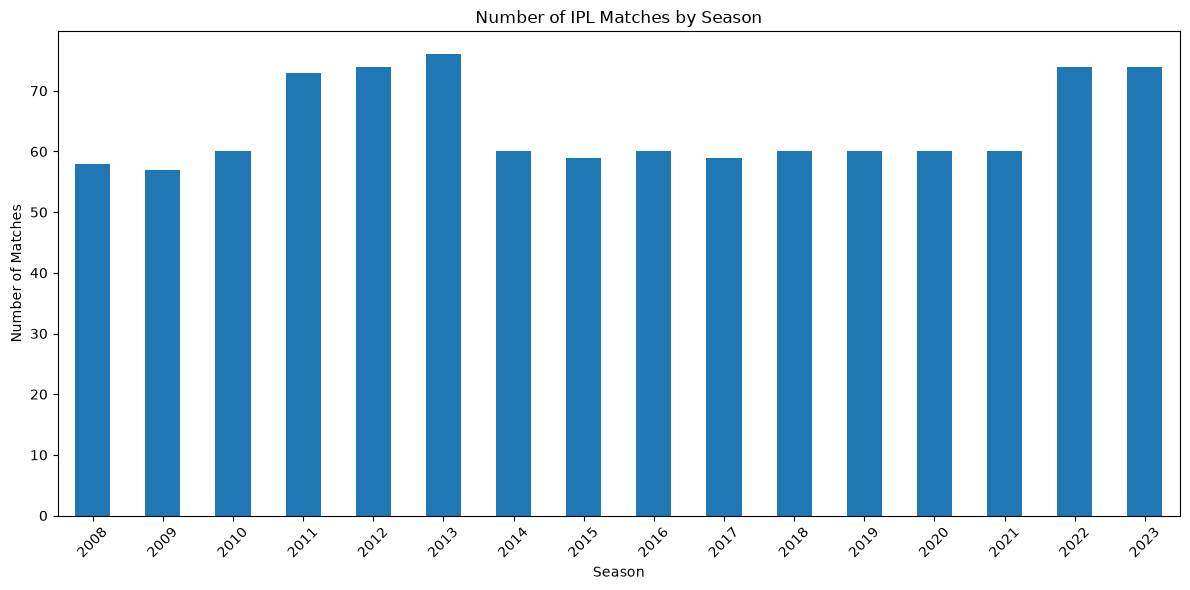

In [42]:
plt.figure(figsize=(12, 6))

matches_per_season.plot(kind="bar")

plt.title("Number of IPL Matches by Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [43]:
teams = sorted(
    set(df["batting_team"].unique()) |
    set(df["bowling_team"].unique())
)

print("Total Teams:", len(teams))

for team in teams:
    print(team)

Total Teams: 15
Chennai Super Kings
Deccan Chargers
Delhi Capitals
Gujarat Lions
Gujarat Titans
Kochi Tuskers Kerala
Kolkata Knight Riders
Lucknow Super Giants
Mumbai Indians
Pune Warriors
Punjab Kings
Rajasthan Royals
Rising Pune Supergiants
Royal Challengers Bangalore
Sunrisers Hyderabad


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "IPL_ball_by_ball_updated.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (243815, 22)


In [45]:
file_path = "IPL_ball_by_ball_cleaned.csv"

df = pd.read_csv(file_path)

df["start_date"] = pd.to_datetime(df["start_date"])

print("Cleaned dataset loaded successfully!")
print("Shape:", df.shape)

Cleaned dataset loaded successfully!
Shape: (243815, 20)


In [46]:
team_mapping = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Rising Pune Supergiant": "Rising Pune Supergiants"
}

df["batting_team"] = df["batting_team"].replace(team_mapping)
df["bowling_team"] = df["bowling_team"].replace(team_mapping)

In [47]:
teams = sorted(
    set(df["batting_team"].unique()) |
    set(df["bowling_team"].unique())
)

print("Total Teams:", len(teams))

for team in teams:
    print(team)

Total Teams: 15
Chennai Super Kings
Deccan Chargers
Delhi Capitals
Gujarat Lions
Gujarat Titans
Kochi Tuskers Kerala
Kolkata Knight Riders
Lucknow Super Giants
Mumbai Indians
Pune Warriors
Punjab Kings
Rajasthan Royals
Rising Pune Supergiants
Royal Challengers Bangalore
Sunrisers Hyderabad


In [48]:
team_runs = (
    df.groupby("batting_team")["runs_off_bat"]
      .sum()
      .sort_values(ascending=False)
)

print(team_runs)

batting_team
Mumbai Indians                 37523
Royal Challengers Bangalore    35810
Punjab Kings                   35211
Delhi Capitals                 34786
Kolkata Knight Riders          34668
Chennai Super Kings            34334
Rajasthan Royals               30541
Sunrisers Hyderabad            24735
Deccan Chargers                10885
Pune Warriors                   6040
Gujarat Titans                  5423
Lucknow Super Giants            4731
Gujarat Lions                   4629
Rising Pune Supergiants         4332
Kochi Tuskers Kerala            1758
Name: runs_off_bat, dtype: int64


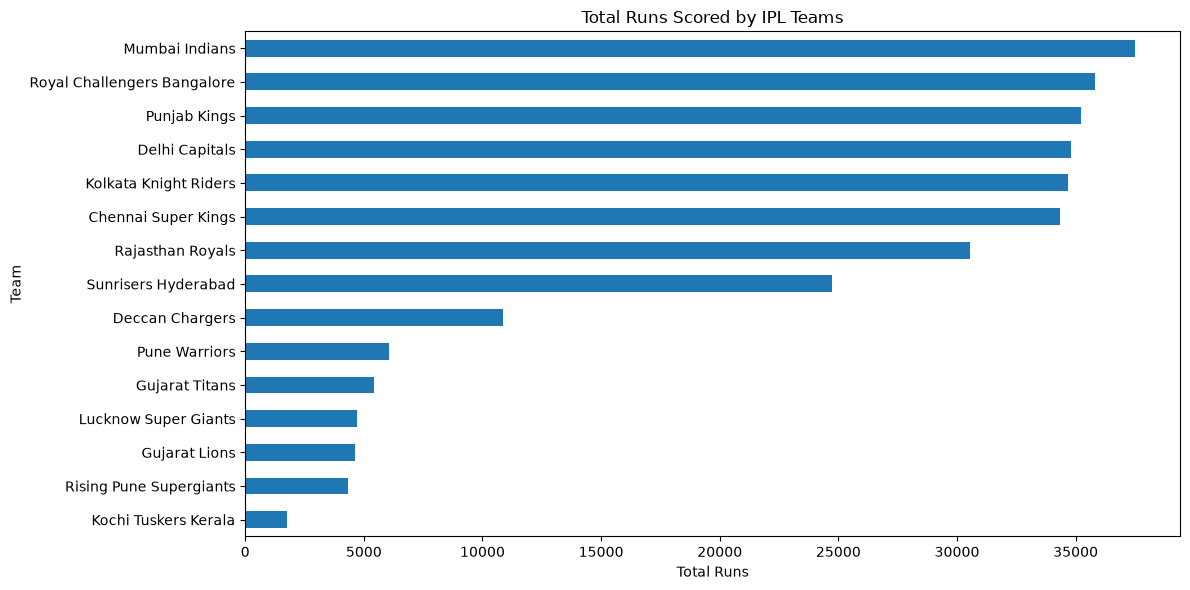

In [49]:
plt.figure(figsize=(12, 6))

team_runs.sort_values().plot(kind="barh")

plt.title("Total Runs Scored by IPL Teams")
plt.xlabel("Total Runs")
plt.ylabel("Team")

plt.tight_layout()
plt.show()

In [50]:
wickets = df[df["wicket_type"] != "No Wicket"]

team_wickets = (
    wickets.groupby("bowling_team")
           .size()
           .sort_values(ascending=False)
)

print(team_wickets)

bowling_team
Mumbai Indians                 1506
Royal Challengers Bangalore    1406
Chennai Super Kings            1402
Delhi Capitals                 1399
Kolkata Knight Riders          1354
Punjab Kings                   1310
Rajasthan Royals               1181
Sunrisers Hyderabad             991
Deccan Chargers                 446
Pune Warriors                   238
Gujarat Titans                  227
Lucknow Super Giants            193
Rising Pune Supergiants         189
Gujarat Lions                   151
Kochi Tuskers Kerala             74
dtype: int64


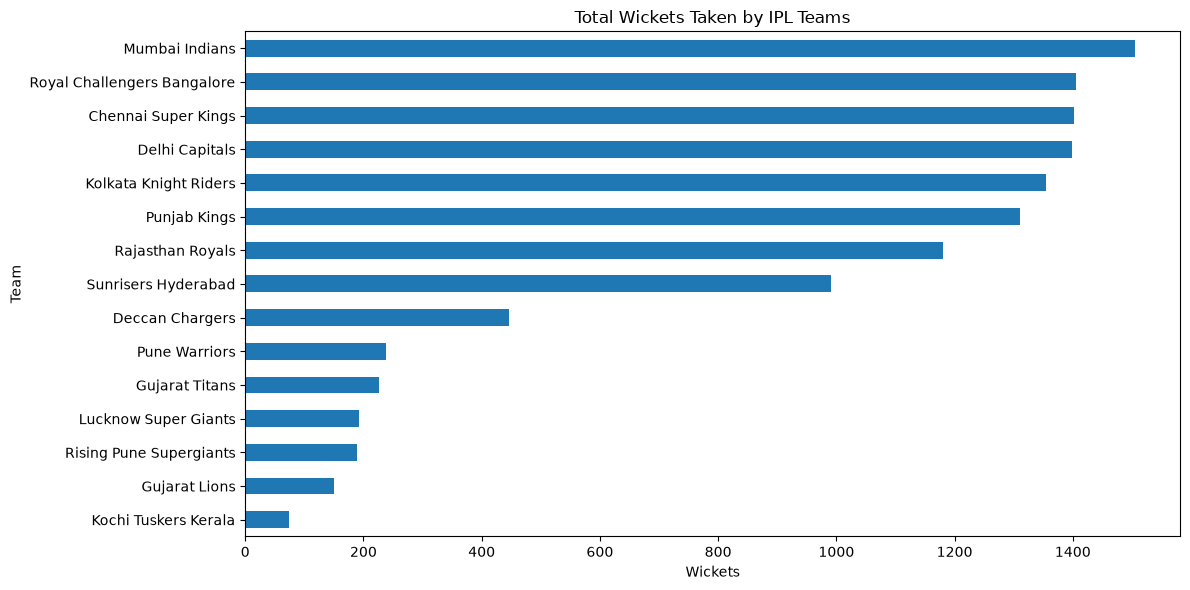

In [51]:
plt.figure(figsize=(12, 6))

team_wickets.sort_values().plot(kind="barh")

plt.title("Total Wickets Taken by IPL Teams")
plt.xlabel("Wickets")
plt.ylabel("Team")

plt.tight_layout()
plt.show()

In [52]:
batting_matches = df.groupby("batting_team")["match_id"].nunique()
bowling_matches = df.groupby("bowling_team")["match_id"].nunique()

team_activity = pd.DataFrame({
    "Batting Matches": batting_matches,
    "Bowling Matches": bowling_matches
})

team_activity["Total Appearances"] = (
    team_activity["Batting Matches"] +
    team_activity["Bowling Matches"]
)

team_activity = team_activity.sort_values(
    "Total Appearances",
    ascending=False
)

print(team_activity)

                             Batting Matches  Bowling Matches  \
Mumbai Indians                           247              247   
Royal Challengers Bangalore              240              239   
Delhi Capitals                           238              237   
Kolkata Knight Riders                    237              237   
Punjab Kings                             232              232   
Chennai Super Kings                      223              224   
Rajasthan Royals                         205              206   
Sunrisers Hyderabad                      166              166   
Deccan Chargers                           75               75   
Pune Warriors                             45               46   
Gujarat Titans                            33               33   
Rising Pune Supergiants                   30               30   
Gujarat Lions                             30               30   
Lucknow Super Giants                      30               29   
Kochi Tuskers Kerala     

In [53]:
team_match_runs = (
    df.groupby(["match_id", "batting_team"])["runs_off_bat"]
      .sum()
      .reset_index()
)

avg_team_runs = (
    team_match_runs.groupby("batting_team")["runs_off_bat"]
                   .mean()
                   .sort_values(ascending=False)
)

print(avg_team_runs)

batting_team
Gujarat Titans                 164.333333
Lucknow Super Giants           157.700000
Gujarat Lions                  154.300000
Chennai Super Kings            153.964126
Mumbai Indians                 151.914980
Punjab Kings                   151.771552
Royal Challengers Bangalore    149.208333
Sunrisers Hyderabad            149.006024
Rajasthan Royals               148.980488
Kolkata Knight Riders          146.278481
Delhi Capitals                 146.159664
Deccan Chargers                145.133333
Rising Pune Supergiants        144.400000
Pune Warriors                  134.222222
Kochi Tuskers Kerala           125.571429
Name: runs_off_bat, dtype: float64


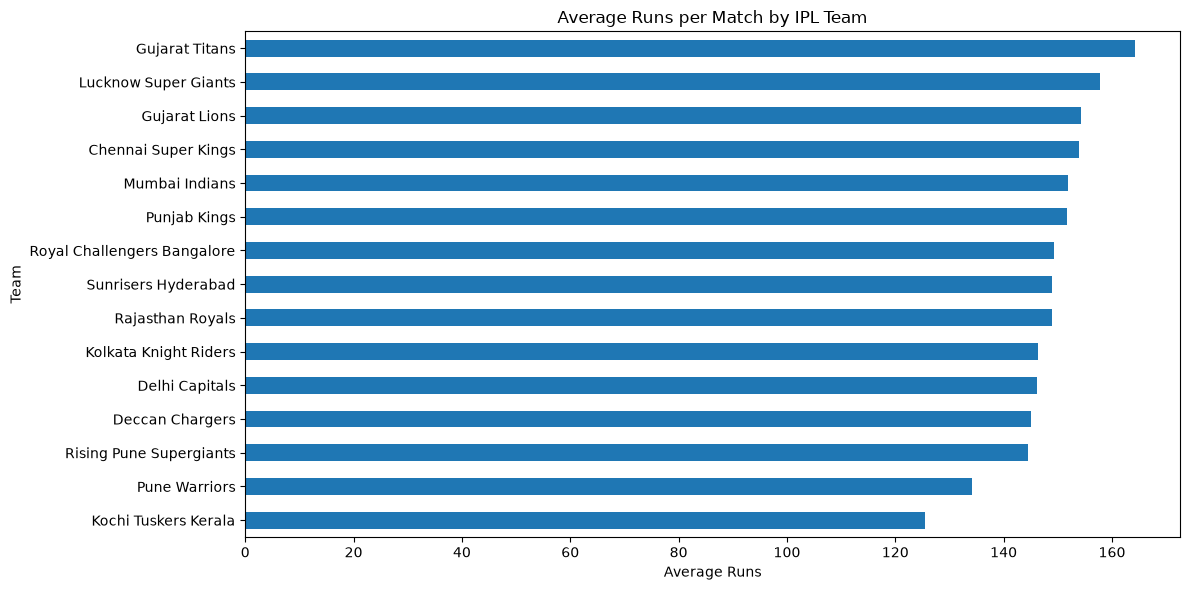

In [54]:
plt.figure(figsize=(12, 6))

avg_team_runs.sort_values().plot(kind="barh")

plt.title("Average Runs per Match by IPL Team")
plt.xlabel("Average Runs")
plt.ylabel("Team")

plt.tight_layout()
plt.show()

In [55]:
top_batters = (
    df.groupby("striker")["runs_off_bat"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_batters)

striker
V Kohli           7273
S Dhawan          6617
DA Warner         6399
RG Sharma         6213
SK Raina          5536
AB de Villiers    5181
MS Dhoni          5082
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4517
Name: runs_off_bat, dtype: int64


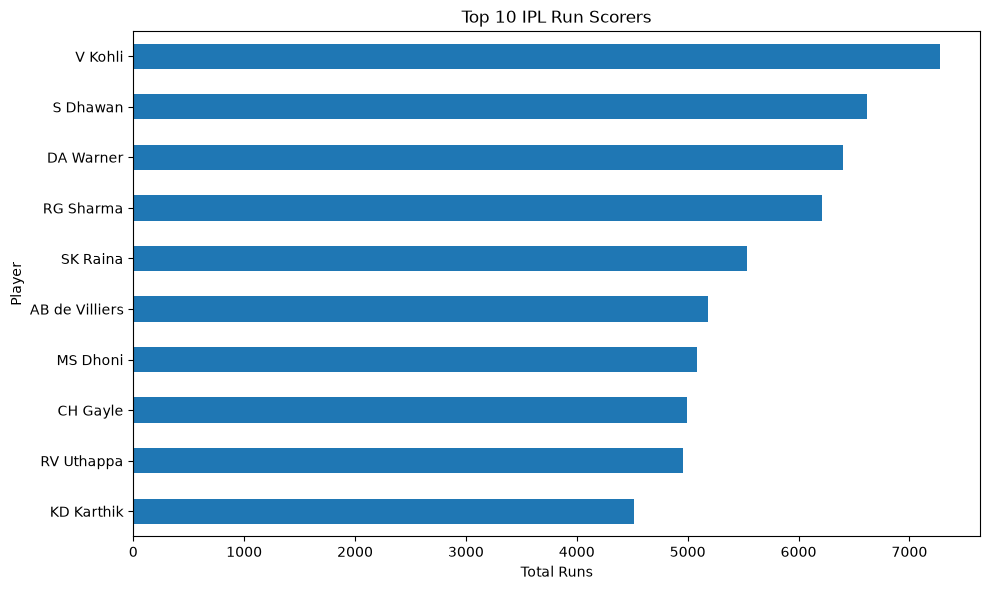

In [56]:
plt.figure(figsize=(10, 6))

top_batters.sort_values().plot(kind="barh")

plt.title("Top 10 IPL Run Scorers")
plt.xlabel("Total Runs")
plt.ylabel("Player")

plt.tight_layout()
plt.show()

In [57]:
top_bowlers = (
    wickets.groupby("bowler")
           .size()
           .sort_values(ascending=False)
           .head(10)
)

print(top_bowlers)

bowler
DJ Bravo      207
YS Chahal     194
R Ashwin      189
SL Malinga    188
PP Chawla     188
B Kumar       184
SP Narine     182
A Mishra      182
RA Jadeja     161
JJ Bumrah     161
dtype: int64


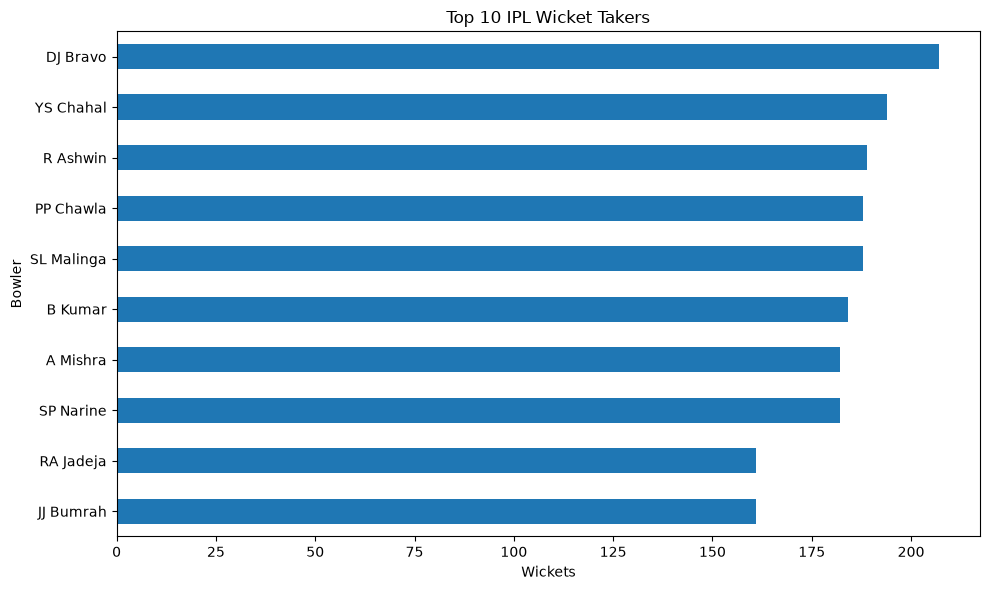

In [58]:
plt.figure(figsize=(10, 6))

top_bowlers.sort_values().plot(kind="barh")

plt.title("Top 10 IPL Wicket Takers")
plt.xlabel("Wickets")
plt.ylabel("Bowler")

plt.tight_layout()
plt.show()

In [59]:
bowler_wicket_types = [
    "bowled",
    "caught",
    "caught and bowled",
    "lbw",
    "stumped",
    "hit wicket"
]

bowler_wickets = df[
    df["wicket_type"].isin(bowler_wicket_types)
]

top_bowlers = (
    bowler_wickets.groupby("bowler")
                  .size()
                  .sort_values(ascending=False)
                  .head(10)
)

print(top_bowlers)

bowler
YS Chahal          187
DJ Bravo           183
PP Chawla          179
A Mishra           173
R Ashwin           171
SL Malinga         170
B Kumar            170
SP Narine          163
RA Jadeja          152
Harbhajan Singh    150
dtype: int64


In [60]:
venue_matches = (
    df.groupby("venue")["match_id"]
      .nunique()
      .sort_values(ascending=False)
      .head(15)
)

print(venue_matches)

venue
Eden Gardens                                  77
Wankhede Stadium                              73
M Chinnaswamy Stadium                         65
Feroz Shah Kotla                              60
Rajiv Gandhi International Stadium, Uppal     49
MA Chidambaram Stadium, Chepauk               48
Sawai Mansingh Stadium                        47
Dubai International Cricket Stadium           46
Wankhede Stadium, Mumbai                      38
Punjab Cricket Association Stadium, Mohali    35
Sheikh Zayed Stadium                          29
Sharjah Cricket Stadium                       28
Maharashtra Cricket Association Stadium       22
Dr DY Patil Sports Academy, Mumbai            20
MA Chidambaram Stadium, Chepauk, Chennai      19
Name: match_id, dtype: int64


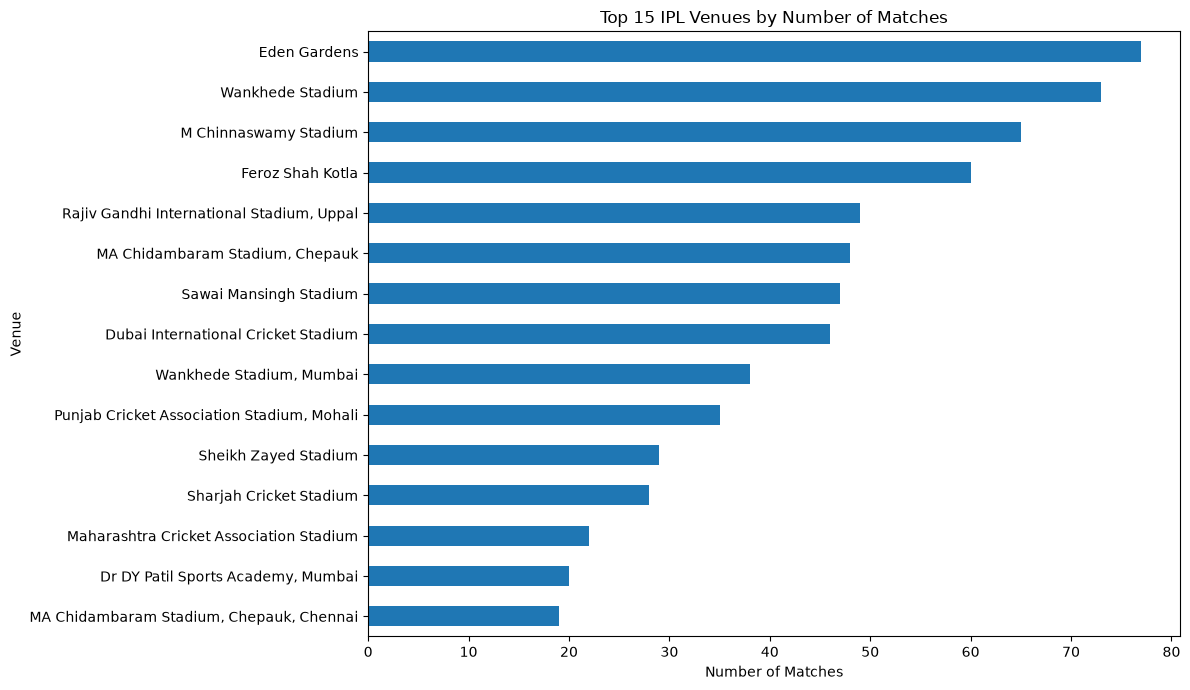

In [61]:
plt.figure(figsize=(12, 7))

venue_matches.sort_values().plot(kind="barh")

plt.title("Top 15 IPL Venues by Number of Matches")
plt.xlabel("Number of Matches")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

In [62]:
match_venue_runs = (
    df.groupby(["match_id", "venue"])["runs_off_bat"]
      .sum()
      .reset_index()
)

avg_venue_runs = (
    match_venue_runs.groupby("venue")["runs_off_bat"]
                    .mean()
                    .sort_values(ascending=False)
)

print(avg_venue_runs.head(15))

venue
Himachal Pradesh Cricket Association Stadium, Dharamsala            378.500000
M Chinnaswamy Stadium, Bengaluru                                    363.285714
Punjab Cricket Association IS Bindra Stadium, Mohali, Chandigarh    351.600000
Eden Gardens, Kolkata                                               350.000000
Barsapara Cricket Stadium, Guwahati                                 347.000000
Punjab Cricket Association IS Bindra Stadium                        333.400000
Arun Jaitley Stadium, Delhi                                         332.454545
M.Chinnaswamy Stadium                                               326.400000
Brabourne Stadium                                                   326.200000
Wankhede Stadium, Mumbai                                            324.631579
Narendra Modi Stadium, Ahmedabad                                    324.562500
Brabourne Stadium, Mumbai                                           323.352941
Rajiv Gandhi International Stadium, Uppal, Hyd

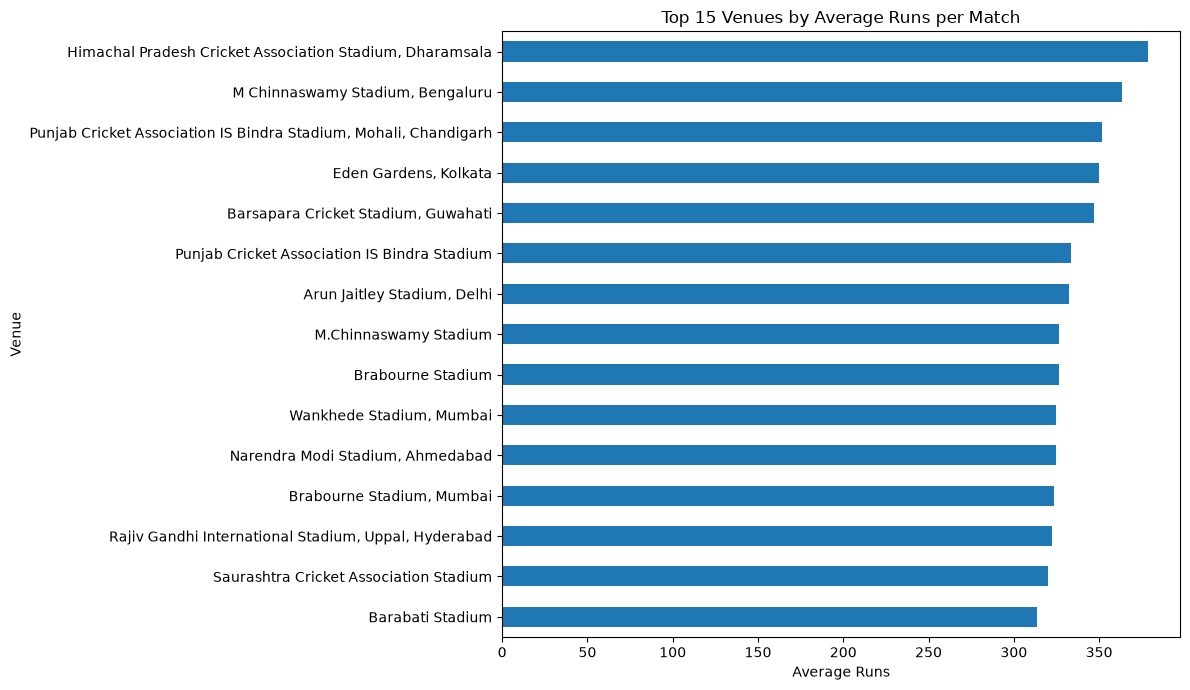

In [63]:
plt.figure(figsize=(12, 7))

avg_venue_runs.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Venues by Average Runs per Match")
plt.xlabel("Average Runs")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

In [64]:
print("Total unique venues:", df["venue"].nunique())

for venue in sorted(df["venue"].unique()):
    print(venue)

Total unique venues: 56
Arun Jaitley Stadium
Arun Jaitley Stadium, Delhi
Barabati Stadium
Barsapara Cricket Stadium, Guwahati
Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow
Brabourne Stadium
Brabourne Stadium, Mumbai
Buffalo Park
De Beers Diamond Oval
Dr DY Patil Sports Academy
Dr DY Patil Sports Academy, Mumbai
Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium
Dubai International Cricket Stadium
Eden Gardens
Eden Gardens, Kolkata
Feroz Shah Kotla
Green Park
Himachal Pradesh Cricket Association Stadium
Himachal Pradesh Cricket Association Stadium, Dharamsala
Holkar Cricket Stadium
JSCA International Stadium Complex
Kingsmead
M Chinnaswamy Stadium
M Chinnaswamy Stadium, Bengaluru
M.Chinnaswamy Stadium
MA Chidambaram Stadium
MA Chidambaram Stadium, Chepauk
MA Chidambaram Stadium, Chepauk, Chennai
Maharashtra Cricket Association Stadium
Maharashtra Cricket Association Stadium, Pune
Narendra Modi Stadium, Ahmedabad
Nehru Stadium
New Wanderers Stadium
Newlands
OUTsu

In [65]:
venue_mapping = {
    "Wankhede Stadium, Mumbai": "Wankhede Stadium",
    "M.Chinnaswamy Stadium": "M Chinnaswamy Stadium",
    ...
}

df["venue"] = df["venue"].replace(venue_mapping)

SyntaxError: ':' expected after dictionary key (43486036.py, line 4)

In [ ]:
print("Total unique venues:", df["venue"].nunique())

for venue in sorted(df["venue"].unique()):
    print(venue)

In [ ]:
venue_mapping = {
    "Wankhede Stadium, Mumbai": "Wankhede Stadium",
    "M.Chinnaswamy Stadium": "M Chinnaswamy Stadium",
    "M Chinnaswamy Stadium, Bengaluru": "M Chinnaswamy Stadium",
    "Eden Gardens, Kolkata": "Eden Gardens",
    "Wankhede Stadium": "Wankhede Stadium",
    "Eden Gardens": "Eden Gardens"
}

df["venue"] = df["venue"].replace(venue_mapping)

print("Venue names cleaned successfully!")
print("Total unique venues:", df["venue"].nunique())

In [ ]:
print("Total unique venues:", df["venue"].nunique())

for i, venue in enumerate(sorted(df["venue"].unique()), 1):
    print(f"{i}. {venue}")

In [ ]:
venue_counts = (
    df.groupby("venue")["match_id"]
      .nunique()
      .sort_values(ascending=False)
)

print(venue_counts)

In [ ]:
venue_mapping = {
    # Delhi
    "Arun Jaitley Stadium, Delhi": "Arun Jaitley Stadium",
    "Feroz Shah Kotla": "Arun Jaitley Stadium",

    # Mumbai
    "Brabourne Stadium, Mumbai": "Brabourne Stadium",
    "Dr DY Patil Sports Academy, Mumbai": "Dr DY Patil Sports Academy",

    # Dharamsala
    "Himachal Pradesh Cricket Association Stadium, Dharamsala":
        "Himachal Pradesh Cricket Association Stadium",

    # Chennai
    "MA Chidambaram Stadium, Chepauk":
        "MA Chidambaram Stadium",
    "MA Chidambaram Stadium, Chepauk, Chennai":
        "MA Chidambaram Stadium",

    # Pune
    "Maharashtra Cricket Association Stadium, Pune":
        "Maharashtra Cricket Association Stadium",
    "Subrata Roy Sahara Stadium":
        "Maharashtra Cricket Association Stadium",

    # Mohali
    "Punjab Cricket Association IS Bindra Stadium, Mohali":
        "Punjab Cricket Association IS Bindra Stadium",
    "Punjab Cricket Association IS Bindra Stadium, Mohali, Chandigarh":
        "Punjab Cricket Association IS Bindra Stadium",
    "Punjab Cricket Association Stadium, Mohali":
        "Punjab Cricket Association IS Bindra Stadium",

    # Hyderabad
    "Rajiv Gandhi International Stadium, Uppal":
        "Rajiv Gandhi International Stadium",
    "Rajiv Gandhi International Stadium, Uppal, Hyderabad":
        "Rajiv Gandhi International Stadium",

    # Jaipur
    "Sawai Mansingh Stadium, Jaipur":
        "Sawai Mansingh Stadium",

    # Ahmedabad
    "Sardar Patel Stadium, Motera":
        "Narendra Modi Stadium, Ahmedabad",

    # Abu Dhabi
    "Zayed Cricket Stadium, Abu Dhabi":
        "Sheikh Zayed Stadium"
}

df["venue"] = df["venue"].replace(venue_mapping)

print("Venue cleaning completed!")
print("Total unique venues:", df["venue"].nunique())

In [ ]:
for i, venue in enumerate(sorted(df["venue"].unique()), 1):
    print(f"{i}. {venue}")

In [ ]:
venue_matches = (
    df.groupby("venue")["match_id"]
      .nunique()
      .sort_values(ascending=False)
)

print(venue_matches.head(15))

In [ ]:
plt.figure(figsize=(12, 7))

venue_matches.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 IPL Venues by Number of Matches")
plt.xlabel("Number of Matches")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

In [ ]:
match_venue_runs = (
    df.groupby(["match_id", "venue"])["runs_off_bat"]
      .sum()
      .reset_index()
)

avg_venue_runs = (
    match_venue_runs.groupby("venue")["runs_off_bat"]
                    .mean()
                    .sort_values(ascending=False)
)

print(avg_venue_runs.head(15))

In [ ]:
plt.figure(figsize=(12, 7))

avg_venue_runs.head(15).sort_values().plot(kind="barh")

plt.title("Top 15 Venues by Average Runs per Match")
plt.xlabel("Average Runs")
plt.ylabel("Venue")

plt.tight_layout()
plt.show()

In [ ]:
print("Total unique venues:", df["venue"].nunique())

In [ ]:
for i, venue in enumerate(sorted(df["venue"].unique()), 1):
    print(f"{i}. {venue}")

In [ ]:
total_bat_runs = df["runs_off_bat"].sum()
total_extras = df["extras"].sum()
total_runs = total_bat_runs + total_extras

print("Total Batting Runs:", total_bat_runs)
print("Total Extras:", total_extras)
print("Total Runs:", total_runs)

In [ ]:
run_distribution = (
    df["runs_off_bat"]
      .value_counts()
      .sort_index()
)

print(run_distribution)

In [ ]:
plt.figure(figsize=(10, 6))

run_distribution.plot(kind="bar")

plt.title("Distribution of Runs per Ball")
plt.xlabel("Runs Scored from Bat")
plt.ylabel("Number of Deliveries")

plt.tight_layout()
plt.show()

In [ ]:
fours = (df["runs_off_bat"] == 4).sum()

print("Total Fours:", fours)

In [ ]:
sixes = (df["runs_off_bat"] == 6).sum()

print("Total Sixes:", sixes)

In [ ]:
boundary_data = pd.Series({
    "Fours": fours,
    "Sixes": sixes
})

print(boundary_data)

In [ ]:
boundary_data = pd.Series({
    "Fours": fours,
    "Sixes": sixes
})

print(boundary_data)

In [ ]:
plt.figure(figsize=(8, 5))

boundary_data.plot(kind="bar")

plt.title("IPL Boundaries: Fours vs Sixes")
plt.xlabel("Boundary Type")
plt.ylabel("Number of Boundaries")

plt.tight_layout()
plt.show()

In [ ]:
season_runs = (
    df.groupby("season")["runs_off_bat"]
      .sum()
)

print(season_runs)

In [ ]:
plt.figure(figsize=(12, 6))

season_runs.plot(kind="line", marker="o")

plt.title("Total IPL Runs by Season")
plt.xlabel("Season")
plt.ylabel("Runs")

plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
match_runs = (
    df.groupby(["season", "match_id"])["runs_off_bat"]
      .sum()
      .reset_index()
)

avg_season_runs = (
    match_runs.groupby("season")["runs_off_bat"]
              .mean()
)

print(avg_season_runs)

In [ ]:
plt.figure(figsize=(12, 6))

avg_season_runs.plot(kind="line", marker="o")

plt.title("Average Runs per Match by IPL Season")
plt.xlabel("Season")
plt.ylabel("Average Runs per Match")

plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Total wickets/dismissals
total_wickets = df["player_dismissed"].notna().sum()

print("Total Wickets:", total_wickets)

In [ ]:
print(df.columns.tolist())

In [ ]:
dismissal_counts = (
    df["dismissal_kind"]
    .dropna()
    .value_counts()
)

print(dismissal_counts)

In [ ]:
print(df.columns.tolist())

In [ ]:
wicket_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in ["wicket", "dismiss", "player_dismiss"])
]

print("Wicket-related columns:")
print(wicket_columns)

In [ ]:
dismissal_counts = (
    df["wicket_type"]
    .dropna()
    .value_counts()
)

print("Dismissal Types:")
print(dismissal_counts)

In [ ]:
import matplotlib.pyplot as plt

dismissal_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("IPL Wickets by Dismissal Type")
plt.xlabel("Dismissal Type")
plt.ylabel("Number of Wickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
total_wickets = df["player_dismissed"].notna().sum()

print("Total Wickets:", total_wickets)

In [ ]:
bowler_wicket_types = [
    "bowled",
    "caught",
    "caught and bowled",
    "lbw",
    "stumped",
    "hit wicket"
]

bowler_wickets = (
    df[df["wicket_type"].isin(bowler_wicket_types)]
    .groupby("bowler")
    .size()
    .sort_values(ascending=False)
)

print("Top 10 Wicket-Taking Bowlers:")
print(bowler_wickets.head(10))

In [ ]:
top_10_bowlers = bowler_wickets.head(10).sort_values()

top_10_bowlers.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 IPL Wicket-Taking Bowlers")
plt.xlabel("Wickets")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()

In [ ]:
season_wickets = (
    df[df["wicket_type"].notna()]
    .groupby("season")["wicket_type"]
    .count()
)

print("Wickets by IPL Season:")
print(season_wickets)

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    season_wickets.index,
    season_wickets.values,
    marker="o"
)

plt.title("Total IPL Wickets by Season")
plt.xlabel("Season")
plt.ylabel("Total Wickets")
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
print(df.columns.tolist())

print([
    col for col in df.columns
    if any(word in col.lower() for word in ["wicket", "dismiss", "player_dismiss"])
])

In [ ]:
import matplotlib.pyplot as plt

# ==========================================
# STEP 3.9 - WICKET ANALYSIS
# ==========================================

# 1. Total Wickets
total_wickets = df["player_dismissed"].notna().sum()

print("=" * 50)
print("STEP 3.9 - WICKET ANALYSIS")
print("=" * 50)

print("\nTotal Wickets:", total_wickets)


# 2. Wickets by Dismissal Type
wicket_types = (
    df["wicket_type"]
    .dropna()
    .value_counts()
)

print("\nWickets by Dismissal Type:")
print(wicket_types)


# 3. Top 10 Wicket-Taking Bowlers
bowler_wicket_types = [
    "bowled",
    "caught",
    "caught and bowled",
    "lbw",
    "stumped",
    "hit wicket"
]

bowler_wickets = (
    df[df["wicket_type"].isin(bowler_wicket_types)]
    .groupby("bowler")
    .size()
    .sort_values(ascending=False)
)

print("\nTop 10 Wicket-Taking Bowlers:")
print(bowler_wickets.head(10))


# 4. Wickets by Season
season_wickets = (
    df[df["wicket_type"].notna()]
    .groupby("season")["wicket_type"]
    .count()
)

print("\nWickets by IPL Season:")
print(season_wickets)


# 5. Matches per Season
matches_per_season = (
    df.groupby("season")["match_id"]
    .nunique()
)


# 6. Average Wickets per Match
wickets_per_match = (
    season_wickets / matches_per_season
)

print("\nAverage Wickets per Match:")
print(wickets_per_match)

In [ ]:
import pandas as pd

df = pd.read_csv("IPL_ball_by_ball_cleaned.csv")

print(df.shape)
print(df.columns.tolist())

In [ ]:
print(df["wicket_type"].value_counts())

In [ ]:
import pandas as pd

df = pd.read_csv("IPL_ball_by_ball_cleaned.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

In [ ]:
actual_wickets = (df["wicket_type"] != "No Wicket").sum()

print("Actual Total Wickets:", actual_wickets)

In [ ]:
wicket_types = (
    df[df["wicket_type"] != "No Wicket"]
    ["wicket_type"]
    .value_counts()
)

print("Wicket Type Distribution:")
print(wicket_types)

In [ ]:
import matplotlib.pyplot as plt

wicket_types.plot(kind="bar", figsize=(10, 5))

plt.title("Wicket Types Distribution")
plt.xlabel("Wicket Type")
plt.ylabel("Number of Wickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
season_wickets = (
    df[df["wicket_type"] != "No Wicket"]
    .groupby("season")["wicket_type"]
    .count()
)

print("Actual Wickets by IPL Season:")
print(season_wickets)

In [ ]:
matches_per_season = df.groupby("season")["match_id"].nunique()

wickets_per_match = season_wickets / matches_per_season

print("Average Wickets per Match:")
print(wickets_per_match.round(2))

In [ ]:
plt.figure(figsize=(10, 5))

wickets_per_match.plot(
    kind="line",
    marker="o"
)

plt.title("Average Wickets per Match by IPL Season")
plt.xlabel("Season")
plt.ylabel("Average Wickets per Match")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
matches_per_season = df.groupby("season")["match_id"].nunique()

wickets_per_match = season_wickets / matches_per_season

print("Average Wickets per Match:")
print(wickets_per_match.round(2))

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

wickets_per_match.plot(
    kind="line",
    marker="o"
)

plt.title("Average Wickets per Match by IPL Season")
plt.xlabel("Season")
plt.ylabel("Average Wickets per Match")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
bowler_wickets = (
    df[
        df["wicket_type"].isin([
            "caught",
            "bowled",
            "lbw",
            "caught and bowled",
            "stumped",
            "hit wicket"
        ])
    ]
    .groupby("bowler")["wicket_type"]
    .count()
    .sort_values(ascending=False)
)

print("Top 10 Wicket-Taking Bowlers:")
print(bowler_wickets.head(10))

In [ ]:
top_10_bowlers = bowler_wickets.head(10)

plt.figure(figsize=(10, 6))

top_10_bowlers.sort_values().plot(kind="barh")

plt.title("Top 10 Wicket-Taking Bowlers in IPL")
plt.xlabel("Wickets")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()

In [ ]:
# ==============================
# FINAL IPL EDA SUMMARY
# ==============================

total_matches = df["match_id"].nunique()
total_seasons = df["season"].nunique()

total_batting_runs = df["runs_off_bat"].sum()
total_extras = df["extras"].sum()
total_runs = total_batting_runs + total_extras

total_wickets = (df["wicket_type"] != "No Wicket").sum()

# Highest scoring team
team_runs = (
    df.groupby("batting_team")["runs_off_bat"]
    .sum()
    .sort_values(ascending=False)
)

highest_scoring_team = team_runs.index[0]
highest_team_runs = team_runs.iloc[0]

# Most common wicket type
most_common_wicket = wicket_types.index[0]
most_common_wicket_count = wicket_types.iloc[0]

# Top wicket-taking bowler
top_bowler = bowler_wickets.index[0]
top_bowler_wickets = bowler_wickets.iloc[0]

# Highest average wickets per match season
highest_avg_season = wickets_per_match.idxmax()
highest_avg_wickets = wickets_per_match.max()

# Lowest average wickets per match season
lowest_avg_season = wickets_per_match.idxmin()
lowest_avg_wickets = wickets_per_match.min()

# Summary
eda_summary = {
    "Total Matches": total_matches,
    "Total Seasons": total_seasons,
    "Total Batting Runs": total_batting_runs,
    "Total Extras": total_extras,
    "Total Runs": total_runs,
    "Total Wickets": total_wickets,
    "Highest Scoring Team": highest_scoring_team,
    "Highest Team Runs": highest_team_runs,
    "Most Common Wicket Type": most_common_wicket,
    "Most Common Wicket Count": most_common_wicket_count,
    "Top Wicket-Taking Bowler": top_bowler,
    "Top Bowler Wickets": top_bowler_wickets,
    "Highest Avg Wickets Season": highest_avg_season,
    "Highest Avg Wickets/Match": round(highest_avg_wickets, 2),
    "Lowest Avg Wickets Season": lowest_avg_season,
    "Lowest Avg Wickets/Match": round(lowest_avg_wickets, 2)
}

for key, value in eda_summary.items():
    print(f"{key}: {value}")

In [ ]:
match_info = (
    df.groupby("match_id")
    .agg({
        "season": "first",
        "start_date": "first",
        "venue": "first"
    })
    .reset_index()
)

print(match_info.head())
print("Total matches:", len(match_info))

In [ ]:
match_teams = (
    df.groupby("match_id")
    .agg({
        "batting_team": "unique",
        "bowling_team": "unique"
    })
    .reset_index()
)

print(match_teams.head(10))

In [ ]:
match_teams["batting_team_count"] = match_teams["batting_team"].apply(len)
match_teams["bowling_team_count"] = match_teams["bowling_team"].apply(len)

print(match_teams[
    (match_teams["batting_team_count"] != 2) |
    (match_teams["bowling_team_count"] != 2)
])

In [ ]:
team_scores = (
    df.groupby(["match_id", "batting_team"])["runs_off_bat"]
    .sum()
    .reset_index()
)

print(team_scores.head(10))

In [ ]:
team_scores = (
    df.groupby(["match_id", "batting_team"])["runs_off_bat"]
    .sum()
    .reset_index()
)

print(team_scores.head(10))

In [ ]:
# Add rank within each match based on score
team_scores["rank"] = (
    team_scores.groupby("match_id")["runs_off_bat"]
    .rank(method="min", ascending=False)
)

print(team_scores.head(10))

In [ ]:
tied_matches = (
    team_scores.groupby("match_id")["runs_off_bat"]
    .nunique()
)

print("Matches with tied scores:", (tied_matches == 1).sum())

In [ ]:
# Rank teams in each match based on their score

team_scores["rank"] = (
    team_scores.groupby("match_id")["runs_off_bat"]
    .rank(method="min", ascending=False)
)

print(team_scores.head(10))

In [ ]:
# Check matches where both teams have the same score

tied_matches = (
    team_scores.groupby("match_id")["runs_off_bat"]
    .nunique()
)

print("Matches with tied scores:", (tied_matches == 1).sum())

In [ ]:
team_scores = (
    df.groupby(["match_id", "batting_team"])
    .agg(
        batting_runs=("runs_off_bat", "sum"),
        extras=("extras", "sum")
    )
    .reset_index()
)

team_scores["total_score"] = (
    team_scores["batting_runs"] + team_scores["extras"]
)

print(team_scores.head(10))

In [ ]:
score_counts = (
    team_scores.groupby("match_id")["total_score"]
    .nunique()
)

print(
    "Matches with tied total scores:",
    (score_counts == 1).sum()
)

In [ ]:
innings_per_match = (
    df.groupby("match_id")["innings"]
    .nunique()
)

print("Innings distribution:")
print(innings_per_match.value_counts().sort_index())

In [ ]:
tied_match_ids = score_counts[score_counts == 1].index

print("Tied Match IDs:")
print(tied_match_ids.tolist())

In [ ]:
print(
    team_scores[
        team_scores["match_id"].isin(tied_match_ids)
    ]
)

In [ ]:
special_matches = innings_per_match[
    innings_per_match.isin([1, 4, 6])
]

print("Special/Incompleted Matches:")
print(special_matches)

In [ ]:
special_ids = special_matches.index

print(
    df[df["match_id"].isin(special_ids)][
        [
            "match_id",
            "innings",
            "batting_team",
            "bowling_team",
            "runs_off_bat",
            "extras",
            "wicket_type"
        ]
    ].head(50)
)

In [ ]:
innings_scores = (
    df.groupby(
        ["match_id", "innings", "batting_team"]
    )
    .agg(
        batting_runs=("runs_off_bat", "sum"),
        extras=("extras", "sum")
    )
    .reset_index()
)

innings_scores["total_score"] = (
    innings_scores["batting_runs"] +
    innings_scores["extras"]
)

print(
    innings_scores[
        innings_scores["match_id"].isin(special_ids)
    ].to_string(index=False)
)

In [ ]:
df.groupby(["match_id", "batting_team"])

In [ ]:
normal_matches = innings_per_match[
    innings_per_match == 2
].index

normal_scores = innings_scores[
    innings_scores["match_id"].isin(normal_matches)
]

print(normal_scores.head(10).to_string(index=False))

In [ ]:
normal_scores = innings_scores[
    innings_scores["match_id"].isin(normal_matches)
].copy()

# Har normal match mein highest total score wali team = winner
normal_winners = (
    normal_scores.loc[
        normal_scores.groupby("match_id")["total_score"].idxmax()
    ][["match_id", "batting_team", "total_score"]]
    .rename(columns={
        "batting_team": "winner",
        "total_score": "winning_score"
    })
)

print(normal_winners.head(10))
print("Normal matches:", len(normal_winners))

In [ ]:
normal_ties = (
    normal_scores.groupby("match_id")["total_score"]
    .nunique()
)

normal_tied_ids = normal_ties[
    normal_ties == 1
].index

print("Tied normal matches:", len(normal_tied_ids))
print("Match IDs:", normal_tied_ids.tolist())

In [ ]:
special_scores = innings_scores[
    innings_scores["match_id"].isin(special_ids)
].copy()

print(
    special_scores[
        ["match_id", "innings", "batting_team", "total_score"]
    ].to_string(index=False)
)

In [ ]:
normal_winners = (
    normal_scores.loc[
        normal_scores.groupby("match_id")["total_score"].idxmax()
    ][["match_id", "batting_team", "total_score"]]
    .rename(columns={
        "batting_team": "winner",
        "total_score": "winning_score"
    })
)

print("Normal winners:", len(normal_winners))

In [ ]:
extra_matches = innings_per_match[
    innings_per_match.isin([4, 6])
].index

extra_scores = innings_scores[
    innings_scores["match_id"].isin(extra_matches)
].copy()

# Last two innings = final Super Over
last_two = (
    extra_scores
    .sort_values(["match_id", "innings"])
    .groupby("match_id")
    .tail(2)
)

print(last_two[
    ["match_id", "innings", "batting_team", "total_score"]
].to_string(index=False))

In [ ]:
special_winners = []

for match_id, group in last_two.groupby("match_id"):
    
    group = group.sort_values("innings")
    
    team_a = group.iloc[0]["batting_team"]
    score_a = group.iloc[0]["total_score"]
    
    team_b = group.iloc[1]["batting_team"]
    score_b = group.iloc[1]["total_score"]
    
    if score_a > score_b:
        winner = team_a
    elif score_b > score_a:
        winner = team_b
    else:
        winner = None
    
    special_winners.append({
        "match_id": match_id,
        "winner": winner
    })

special_winners = pd.DataFrame(special_winners)

print(special_winners)

In [ ]:
all_winners = pd.concat(
    [
        normal_winners[["match_id", "winner"]],
        special_winners[["match_id", "winner"]]
    ],
    ignore_index=True
)

print("Total winner records:", len(all_winners))
print(all_winners.head(10))

In [ ]:
all_winners = all_winners.dropna(subset=["winner"]).copy()

print("Final labeled matches:", len(all_winners))

In [ ]:
match_level = (
    innings_scores[
        innings_scores["innings"].isin([1, 2])
    ]
    .sort_values(["match_id", "innings"])
    .groupby("match_id")
    .head(2)
    .copy()
)

In [ ]:
match_level = match_level.pivot(
    index="match_id",
    columns="innings",
    values=["batting_team", "total_score"]
)

match_level.columns = [
    f"{col[0]}_{col[1]}"
    for col in match_level.columns
]

match_level = match_level.reset_index()

print(match_level.head())

In [ ]:
match_level = match_level.rename(columns={
    "batting_team_1": "team_1",
    "batting_team_2": "team_2",
    "total_score_1": "team_1_score",
    "total_score_2": "team_2_score"
})

print(match_level.head())

In [ ]:
match_level = match_level.merge(
    all_winners,
    on="match_id",
    how="inner"
)

print("Final ML Match Dataset Shape:", match_level.shape)
print(match_level.head(10))

In [ ]:
match_info = (
    df.groupby("match_id")
    .agg({
        "season": "first",
        "start_date": "first",
        "venue": "first"
    })
    .reset_index()
)

match_level = match_level.merge(
    match_info,
    on="match_id",
    how="left"
)

print(match_level.head())

In [ ]:
match_level["target"] = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

print(match_level[[
    "team_1",
    "team_2",
    "winner",
    "target"
]].head(10))

In [ ]:
print(match_level.columns.tolist())

In [ ]:
match_level = match_level.merge(
    all_winners[["match_id", "winner"]],
    on="match_id",
    how="inner"
)

print(match_level.columns.tolist())
print(match_level.head())

In [ ]:
match_level["target"] = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

print(
    match_level[
        ["team_1", "team_2", "winner", "target"]
    ].head(10)
)

In [ ]:
print("Target Distribution:")
print(match_level["target"].value_counts())

print("\nTarget Percentage:")
print(
    match_level["target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

In [ ]:
print(match_level.columns.tolist())

In [ ]:
match_level = (
    innings_scores[
        innings_scores["innings"].isin([1, 2])
    ]
    .sort_values(["match_id", "innings"])
    .groupby("match_id")
    .head(2)
    .copy()
)

In [ ]:
match_level = match_level.pivot(
    index="match_id",
    columns="innings",
    values=["batting_team", "total_score"]
)

In [ ]:
match_level.columns = [
    f"{col[0]}_{col[1]}"
    for col in match_level.columns
]

match_level = match_level.reset_index()

print(match_level.columns.tolist())

In [ ]:
match_level = match_level.rename(columns={
    "batting_team_1": "team_1",
    "batting_team_2": "team_2",
    "total_score_1": "team_1_score",
    "total_score_2": "team_2_score"
})

print(match_level.head())

In [ ]:
print(match_level.columns.tolist())

In [ ]:
match_level = match_level.merge(
    all_winners[["match_id", "winner"]],
    on="match_id",
    how="inner"
)

print(match_level.columns.tolist())
print(match_level.head(10))
print("Shape:", match_level.shape)

In [ ]:
match_level["target"] = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

print(
    match_level[
        ["team_1", "team_2", "winner", "target"]
    ].head(10)
)

In [ ]:
print("Target Distribution:")
print(match_level["target"].value_counts())

print("\nTarget Percentage:")
print(
    match_level["target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

In [ ]:
match_level = match_level.sort_values("match_id").reset_index(drop=True)

team_wins = {}

team_matches = {}

team1_win_rate = []
team2_win_rate = []

for _, row in match_level.iterrows():

    team1 = row["team_1"]
    team2 = row["team_2"]

    # Previous record BEFORE current match
    t1_wins = team_wins.get(team1, 0)
    t1_matches = team_matches.get(team1, 0)

    t2_wins = team_wins.get(team2, 0)
    t2_matches = team_matches.get(team2, 0)

    # Avoid division by zero
    t1_rate = t1_wins / t1_matches if t1_matches > 0 else 0.5
    t2_rate = t2_wins / t2_matches if t2_matches > 0 else 0.5

    team1_win_rate.append(t1_rate)
    team2_win_rate.append(t2_rate)

    # Update records AFTER calculating features
    winner = row["winner"]

    team_matches[team1] = t1_matches + 1
    team_matches[team2] = t2_matches + 1

    if winner == team1:
        team_wins[team1] = t1_wins + 1
        team_wins[team2] = t2_wins
    else:
        team_wins[team1] = t1_wins
        team_wins[team2] = t2_wins + 1

match_level["team1_win_rate"] = team1_win_rate
match_level["team2_win_rate"] = team2_win_rate

print(
    match_level[
        [
            "team_1",
            "team_2",
            "winner",
            "team1_win_rate",
            "team2_win_rate"
        ]
    ].head(10)
)

In [ ]:
h2h_wins = {}
h2h_matches = {}

team1_h2h_rate = []
team2_h2h_rate = []

for _, row in match_level.iterrows():

    team1 = row["team_1"]
    team2 = row["team_2"]
    winner = row["winner"]

    # Same matchup ko order-independent banate hain
    matchup = tuple(sorted([team1, team2]))

    previous_wins = h2h_wins.get(matchup, {})
    previous_matches = h2h_matches.get(matchup, 0)

    team1_previous_wins = previous_wins.get(team1, 0)
    team2_previous_wins = previous_wins.get(team2, 0)

    if previous_matches > 0:
        team1_rate = team1_previous_wins / previous_matches
        team2_rate = team2_previous_wins / previous_matches
    else:
        team1_rate = 0.5
        team2_rate = 0.5

    team1_h2h_rate.append(team1_rate)
    team2_h2h_rate.append(team2_rate)

    # Update AFTER current match
    h2h_matches[matchup] = previous_matches + 1

    if matchup not in h2h_wins:
        h2h_wins[matchup] = {}

    h2h_wins[matchup][winner] = (
        h2h_wins[matchup].get(winner, 0) + 1
    )

match_level["team1_h2h_rate"] = team1_h2h_rate
match_level["team2_h2h_rate"] = team2_h2h_rate

print(
    match_level[
        [
            "team_1",
            "team_2",
            "winner",
            "team1_h2h_rate",
            "team2_h2h_rate"
        ]
    ].head(15)
)

In [ ]:
import pandas as pd

df = pd.read_csv("IPL_ball_by_ball_cleaned.csv")

print("Dataset loaded:", df.shape)

In [ ]:
innings_scores = (
    df.groupby(["match_id", "innings", "batting_team"])
    .agg(
        batting_runs=("runs_off_bat", "sum"),
        extras=("extras", "sum")
    )
    .reset_index()
)

innings_scores["total_score"] = (
    innings_scores["batting_runs"] + innings_scores["extras"]
)

In [ ]:
match_level = (
    innings_scores[innings_scores["innings"].isin([1, 2])]
    .sort_values(["match_id", "innings"])
    .groupby("match_id")
    .head(2)
    .pivot(
        index="match_id",
        columns="innings",
        values=["batting_team", "total_score"]
    )
)

match_level.columns = [
    f"{col[0]}_{col[1]}" for col in match_level.columns
]

match_level = match_level.reset_index()

match_level = match_level.rename(columns={
    "batting_team_1": "team_1",
    "batting_team_2": "team_2",
    "total_score_1": "team_1_score",
    "total_score_2": "team_2_score"
})

In [ ]:
normal_matches = (
    df.groupby("match_id")["innings"]
    .nunique()
)

normal_ids = normal_matches[normal_matches == 2].index

normal_scores = innings_scores[
    innings_scores["match_id"].isin(normal_ids)
]

normal_winners = (
    normal_scores.loc[
        normal_scores.groupby("match_id")["total_score"].idxmax(),
        ["match_id", "batting_team"]
    ]
    .rename(columns={"batting_team": "winner"})
)

print(normal_winners.head())

In [ ]:
print("match_level exists:", "match_level" in globals())
print("all_winners exists:", "all_winners" in globals())

In [ ]:
# Calculate scores for each innings
innings_scores = (
    df.groupby(["match_id", "innings", "batting_team"])
    .agg(
        batting_runs=("runs_off_bat", "sum"),
        extras=("extras", "sum")
    )
    .reset_index()
)

innings_scores["total_score"] = (
    innings_scores["batting_runs"] + innings_scores["extras"]
)

# Identify matches with exactly 2 innings
innings_per_match = df.groupby("match_id")["innings"].nunique()
normal_ids = innings_per_match[innings_per_match == 2].index

normal_scores = innings_scores[
    innings_scores["match_id"].isin(normal_ids)
]

# Identify winner for normal matches
normal_winners = (
    normal_scores.loc[
        normal_scores.groupby("match_id")["total_score"].idxmax(),
        ["match_id", "batting_team"]
    ]
    .rename(columns={"batting_team": "winner"})
)

print("Normal winners:", len(normal_winners))

In [ ]:
extra_ids = innings_per_match[
    innings_per_match.isin([4, 6])
].index

extra_scores = innings_scores[
    innings_scores["match_id"].isin(extra_ids)
].copy()

last_two = (
    extra_scores
    .sort_values(["match_id", "innings"])
    .groupby("match_id")
    .tail(2)
)

special_winners_list = []

for match_id, group in last_two.groupby("match_id"):
    group = group.sort_values("innings")

    team_a = group.iloc[0]["batting_team"]
    score_a = group.iloc[0]["total_score"]

    team_b = group.iloc[1]["batting_team"]
    score_b = group.iloc[1]["total_score"]

    if score_a > score_b:
        winner = team_a
    elif score_b > score_a:
        winner = team_b
    else:
        winner = None

    special_winners_list.append({
        "match_id": match_id,
        "winner": winner
    })

special_winners = pd.DataFrame(special_winners_list)

print(special_winners)

In [ ]:
all_winners = pd.concat(
    [
        normal_winners[["match_id", "winner"]],
        special_winners[["match_id", "winner"]]
    ],
    ignore_index=True
)

all_winners = all_winners.dropna(subset=["winner"])

# Remove any duplicate match IDs, if present
all_winners = all_winners.drop_duplicates(
    subset=["match_id"],
    keep="first"
)

match_level = match_level.drop(
    columns=["winner", "target"],
    errors="ignore"
)

match_level = match_level.merge(
    all_winners,
    on="match_id",
    how="inner"
)

print("Final match-level shape:", match_level.shape)
print(match_level.columns.tolist())

In [ ]:
match_level["target"] = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

print(
    match_level[
        ["team_1", "team_2", "winner", "target"]
    ].head(10)
)

In [ ]:
# Sort matches chronologically
match_level = match_level.sort_values(
    ["match_id"]
).reset_index(drop=True)

h2h_wins = {}
h2h_matches = {}

team1_h2h_rate = []
team2_h2h_rate = []

for _, row in match_level.iterrows():

    team1 = row["team_1"]
    team2 = row["team_2"]
    winner = row["winner"]

    # Same matchup regardless of team order
    matchup = tuple(sorted([team1, team2]))

    previous_wins = h2h_wins.get(matchup, {})
    previous_matches = h2h_matches.get(matchup, 0)

    t1_wins = previous_wins.get(team1, 0)
    t2_wins = previous_wins.get(team2, 0)

    # Use only previous match results
    if previous_matches > 0:
        t1_rate = t1_wins / previous_matches
        t2_rate = t2_wins / previous_matches
    else:
        t1_rate = 0.5
        t2_rate = 0.5

    team1_h2h_rate.append(t1_rate)
    team2_h2h_rate.append(t2_rate)

    # Update records after feature calculation
    h2h_matches[matchup] = previous_matches + 1

    if matchup not in h2h_wins:
        h2h_wins[matchup] = {}

    if winner == team1:
        h2h_wins[matchup][team1] = (
            h2h_wins[matchup].get(team1, 0) + 1
        )
    elif winner == team2:
        h2h_wins[matchup][team2] = (
            h2h_wins[matchup].get(team2, 0) + 1
        )

match_level["team1_h2h_rate"] = team1_h2h_rate
match_level["team2_h2h_rate"] = team2_h2h_rate

print(
    match_level[
        [
            "team_1",
            "team_2",
            "winner",
            "team1_h2h_rate",
            "team2_h2h_rate"
        ]
    ].head(15)
)

In [ ]:
print(
    match_level[
        ["team1_h2h_rate", "team2_h2h_rate"]
    ].describe()
)

In [ ]:
# Find matches where previous head-to-head history exists
h2h_check = match_level[
    (match_level["team1_h2h_rate"] != 0.5) |
    (match_level["team2_h2h_rate"] != 0.5)
]

print("Matches with previous H2H history:", len(h2h_check))

print(
    h2h_check[
        ["team_1", "team_2", "winner",
         "team1_h2h_rate", "team2_h2h_rate"]
    ].head(15)
)

In [ ]:
print(match_level.columns.tolist())

In [ ]:
# Ensure chronological order
match_level["start_date"] = pd.to_datetime(match_level["start_date"])
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

# Store previous match results for each team
team_history = {}

team1_recent_form = []
team2_recent_form = []

for _, row in match_level.iterrows():
    team1 = row["team_1"]
    team2 = row["team_2"]

    history1 = team_history.get(team1, [])
    history2 = team_history.get(team2, [])

    # Calculate form using only previous 5 matches
    form1 = sum(history1[-5:]) / len(history1[-5:]) if history1 else 0.5
    form2 = sum(history2[-5:]) / len(history2[-5:]) if history2 else 0.5

    team1_recent_form.append(form1)
    team2_recent_form.append(form2)

    # Update history only AFTER calculating current match features
    winner = row["winner"]

    team_history.setdefault(team1, []).append(1 if winner == team1 else 0)
    team_history.setdefault(team2, []).append(1 if winner == team2 else 0)

match_level["team1_recent_form"] = team1_recent_form
match_level["team2_recent_form"] = team2_recent_form

print(match_level[
    ["team_1", "team_2", "winner",
     "team1_recent_form", "team2_recent_form"]
].head(15))

In [ ]:
# Get match date from original dataset
match_info = (
    df.groupby("match_id")
    .agg(
        season=("season", "first"),
        start_date=("start_date", "first"),
        venue=("venue", "first")
    )
    .reset_index()
)

# Remove existing metadata columns if already present
match_level = match_level.drop(
    columns=["season", "start_date", "venue"],
    errors="ignore"
)

# Merge date and venue information
match_level = match_level.merge(
    match_info,
    on="match_id",
    how="left"
)

# Convert start_date to datetime
match_level["start_date"] = pd.to_datetime(
    match_level["start_date"],
    errors="coerce"
)

print(match_level[["match_id", "start_date", "venue"]].head())
print("Missing dates:", match_level["start_date"].isna().sum())

In [ ]:
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

print(match_level[["match_id", "start_date"]].head(10))

In [ ]:
# Sort matches chronologically
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

h2h_wins = {}
h2h_matches = {}

team1_h2h_rate = []
team2_h2h_rate = []

for _, row in match_level.iterrows():
    team1 = row["team_1"]
    team2 = row["team_2"]
    winner = row["winner"]

    matchup = tuple(sorted([team1, team2]))
    previous_wins = h2h_wins.get(matchup, {})
    previous_matches = h2h_matches.get(matchup, 0)

    t1_wins = previous_wins.get(team1, 0)
    t2_wins = previous_wins.get(team2, 0)

    # Use only previous head-to-head matches
    if previous_matches > 0:
        team1_h2h_rate.append(t1_wins / previous_matches)
        team2_h2h_rate.append(t2_wins / previous_matches)
    else:
        team1_h2h_rate.append(0.5)
        team2_h2h_rate.append(0.5)

    # Update history after calculating the features
    h2h_matches[matchup] = previous_matches + 1
    h2h_wins.setdefault(matchup, {})

    if winner == team1:
        h2h_wins[matchup][team1] = t1_wins + 1
    elif winner == team2:
        h2h_wins[matchup][team2] = t2_wins + 1

match_level["team1_h2h_rate"] = team1_h2h_rate
match_level["team2_h2h_rate"] = team2_h2h_rate

print(match_level[
    ["start_date", "team_1", "team_2", "winner",
     "team1_h2h_rate", "team2_h2h_rate"]
].head(15))

In [ ]:
team_history = {}
team1_recent_form = []
team2_recent_form = []

for _, row in match_level.iterrows():
    team1 = row["team_1"]
    team2 = row["team_2"]
    winner = row["winner"]

    history1 = team_history.get(team1, [])
    history2 = team_history.get(team2, [])

    # Win percentage in previous 5 matches
    form1 = (
        sum(history1[-5:]) / len(history1[-5:])
        if history1 else 0.5
    )
    form2 = (
        sum(history2[-5:]) / len(history2[-5:])
        if history2 else 0.5
    )

    team1_recent_form.append(form1)
    team2_recent_form.append(form2)

    # Add current result only after calculating recent form
    team_history.setdefault(team1, []).append(
        1 if winner == team1 else 0
    )
    team_history.setdefault(team2, []).append(
        1 if winner == team2 else 0
    )

match_level["team1_recent_form"] = team1_recent_form
match_level["team2_recent_form"] = team2_recent_form

print(match_level[
    ["start_date", "team_1", "team_2",
     "team1_recent_form", "team2_recent_form"]
].head(15))

In [ ]:
# Check required feature columns
feature_cols = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

print("Missing values:")
print(match_level[feature_cols].isnull().sum())

print("\nFeature summary:")
print(match_level[feature_cols].describe())

In [ ]:
# Create target if not already present
match_level["target"] = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

print("Total labeled matches:", len(match_level))
print("\nTarget distribution:")
print(match_level["target"].value_counts())

print("\nFinal preview:")
print(match_level[
    ["team_1", "team_2", "winner", "target",
     "team1_h2h_rate", "team2_h2h_rate",
     "team1_recent_form", "team2_recent_form"]
].head(10))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Features available before the match
features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

X = match_level[features]
y = match_level["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

In [ ]:
# Keep the latest matches for testing
split_index = int(len(match_level) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict test matches
y_pred = model.predict(X_test)

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))
print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

In [ ]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Numerical features
numeric_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

# Categorical features
categorical_features = [
    "team_1",
    "team_2",
    "venue",
    "season"
]

all_features = numeric_features + categorical_features

# Chronological train-test split
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

split_index = int(len(match_level) * 0.8)

train_data = match_level.iloc[:split_index]
test_data = match_level.iloc[split_index:]

X_train = train_data[all_features]
X_test = test_data[all_features]

y_train = train_data["target"]
y_test = test_data["target"]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

# Build model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))

print(
    "\nImproved Model Accuracy:",
    round(accuracy_score(y_test, y_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(
    "\nMajority-class baseline:",
    round(y_test.value_counts(normalize=True).max() * 100, 2),
    "%"
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
rf_model.fit(X_train, y_train)

# Predict test matches
rf_pred = rf_model.predict(X_test)

print(
    "Random Forest Accuracy:",
    round(accuracy_score(y_test, rf_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(
    y_test, rf_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

In [ ]:
import pandas as pd

# Get feature names after preprocessing
feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get importance scores
importance_scores = (
    rf_model.named_steps["classifier"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Show top 15 features
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15).to_string(index=False))

In [ ]:
from sklearn.metrics import log_loss, roc_auc_score

# Probability of Team 1 winning (class 1)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print("Log Loss:", round(log_loss(y_test, rf_prob), 4))

# Show actual vs predicted results
comparison = pd.DataFrame({
    "Team 1": test_data["team_1"].values,
    "Team 2": test_data["team_2"].values,
    "Actual Winner": test_data["winner"].values,
    "Predicted Winner": [
        t1 if pred == 1 else t2
        for t1, t2, pred in zip(
            test_data["team_1"],
            test_data["team_2"],
            rf_pred
        )
    ],
    "Team 1 Win Probability (%)": (rf_prob * 100).round(2)
})

print("\nSample Predictions:")
print(comparison.head(10).to_string(index=False))

In [ ]:
# Check teams and seasons in the modeling dataset
print("Season range:")
print(match_level["season"].min(), "to", match_level["season"].max())

print("\nTeam names:")
print(sorted(
    set(match_level["team_1"].dropna()) |
    set(match_level["team_2"].dropna())
))

print("\nMatches by season:")
print(match_level.groupby("season").size().sort_index())

In [ ]:
# Check whether every winner matches one of the two teams
valid_winners = (
    (match_level["winner"] == match_level["team_1"]) |
    (match_level["winner"] == match_level["team_2"])
)

print("Total matches:", len(match_level))
print("Valid winner labels:", valid_winners.sum())
print("Invalid winner labels:", (~valid_winners).sum())

print("\nTarget distribution:")
print(match_level["target"].value_counts())

In [ ]:
# Standardize historical IPL team names
team_aliases = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Rising Pune Supergiant": "Rising Pune Supergiants"
}

for col in ["team_1", "team_2", "winner"]:
    match_level[col] = match_level[col].replace(team_aliases)

# Check updated team names
teams = sorted(
    set(match_level["team_1"].dropna()) |
    set(match_level["team_2"].dropna())
)

print("Number of normalized teams:", len(teams))
print("\nNormalized team names:")
print(teams)

# Verify winner consistency after normalization
valid = (
    (match_level["winner"] == match_level["team_1"]) |
    (match_level["winner"] == match_level["team_2"])
)

print("\nValid winner labels:", valid.sum())
print("Invalid winner labels:", (~valid).sum())

In [ ]:
# Ensure chronological order
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

# Historical Head-to-Head
h2h_wins = {}
h2h_matches = {}

team1_h2h_rate = []
team2_h2h_rate = []

# Recent form: previous 5 matches per team
team_history = {}
team1_recent_form = []
team2_recent_form = []

for _, row in match_level.iterrows():
    team1 = row["team_1"]
    team2 = row["team_2"]
    winner = row["winner"]

    # H2H features
    matchup = tuple(sorted([team1, team2]))
    wins = h2h_wins.get(matchup, {})
    total_h2h = h2h_matches.get(matchup, 0)

    if total_h2h:
        team1_h2h_rate.append(wins.get(team1, 0) / total_h2h)
        team2_h2h_rate.append(wins.get(team2, 0) / total_h2h)
    else:
        team1_h2h_rate.append(0.5)
        team2_h2h_rate.append(0.5)

    # Recent form features
    history1 = team_history.get(team1, [])
    history2 = team_history.get(team2, [])

    team1_recent_form.append(
        sum(history1[-5:]) / len(history1[-5:]) if history1 else 0.5
    )
    team2_recent_form.append(
        sum(history2[-5:]) / len(history2[-5:]) if history2 else 0.5
    )

    # Update histories AFTER feature calculation
    h2h_matches[matchup] = total_h2h + 1
    h2h_wins.setdefault(matchup, {})

    if winner == team1:
        h2h_wins[matchup][team1] = wins.get(team1, 0) + 1
    elif winner == team2:
        h2h_wins[matchup][team2] = wins.get(team2, 0) + 1

    team_history.setdefault(team1, []).append(
        1 if winner == team1 else 0
    )
    team_history.setdefault(team2, []).append(
        1 if winner == team2 else 0
    )

# Save features
match_level["team1_h2h_rate"] = team1_h2h_rate
match_level["team2_h2h_rate"] = team2_h2h_rate
match_level["team1_recent_form"] = team1_recent_form
match_level["team2_recent_form"] = team2_recent_form

print(match_level[
    ["start_date", "team_1", "team_2", "winner",
     "team1_h2h_rate", "team2_h2h_rate",
     "team1_recent_form", "team2_recent_form"]
].tail(10))

In [ ]:
print(match_level[
    ["start_date", "team_1", "team_2", "winner",
     "team1_h2h_rate", "team2_h2h_rate",
     "team1_recent_form", "team2_recent_form"]
].tail(10).to_string(index=False))

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    log_loss
)

# Define features
numeric_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

categorical_features = [
    "team_1",
    "team_2",
    "venue",
    "season"
]

all_features = numeric_features + categorical_features

# Sort chronologically
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

# Chronological 80/20 split
split_index = int(len(match_level) * 0.8)

train_data = match_level.iloc[:split_index].copy()
test_data = match_level.iloc[split_index:].copy()

X_train = train_data[all_features]
X_test = test_data[all_features]

y_train = train_data["target"]
y_test = test_data["target"]

# Preprocessing
preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

# Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train and evaluate
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, rf_pred) * 100, 2), "%")
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print("Log Loss:", round(log_loss(y_test, rf_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

In [ ]:
# 1. Recalculate target after team-name normalization
match_level["target"] = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

# 2. Check winner consistency
valid = (
    (match_level["winner"] == match_level["team_1"]) |
    (match_level["winner"] == match_level["team_2"])
)

print("Invalid winner labels:", (~valid).sum())

# 3. Check feature quality
features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

print("\nMissing feature values:")
print(match_level[features].isnull().sum())

print("\nFeature summary:")
print(match_level[features].describe())

# 4. Check chronological split
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

split_index = int(len(match_level) * 0.8)

train_data = match_level.iloc[:split_index]
test_data = match_level.iloc[split_index:]

print("\nTraining date range:")
print(train_data["start_date"].min(), "to",
      train_data["start_date"].max())

print("\nTesting date range:")
print(test_data["start_date"].min(), "to",
      test_data["start_date"].max())

print("\nTraining target distribution:")
print(train_data["target"].value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(test_data["target"].value_counts(normalize=True).round(3))

# 5. Check teams in test data not seen during training
train_teams = set(train_data["team_1"]) | set(train_data["team_2"])
test_teams = set(test_data["team_1"]) | set(test_data["team_2"])

print("\nTeams unseen during training:")
print(sorted(test_teams - train_teams))

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    log_loss
)

# Ensure chronological order
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

# Recalculate target
match_level["target"] = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

# Train on seasons before 2023; test on 2023
train_data = match_level[match_level["season"] < 2023].copy()
test_data = match_level[match_level["season"] == 2023].copy()

numeric_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

categorical_features = [
    "team_1",
    "team_2",
    "venue",
    "season"
]

all_features = numeric_features + categorical_features

X_train = train_data[all_features]
y_train = train_data["target"]

X_test = test_data[all_features]
y_test = test_data["target"]

preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train and predict
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))

print(
    "\n2023 Accuracy:",
    round(accuracy_score(y_test, rf_pred) * 100, 2), "%"
)

print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print("Log Loss:", round(log_loss(y_test, rf_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print(
    "\nMajority baseline:",
    round(y_test.value_counts(normalize=True).max() * 100, 2),
    "%"
)

In [ ]:
# Recalculate innings scores from the original ball-by-ball data
innings_scores = (
    df.groupby(["match_id", "innings", "batting_team"])
    .agg(
        batting_runs=("runs_off_bat", "sum"),
        extras=("extras", "sum")
    )
    .reset_index()
)

innings_scores["total_score"] = (
    innings_scores["batting_runs"] + innings_scores["extras"]
)

# Normalize historical team names
team_aliases = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Rising Pune Supergiant": "Rising Pune Supergiants"
}

innings_scores["batting_team"] = (
    innings_scores["batting_team"].replace(team_aliases)
)

# Select matches with exactly two innings
innings_count = innings_scores.groupby("match_id")["innings"].nunique()
normal_ids = innings_count[innings_count == 2].index

normal_scores = innings_scores[
    innings_scores["match_id"].isin(normal_ids)
].copy()

# Infer the winner from the higher total score
score_winners = (
    normal_scores.loc[
        normal_scores.groupby("match_id")["total_score"].idxmax(),
        ["match_id", "batting_team", "total_score"]
    ]
    .rename(columns={"batting_team": "score_winner"})
)

# Compare inferred score winners with our current labels
comparison = score_winners.merge(
    match_level[["match_id", "winner"]],
    on="match_id",
    how="inner"
)

comparison["winner_match"] = (
    comparison["score_winner"] == comparison["winner"]
)

print("Two-innings matches checked:", len(comparison))
print("Matching winners:", comparison["winner_match"].sum())
print("Mismatching winners:", (~comparison["winner_match"]).sum())

print("\nExamples of mismatches:")
print(
    comparison.loc[~comparison["winner_match"]]
    .head(15)
    .to_string(index=False)
)

In [ ]:
# Identify matches with more than 2 innings
special_ids = innings_count[innings_count > 2].index

special_scores = innings_scores[
    innings_scores["match_id"].isin(special_ids)
].sort_values(["match_id", "innings"])

print("Special matches:", len(special_ids))

print(
    special_scores[
        ["match_id", "innings", "batting_team", "total_score"]
    ].to_string(index=False)
)

In [ ]:
# Expected winners for special matches
special_winners = {
    392190: "Rajasthan Royals",
    419121: "Punjab Kings",
    598004: "Sunrisers Hyderabad",
    598017: "Royal Challengers Bangalore",
    829741: "Punjab Kings",
    1082625: "Mumbai Indians",
    1175365: "Delhi Capitals",
    1178426: "Mumbai Indians",
    1216493: "Delhi Capitals",
    1216512: "Kolkata Knight Riders",
    1216517: "Punjab Kings",
    1216547: "Royal Challengers Bangalore",
    1254077: "Delhi Capitals"
}

# Check current winners
for match_id, expected_winner in special_winners.items():
    actual = match_level.loc[
        match_level["match_id"] == match_id, "winner"
    ]

    if len(actual) == 0:
        print(f"Match {match_id}: NOT FOUND in match_level")
    elif actual.iloc[0] == expected_winner:
        print(f"Match {match_id}: OK")
    else:
        print(
            f"Match {match_id}: MISMATCH | "
            f"Expected: {expected_winner} | "
            f"Current: {actual.iloc[0]}"
        )

# The match tied even after Super Over must be excluded
print(
    "\nMatch 729315 present:",
    729315 in match_level["match_id"].values
)

In [ ]:
# 1. Dataset shape
print("Dataset shape:", match_level.shape)

# 2. Duplicate match IDs
print(
    "Duplicate match IDs:",
    match_level["match_id"].duplicated().sum()
)

# 3. Missing values
print("\nMissing values:")
print(match_level.isnull().sum())

# 4. Target distribution
print("\nTarget distribution:")
print(match_level["target"].value_counts())

print("\nTarget percentage:")
print(
    (match_level["target"].value_counts(normalize=True) * 100)
    .round(2)
)

# 5. Check whether winner matches either playing team
valid_winners = (
    (match_level["winner"] == match_level["team_1"]) |
    (match_level["winner"] == match_level["team_2"])
)

print("\nInvalid winner records:", (~valid_winners).sum())

# 6. Check for the tied match
print(
    "\nTied match 729315 included:",
    729315 in match_level["match_id"].values
)

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Target: 1 means team_1 wins; 0 means team_2 wins
target_col = "target"

# Pre-match features only
numeric_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

categorical_features = [
    "team_1",
    "team_2",
    "venue"
]

features = numeric_features + categorical_features

X = match_level[features].copy()
y = match_level[target_col].copy()

# Chronological train-test split
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

X = match_level[features].copy()
y = match_level[target_col].copy()

split_index = int(len(match_level) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

# Model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

In [ ]:

from collections import defaultdict
import pandas as pd

# Ensure chronological order
match_level["start_date"] = pd.to_datetime(
    match_level["start_date"]
)

match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

# Store results from strictly earlier dates
team_history = defaultdict(list)
h2h_history = defaultdict(lambda: defaultdict(int))
h2h_match_count = defaultdict(int)

t1_h2h, t2_h2h = [], []
t1_form, t2_form = [], []

# Process one date at a time
for date, day_matches in match_level.groupby("start_date", sort=True):

    day_features = []

    # First calculate features for all matches on this date
    # without updating history
    for idx, row in day_matches.iterrows():
        t1, t2 = row["team_1"], row["team_2"]
        pair = tuple(sorted([t1, t2]))

        total = h2h_match_count[pair]

        rate1 = (
            h2h_history[pair][t1] / total
            if total else 0.5
        )
        rate2 = (
            h2h_history[pair][t2] / total
            if total else 0.5
        )

        history1 = team_history[t1][-5:]
        history2 = team_history[t2][-5:]

        form1 = (
            sum(history1) / len(history1)
            if history1 else 0.5
        )
        form2 = (
            sum(history2) / len(history2)
            if history2 else 0.5
        )

        day_features.append((idx, rate1, rate2, form1, form2))

    # Save features
    for idx, rate1, rate2, form1, form2 in day_features:
        t1_h2h.append((idx, rate1))
        t2_h2h.append((idx, rate2))
        t1_form.append((idx, form1))
        t2_form.append((idx, form2))

    # Only now update history with results from this date
    for _, row in day_matches.iterrows():
        t1, t2, winner = (
            row["team_1"], row["team_2"], row["winner"]
        )
        pair = tuple(sorted([t1, t2]))

        team_history[t1].append(1 if winner == t1 else 0)
        team_history[t2].append(1 if winner == t2 else 0)

        if winner in (t1, t2):
            h2h_history[pair][winner] += 1
            h2h_match_count[pair] += 1

# Write features back by row index
for name, values in [
    ("team1_h2h_rate", t1_h2h),
    ("team2_h2h_rate", t2_h2h),
    ("team1_recent_form", t1_form),
    ("team2_recent_form", t2_form),
]:
    series = pd.Series(
        {idx: value for idx, value in values}
    )
    match_level[name] = series.reindex(match_level.index)

print("Updated dataset shape:", match_level.shape)
print(
    "Missing historical features:",
    match_level[
        ["team1_h2h_rate", "team2_h2h_rate",
         "team1_recent_form", "team2_recent_form"]
    ].isnull().sum().sum()
)
print(match_level[
    ["start_date", "team_1", "team_2",
     "team1_h2h_rate", "team2_h2h_rate",
     "team1_recent_form", "team2_recent_form"]
].head(10))

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Pre-match features only
numeric_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

categorical_features = [
    "team_1",
    "team_2",
    "venue"
]

features = numeric_features + categorical_features

# Keep data chronological
data = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

X = data[features]
y = data["target"]

split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, predictions)
baseline = max(
    y_test.value_counts(normalize=True)
)

print("Train matches:", len(X_train))
print("Test matches:", len(X_test))
print(f"Model accuracy: {accuracy:.2%}")
print(f"Majority baseline: {baseline:.2%}")
print(f"ROC-AUC: {roc_auc_score(y_test, probabilities):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))
print("\nClassification Report:")
print(classification_report(
    y_test, predictions, zero_division=0
))

In [ ]:

# Training vs testing performance
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("TRAINING ACCURACY:",
      round(accuracy_score(y_train, train_pred) * 100, 2), "%")

print("TESTING ACCURACY:",
      round(accuracy_score(y_test, test_pred) * 100, 2), "%")

print("\nTest predictions:")
print(pd.Series(test_pred).value_counts().sort_index())

print("\nActual test labels:")
print(y_test.value_counts().sort_index())

print("\nTest date range:")
print(data.iloc[split_index:]["start_date"].min(),
      "to",
      data.iloc[split_index:]["start_date"].max())

print("\nTeams appearing in test but not training:")
train_teams = set(X_train["team_1"]) | set(X_train["team_2"])
test_teams = set(X_test["team_1"]) | set(X_test["team_2"])

print(sorted(test_teams - train_teams))

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.dummy import DummyClassifier

# Logistic Regression
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        C=0.1,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

lr_train_pred = lr_model.predict(X_train)
lr_test_pred = lr_model.predict(X_test)
lr_test_prob = lr_model.predict_proba(X_test)[:, 1]

# Majority-class baseline
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

print("Logistic Regression")
print("Training accuracy:",
      round(accuracy_score(y_train, lr_train_pred) * 100, 2), "%")
print("Testing accuracy:",
      round(accuracy_score(y_test, lr_test_pred) * 100, 2), "%")
print("ROC-AUC:",
      round(roc_auc_score(y_test, lr_test_prob), 4))

print("\nMajority baseline accuracy:",
      round(accuracy_score(y_test, baseline_pred) * 100, 2), "%")

In [ ]:

feature_cols = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

print("Feature summary:")
print(match_level[feature_cols].describe().round(3))

print("\nUnique values per feature:")
print(match_level[feature_cols].nunique())

print("\nCorrelation with target:")
print(
    match_level[feature_cols + ["target"]]
    .corr(numeric_only=True)["target"]
    .drop("target")
    .sort_values(ascending=False)
    .round(3)
)

In [ ]:

# Relative features
match_level["h2h_diff"] = (
    match_level["team1_h2h_rate"]
    - match_level["team2_h2h_rate"]
)

match_level["form_diff"] = (
    match_level["team1_recent_form"]
    - match_level["team2_recent_form"]
)

print("Relative feature summary:")
print(
    match_level[["h2h_diff", "form_diff"]]
    .describe()
    .round(3)
)

print("\nCorrelation with target:")
print(
    match_level[["h2h_diff", "form_diff", "target"]]
    .corr(numeric_only=True)["target"]
    .drop("target")
    .round(3)
)

In [ ]:

from collections import defaultdict
import pandas as pd

data = match_level.sort_values(
    ["start_date", "match_id"]
).copy()

ratings = defaultdict(lambda: 1500.0)
elo1_values = {}
elo2_values = {}

K = 32

for date, day_matches in data.groupby("start_date", sort=True):

    # Record pre-match ratings first
    day_results = []

    for idx, row in day_matches.iterrows():
        team1 = row["team_1"]
        team2 = row["team_2"]
        winner = row["winner"]

        r1 = ratings[team1]
        r2 = ratings[team2]

        elo1_values[idx] = r1
        elo2_values[idx] = r2

        expected1 = 1 / (1 + 10 ** ((r2 - r1) / 400))

        actual1 = 1.0 if winner == team1 else 0.0

        day_results.append(
            (team1, team2, expected1, actual1)
        )

    # Update ratings only after recording all matches for the date
    for team1, team2, expected1, actual1 in day_results:
        change = K * (actual1 - expected1)
        ratings[team1] += change
        ratings[team2] -= change

data["team1_elo"] = pd.Series(elo1_values)
data["team2_elo"] = pd.Series(elo2_values)

data["elo_diff"] = (
    data["team1_elo"] - data["team2_elo"]
)

print("Elo features created.")
print(
    data[
        ["team_1", "team_2", "team1_elo",
         "team2_elo", "elo_diff", "target"]
    ].head(10).round(2)
)

print("\nCorrelation with target:")
print(
    data[["elo_diff", "target"]]
    .corr(numeric_only=True)
    .iloc[0, 1]
    .round(3)
)

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.dummy import DummyClassifier

# Use the Elo-enhanced chronological dataset
data = data.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

numeric_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form",
    "elo_diff"
]

categorical_features = ["team_1", "team_2", "venue"]
features = numeric_features + categorical_features

X = data[features]
y = data["target"]

split_index = int(len(data) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, C=0.1, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    )
}

results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Train Accuracy": round(
            accuracy_score(y_train, pipeline.predict(X_train)), 4
        ),
        "Test Accuracy": round(accuracy_score(y_test, pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 4)
    })

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

results.append({
    "Model": "Majority Baseline",
    "Train Accuracy": round(
        accuracy_score(y_train, baseline.predict(X_train)), 4
    ),
    "Test Accuracy": round(
        accuracy_score(y_test, baseline.predict(X_test)), 4
    ),
    "ROC-AUC": None
})

print(pd.DataFrame(results).to_string(index=False))

In [ ]:

# Check match counts by season
season_counts = (
    match_level.groupby("season")["match_id"]
    .nunique()
    .sort_index()
)

print("Matches per season:")
print(season_counts)

print("\nTotal unique matches:", match_level["match_id"].nunique())

print("\nEarliest and latest dates:")
print(match_level["start_date"].min())
print(match_level["start_date"].max())

print("\nTeam count by season:")
print(
    match_level.groupby("season")
    .apply(
        lambda x: pd.concat([
            x["team_1"], x["team_2"]
        ]).nunique(),
        include_groups=False
    )
)

In [ ]:

# All match IDs in original ball-by-ball dataset
original_match_ids = set(df["match_id"].unique())

# Match IDs in the final labeled dataset
final_match_ids = set(match_level["match_id"].unique())

missing_ids = sorted(original_match_ids - final_match_ids)

print("Original unique matches:", len(original_match_ids))
print("Final labeled matches:", len(final_match_ids))
print("Excluded match IDs:", missing_ids)

# Inspect excluded matches
excluded = df[df["match_id"].isin(missing_ids)]

excluded_summary = (
    excluded.groupby("match_id")
    .agg(
        season=("season", "first"),
        date=("start_date", "first"),
        innings_count=("innings", "nunique"),
        batting_teams=("batting_team", "nunique")
    )
    .reset_index()
)

print("\nExcluded match details:")
print(excluded_summary.to_string(index=False))

In [ ]:
# Season-wise match summary from the original dataset
season_summary = (
    df.groupby("season")
    .agg(
        unique_matches=("match_id", "nunique"),
        total_innings=("innings", "count"),
        distinct_venues=("venue", "nunique")
    )
    .reset_index()
)

print(season_summary.to_string(index=False))

print("\nLabeled matches per season:")
print(
    match_level.groupby("season")["match_id"]
    .nunique()
    .to_string()
)

In [ ]:
# Inspect innings and scoring details of excluded matches
excluded_ids = [501265, 729315, 829763, 1359519]

excluded_details = (
    df[df["match_id"].isin(excluded_ids)]
    .groupby(["match_id", "season", "innings", "batting_team"])
    .agg(
        total_runs=("runs_off_bat", "sum"),
        extras=("extras", "sum"),
        balls_recorded=("ball", "count")
    )
    .reset_index()
)

excluded_details["total_score"] = (
    excluded_details["total_runs"] + excluded_details["extras"]
)

print(excluded_details.to_string(index=False))

In [ ]:
# Prepare a clean season-wise evaluation split
train_data = match_level[match_level["season"] < 2023].copy()
test_data = match_level[match_level["season"] == 2023].copy()

print("Training seasons:",
      sorted(train_data["season"].unique()))
print("Training matches:", len(train_data))
print("Test matches:", len(test_data))

print("\n2023 target distribution:")
print(test_data["target"].value_counts())

print("\n2023 majority baseline:")
print(
    round(
        test_data["target"].value_counts(normalize=True).max() * 100,
        2
    ),
    "%"
)

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
import pandas as pd

# Use the Elo-enhanced dataset created earlier
evaluation_data = data.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

numeric_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form",
    "elo_diff"
]

categorical_features = ["team_1", "team_2", "venue"]
features = numeric_features + categorical_features

train_data = evaluation_data[
    evaluation_data["season"] < 2023
].copy()

test_data = evaluation_data[
    evaluation_data["season"] == 2023
].copy()

X_train = train_data[features]
y_train = train_data["target"]
X_test = test_data[features]
y_test = test_data["target"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        C=0.1,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    )
}

results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Train Accuracy": round(
            accuracy_score(y_train, pipeline.predict(X_train)), 4
        ),
        "2023 Accuracy": round(
            accuracy_score(y_test, predictions), 4
        ),
        "ROC-AUC": round(
            roc_auc_score(y_test, probabilities), 4
        )
    })

# Deployable baseline: majority class in training data
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

results.append({
    "Model": "Training Majority Baseline",
    "Train Accuracy": round(
        accuracy_score(y_train, baseline.predict(X_train)), 4
    ),
    "2023 Accuracy": round(
        accuracy_score(y_test, baseline_pred), 4
    ),
    "ROC-AUC": None
})

print("Training matches:", len(train_data))
print("2023 test matches:", len(test_data))
print(pd.DataFrame(results).to_string(index=False))

In [ ]:

from sklearn.base import clone
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Use the Elo-enhanced dataset
evaluation_data = data.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

numeric_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form",
    "elo_diff"
]
categorical_features = ["team_1", "team_2", "venue"]
features = numeric_features + categorical_features

base_preprocessor = preprocessor

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, C=0.1,
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced", random_state=42
    )
}

results = []

for year in range(2018, 2024):
    train = evaluation_data[evaluation_data["season"] < year]
    test = evaluation_data[evaluation_data["season"] == year]

    X_train, y_train = train[features], train["target"]
    X_test, y_test = test[features], test["target"]

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)
    baseline_acc = accuracy_score(
        y_test, baseline.predict(X_test)
    )

    for name, classifier in classifiers.items():
        pipeline = Pipeline([
            ("preprocessor", clone(base_preprocessor)),
            ("classifier", clone(classifier))
        ])

        pipeline.fit(X_train, y_train)
        pred = pipeline.predict(X_test)
        prob = pipeline.predict_proba(X_test)[:, 1]

        results.append({
            "Test Season": year,
            "Model": name,
            "Matches": len(test),
            "Accuracy": round(accuracy_score(y_test, pred), 4),
            "ROC-AUC": round(roc_auc_score(y_test, prob), 4),
            "Train Majority Baseline": round(baseline_acc, 4)
        })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

print("\nAverage results across seasons:")
print(
    results_df.groupby("Model")[["Accuracy", "ROC-AUC"]]
    .mean()
    .round(4)
)

In [ ]:
import pandas as pd

df = pd.read_csv("IPL_ball_by_ball_cleaned.csv")

print("Dataset Shape:", df.shape)

In [ ]:
innings_scores = (
    df.groupby(["match_id", "innings", "batting_team"])
    .agg(
        batting_runs=("runs_off_bat", "sum"),
        extras=("extras", "sum")
    )
    .reset_index()
)

innings_scores["total_score"] = (
    innings_scores["batting_runs"] + innings_scores["extras"]
)

In [ ]:
match_level = (
    innings_scores[innings_scores["innings"].isin([1, 2])]
    .sort_values(["match_id", "innings"])
    .groupby("match_id")
    .head(2)
    .pivot(
        index="match_id",
        columns="innings",
        values=["batting_team", "total_score"]
    )
)

match_level.columns = [
    f"{col[0]}_{col[1]}" for col in match_level.columns
]

match_level = match_level.reset_index()

match_level = match_level.rename(columns={
    "batting_team_1": "team_1",
    "batting_team_2": "team_2",
    "total_score_1": "team_1_score",
    "total_score_2": "team_2_score"
})

In [ ]:
all_winners = all_winners.drop_duplicates(
    subset=["match_id"]
)

match_level = match_level.merge(
    all_winners[["match_id", "winner"]],
    on="match_id",
    how="inner"
)

match_level["target"] = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

print("Final Shape:", match_level.shape)
print(match_level.head())

In [ ]:
# Matches with exactly 2 innings
innings_per_match = df.groupby("match_id")["innings"].nunique()

normal_matches = innings_per_match[
    innings_per_match == 2
].index

normal_scores = innings_scores[
    innings_scores["match_id"].isin(normal_matches)
].copy()

normal_winners = (
    normal_scores.loc[
        normal_scores.groupby("match_id")["total_score"].idxmax()
    ][["match_id", "batting_team"]]
    .rename(columns={"batting_team": "winner"})
)

print("Normal match winners:", len(normal_winners))

In [ ]:
extra_matches = innings_per_match[
    innings_per_match.isin([4, 6])
].index

extra_scores = innings_scores[
    innings_scores["match_id"].isin(extra_matches)
].copy()

last_two = (
    extra_scores
    .sort_values(["match_id", "innings"])
    .groupby("match_id")
    .tail(2)
)

special_winners = []

for match_id, group in last_two.groupby("match_id"):
    group = group.sort_values("innings")

    team_a = group.iloc[0]["batting_team"]
    score_a = group.iloc[0]["total_score"]
    team_b = group.iloc[1]["batting_team"]
    score_b = group.iloc[1]["total_score"]

    if score_a > score_b:
        winner = team_a
    elif score_b > score_a:
        winner = team_b
    else:
        winner = None

    special_winners.append({
        "match_id": match_id,
        "winner": winner
    })

special_winners = pd.DataFrame(special_winners)

In [ ]:
all_winners = pd.concat(
    [
        normal_winners[["match_id", "winner"]],
        special_winners[["match_id", "winner"]]
    ],
    ignore_index=True
)

all_winners = all_winners.dropna(
    subset=["winner"]
).drop_duplicates(subset=["match_id"])

print("Total labeled matches:", len(all_winners))

In [ ]:
match_level = match_level.drop(
    columns=["winner", "target"],
    errors="ignore"
)

match_level = match_level.merge(
    all_winners,
    on="match_id",
    how="inner"
)

match_level["target"] = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

print("Final shape:", match_level.shape)
print(match_level[[
    "team_1", "team_2", "winner", "target"
]].head(10))

In [ ]:
match_level = match_level.sort_values("match_id").reset_index(drop=True)

h2h_wins = {}
h2h_matches = {}

team1_h2h_rate = []
team2_h2h_rate = []

for _, row in match_level.iterrows():
    team1 = row["team_1"]
    team2 = row["team_2"]
    winner = row["winner"]

    matchup = tuple(sorted([team1, team2]))

    previous_wins = h2h_wins.get(matchup, {})
    previous_matches = h2h_matches.get(matchup, 0)

    t1_wins = previous_wins.get(team1, 0)
    t2_wins = previous_wins.get(team2, 0)

    if previous_matches > 0:
        team1_h2h_rate.append(t1_wins / previous_matches)
        team2_h2h_rate.append(t2_wins / previous_matches)
    else:
        team1_h2h_rate.append(0.5)
        team2_h2h_rate.append(0.5)

    # Current match result is added only AFTER calculating features
    h2h_matches[matchup] = previous_matches + 1

    if matchup not in h2h_wins:
        h2h_wins[matchup] = {}

    h2h_wins[matchup][winner] = (
        h2h_wins[matchup].get(winner, 0) + 1
    )

match_level["team1_h2h_rate"] = team1_h2h_rate
match_level["team2_h2h_rate"] = team2_h2h_rate

print(
    match_level[
        [
            "team_1",
            "team_2",
            "winner",
            "team1_h2h_rate",
            "team2_h2h_rate"
        ]
    ].head(15)
)

In [ ]:
print("Dataset shape:", match_level.shape)

print(
    match_level[
        ["team1_h2h_rate", "team2_h2h_rate"]
    ].describe()
)

In [ ]:
# Sort matches chronologically (match_id is a temporary fallback)
match_level = match_level.sort_values("match_id").reset_index(drop=True)

team_recent_results = {}
team1_recent_form = []
team2_recent_form = []

for _, row in match_level.iterrows():
    team1 = row["team_1"]
    team2 = row["team_2"]
    winner = row["winner"]

    # Calculate recent form BEFORE updating current match result
    recent1 = team_recent_results.get(team1, [])[-5:]
    recent2 = team_recent_results.get(team2, [])[-5:]

    form1 = sum(recent1) / len(recent1) if recent1 else 0.5
    form2 = sum(recent2) / len(recent2) if recent2 else 0.5

    team1_recent_form.append(form1)
    team2_recent_form.append(form2)

    # Update historical results AFTER calculating features
    team_recent_results.setdefault(team1, []).append(
        1 if winner == team1 else 0
    )
    team_recent_results.setdefault(team2, []).append(
        1 if winner == team2 else 0
    )

match_level["team1_recent_form"] = team1_recent_form
match_level["team2_recent_form"] = team2_recent_form

print("Dataset shape:", match_level.shape)
print(
    match_level[
        ["team1_recent_form", "team2_recent_form"]
    ].describe()
)

In [ ]:
print("Dataset shape:", match_level.shape)

print("\nColumns:")
print(match_level.columns.tolist())

print("\nMissing values:")
print(match_level.isnull().sum())

print("\nDuplicate rows:", match_level.duplicated().sum())

print("\nTarget distribution:")
print(match_level["target"].value_counts())

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Input features: only pre-match information
feature_columns = [
    "team_1",
    "team_2",
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

X = match_level[feature_columns].copy()
y = match_level["target"].copy()

# Encode team names; preserve numerical features
categorical_features = ["team_1", "team_2"]
numerical_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "teams",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numbers", "passthrough", numerical_features)
    ]
)

# Temporary chronological proxy: match_id order
ordered_indices = match_level.sort_values("match_id").index
split_point = int(len(ordered_indices) * 0.8)

train_indices = ordered_indices[:split_point]
test_indices = ordered_indices[split_point:]

X_train, X_test = X.loc[train_indices], X.loc[test_indices]
y_train, y_test = y.loc[train_indices], y.loc[test_indices]

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

In [ ]:
import pandas as pd

# Get match-level metadata from the original ball-by-ball dataset
df["start_date"] = pd.to_datetime(df["start_date"], errors="coerce")

metadata = (
    df.groupby("match_id")
    .agg(
        start_date=("start_date", "min"),
        season=("season", "first"),
        venue=("venue", "first")
    )
    .reset_index()
)

# Attach dates and venue to match-level data
match_level = match_level.drop(
    columns=["start_date", "season", "venue"],
    errors="ignore"
)

match_level = match_level.merge(
    metadata,
    on="match_id",
    how="left",
    validate="one_to_one"
)

# Check missing dates and sort chronologically
print("Missing dates:", match_level["start_date"].isna().sum())

match_level = (
    match_level
    .sort_values(["start_date", "match_id"])
    .reset_index(drop=True)
)

print("Dataset shape:", match_level.shape)
print(
    match_level[
        ["match_id", "start_date", "team_1", "team_2", "winner"]
    ].head()
)

In [ ]:
from collections import defaultdict, deque

# Ensure chronological order
match_level = (
    match_level
    .sort_values(["start_date", "match_id"])
    .reset_index(drop=True)
)

# Historical records
team_results = defaultdict(list)
h2h_results = defaultdict(list)

team1_h2h = []
team2_h2h = []
team1_form = []
team2_form = []

for _, row in match_level.iterrows():
    team1 = row["team_1"]
    team2 = row["team_2"]
    winner = row["winner"]

    # Previous head-to-head results only
    pair = tuple(sorted([team1, team2]))
    previous_h2h = h2h_results[pair]

    team1_wins = sum(
        1 for previous_winner in previous_h2h
        if previous_winner == team1
    )
    team2_wins = sum(
        1 for previous_winner in previous_h2h
        if previous_winner == team2
    )

    if previous_h2h:
        team1_h2h.append(team1_wins / len(previous_h2h))
        team2_h2h.append(team2_wins / len(previous_h2h))
    else:
        team1_h2h.append(0.5)
        team2_h2h.append(0.5)

    # Previous five matches only
    previous1 = team_results[team1][-5:]
    previous2 = team_results[team2][-5:]

    team1_form.append(
        sum(previous1) / len(previous1) if previous1 else 0.5
    )
    team2_form.append(
        sum(previous2) / len(previous2) if previous2 else 0.5
    )

    # Update records AFTER calculating the current match features
    h2h_results[pair].append(winner)

    team_results[team1].append(1 if winner == team1 else 0)
    team_results[team2].append(1 if winner == team2 else 0)

# Replace the old features
match_level["team1_h2h_rate"] = team1_h2h
match_level["team2_h2h_rate"] = team2_h2h
match_level["team1_recent_form"] = team1_form
match_level["team2_recent_form"] = team2_form

print("Updated shape:", match_level.shape)

print(
    match_level[
        [
            "start_date",
            "team_1",
            "team_2",
            "team1_h2h_rate",
            "team2_h2h_rate",
            "team1_recent_form",
            "team2_recent_form"
        ]
    ].head(10)
)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Input features available before the match
features = [
    "team_1",
    "team_2",
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

X = match_level[features].copy()
y = match_level["target"].copy()

# Chronological 80/20 split
split_index = int(len(match_level) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Encode team names
preprocessor = ColumnTransformer([
    (
        "teams",
        OneHotEncoder(handle_unknown="ignore"),
        ["team_1", "team_2"]
    ),
    (
        "numeric",
        "passthrough",
        [
            "team1_h2h_rate",
            "team2_h2h_rate",
            "team1_recent_form",
            "team2_recent_form"
        ]
    )
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print(
    "Accuracy:",
    round(accuracy_score(y_test, y_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

In [ ]:
print("Unique venues:", match_level["venue"].nunique())
print("Unique seasons:", match_level["season"].nunique())

print("\nMissing venue values:")
print(match_level["venue"].isna().sum())

print("\nMatches per season:")
print(match_level["season"].value_counts().sort_index())

In [ ]:
from collections import defaultdict

# Ensure chronological order
match_level = (
    match_level
    .sort_values(["start_date", "match_id"])
    .reset_index(drop=True)
)

# Historical venue records
venue_results = defaultdict(list)

team1_venue_rate = []
team2_venue_rate = []

for _, row in match_level.iterrows():
    team1 = row["team_1"]
    team2 = row["team_2"]
    venue = row["venue"]
    winner = row["winner"]

    # Get previous results for each team at this venue
    team1_history = venue_results[(team1, venue)]
    team2_history = venue_results[(team2, venue)]

    # Calculate win rates before updating current match
    rate1 = (
        sum(team1_history) / len(team1_history)
        if team1_history else 0.5
    )

    rate2 = (
        sum(team2_history) / len(team2_history)
        if team2_history else 0.5
    )

    team1_venue_rate.append(rate1)
    team2_venue_rate.append(rate2)

    # Update historical records after feature calculation
    venue_results[(team1, venue)].append(
        1 if winner == team1 else 0
    )

    venue_results[(team2, venue)].append(
        1 if winner == team2 else 0
    )

# Add features
match_level["team1_venue_win_rate"] = team1_venue_rate
match_level["team2_venue_win_rate"] = team2_venue_rate

print("Updated dataset shape:", match_level.shape)

print(
    match_level[
        [
            "venue",
            "team_1",
            "team_2",
            "team1_venue_win_rate",
            "team2_venue_win_rate"
        ]
    ].head(10)
)

print("\nVenue feature summary:")
print(
    match_level[
        ["team1_venue_win_rate", "team2_venue_win_rate"]
    ].describe()
)

In [ ]:
"team1_venue_win_rate",
"team2_venue_win_rate"

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Input features available before the match
features = [
    "team_1",
    "team_2",
    "venue",
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form",
    "team1_venue_win_rate",
    "team2_venue_win_rate"
]

X = match_level[features].copy()
y = match_level["target"].copy()

categorical_features = ["team_1", "team_2", "venue"]

numerical_features = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form",
    "team1_venue_win_rate",
    "team2_venue_win_rate"
]

preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    ("numerical", "passthrough", numerical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

# Chronological 80/20 split
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

X = match_level[features]
y = match_level["target"]

split_index = int(len(match_level) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

features = [
    "team_1",
    "team_2",
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

X = match_level[features].copy()
y = match_level["target"].copy()

split_index = int(len(match_level) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

preprocessor = ColumnTransformer([
    (
        "teams",
        OneHotEncoder(handle_unknown="ignore"),
        ["team_1", "team_2"]
    ),
    (
        "numbers",
        "passthrough",
        [
            "team1_h2h_rate",
            "team2_h2h_rate",
            "team1_recent_form",
            "team2_recent_form"
        ]
    )
])

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print(
    "Logistic Regression Accuracy:",
    round(accuracy_score(y_test, lr_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, lr_pred, zero_division=0))

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

features = [
    "team_1",
    "team_2",
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

X = match_level[features].copy()
y = match_level["target"].copy()

split_index = int(len(match_level) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

preprocessor = ColumnTransformer([
    (
        "teams",
        OneHotEncoder(handle_unknown="ignore"),
        ["team_1", "team_2"]
    ),
    (
        "numbers",
        "passthrough",
        [
            "team1_h2h_rate",
            "team2_h2h_rate",
            "team1_recent_form",
            "team2_recent_form"
        ]
    )
])

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

print(
    "Gradient Boosting Accuracy:",
    round(accuracy_score(y_test, gb_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, gb_pred, zero_division=0))

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

features = [
    "team_1",
    "team_2",
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

X = match_level[features].copy()
y = match_level["target"].copy()

# Chronological split
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

X = match_level[features].copy()
y = match_level["target"].copy()

split_index = int(len(match_level) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

preprocessor = ColumnTransformer([
    (
        "teams",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ),
        ["team_1", "team_2"]
    ),
    (
        "numbers",
        "passthrough",
        [
            "team1_h2h_rate",
            "team2_h2h_rate",
            "team1_recent_form",
            "team2_recent_form"
        ]
    )
])

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

print(
    "Gradient Boosting Accuracy:",
    round(accuracy_score(y_test, gb_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        gb_pred,
        zero_division=0
    )
)

In [ ]:
# 1. Check whether winner belongs to either team
invalid_winners = match_level[
    (match_level["winner"] != match_level["team_1"]) &
    (match_level["winner"] != match_level["team_2"])
]

# 2. Verify target labels
expected_target = (
    match_level["winner"] == match_level["team_1"]
).astype(int)

wrong_targets = match_level[
    match_level["target"] != expected_target
]

# 3. Check duplicate match IDs
duplicate_matches = match_level[
    match_level.duplicated(subset="match_id", keep=False)
]

# 4. Find matches tied after the first two innings
tied_scores = match_level[
    match_level["team_1_score"] == match_level["team_2_score"]
]

print("Total labeled matches:", len(match_level))
print("Invalid winners:", len(invalid_winners))
print("Incorrect target labels:", len(wrong_targets))
print("Duplicate match rows:", len(duplicate_matches))
print("Matches tied after first two innings:", len(tied_scores))

if not tied_scores.empty:
    print("\nTied-score examples:")
    print(
        tied_scores[
            ["match_id", "team_1", "team_2",
             "team_1_score", "team_2_score", "winner"]
        ].to_string(index=False)
    )

In [ ]:
# Match IDs where the first two innings were tied
tied_match_ids = tied_scores["match_id"].tolist()

# Show every recorded innings for these matches
tied_details = innings_scores[
    innings_scores["match_id"].isin(tied_match_ids)
].sort_values(["match_id", "innings"])

print("Recorded innings for tied matches:")
print(
    tied_details[
        ["match_id", "innings", "batting_team", "total_score"]
    ].to_string(index=False)
)

In [ ]:
# Check winners for tied main innings
super_over_checks = []

for match_id in tied_match_ids:
    match_rows = innings_scores[
        innings_scores["match_id"] == match_id
    ].sort_values("innings")

    main_innings = match_rows[
        match_rows["innings"].isin([1, 2])
    ]

    extra_innings = match_rows[
        match_rows["innings"] >= 3
    ]

    actual_winner = match_level.loc[
        match_level["match_id"] == match_id, "winner"
    ].iloc[0]

    if len(extra_innings) >= 2:
        last_two = extra_innings.tail(2)

        scores = last_two.set_index("batting_team")["total_score"]
        highest_score = scores.max()
        top_teams = scores[scores == highest_score].index.tolist()

        if len(top_teams) == 1:
            inferred_winner = top_teams[0]
            status = (
                "MATCH" if inferred_winner == actual_winner
                else "REVIEW"
            )
        else:
            inferred_winner = "Tie"
            status = "REVIEW"
    else:
        inferred_winner = "Insufficient innings"
        status = "REVIEW"

    super_over_checks.append({
        "match_id": match_id,
        "dataset_winner": actual_winner,
        "inferred_winner": inferred_winner,
        "status": status
    })

super_over_df = pd.DataFrame(super_over_checks)

print(super_over_df.to_string(index=False))
print("\nStatus counts:")
print(super_over_df["status"].value_counts())

In [ ]:
# All match IDs in the original ball-by-ball dataset
all_match_ids = set(df["match_id"].unique())

# Match IDs present in the labeled dataset
labeled_match_ids = set(match_level["match_id"].unique())

missing_match_ids = sorted(all_match_ids - labeled_match_ids)

print("Original unique matches:", len(all_match_ids))
print("Labeled matches:", len(labeled_match_ids))
print("Missing from labeled dataset:", len(missing_match_ids))

print("\nMissing match IDs:")
print(missing_match_ids)

# Inspect innings available for missing matches
missing_details = innings_scores[
    innings_scores["match_id"].isin(missing_match_ids)
].sort_values(["match_id", "innings"])

print("\nMissing match innings:")
print(
    missing_details[
        ["match_id", "innings", "batting_team", "total_score"]
    ].to_string(index=False)
)

In [ ]:
# Build the missing match row from its first two innings
match_id_to_restore = 729315

rows = innings_scores[
    (innings_scores["match_id"] == match_id_to_restore) &
    (innings_scores["innings"].isin([1, 2]))
].sort_values("innings")

team1 = rows.iloc[0]["batting_team"]
team2 = rows.iloc[1]["batting_team"]

score1 = rows.iloc[0]["total_score"]
score2 = rows.iloc[1]["total_score"]

official_winner = "Rajasthan Royals"

# Get metadata
meta = metadata[metadata["match_id"] == match_id_to_restore].iloc[0]

restored_row = pd.DataFrame([{
    "match_id": match_id_to_restore,
    "team_1": team1,
    "team_2": team2,
    "team_1_score": score1,
    "team_2_score": score2,
    "winner": official_winner,
    "target": int(official_winner == team1),
    "start_date": meta["start_date"],
    "season": meta["season"],
    "venue": meta["venue"]
}])

# Append only if it is not already present
if match_id_to_restore not in set(match_level["match_id"]):
    match_level = pd.concat(
        [match_level, restored_row],
        ignore_index=True,
        sort=False
    )

match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

print("Updated match count:", len(match_level))
print(
    match_level.loc[
        match_level["match_id"] == match_id_to_restore,
        ["match_id", "team_1", "team_2", "winner", "target"]
    ]
)

In [ ]:
from collections import defaultdict

# Sort chronologically
match_level = (
    match_level
    .sort_values(["start_date", "match_id"])
    .reset_index(drop=True)
)

team_results = defaultdict(list)
h2h_results = defaultdict(list)
venue_results = defaultdict(list)

team1_h2h, team2_h2h = [], []
team1_form, team2_form = [], []
team1_venue, team2_venue = [], []

for _, row in match_level.iterrows():
    t1 = row["team_1"]
    t2 = row["team_2"]
    venue = row["venue"]
    winner = row["winner"]

    # H2H before current match
    pair = tuple(sorted([t1, t2]))
    previous = h2h_results[pair]

    team1_h2h.append(
        sum(w == t1 for w in previous) / len(previous)
        if previous else 0.5
    )
    team2_h2h.append(
        sum(w == t2 for w in previous) / len(previous)
        if previous else 0.5
    )

    # Previous five matches before current match
    form1 = team_results[t1][-5:]
    form2 = team_results[t2][-5:]

    team1_form.append(sum(form1) / len(form1) if form1 else 0.5)
    team2_form.append(sum(form2) / len(form2) if form2 else 0.5)

    # Venue history before current match
    v1 = venue_results[(t1, venue)]
    v2 = venue_results[(t2, venue)]

    team1_venue.append(sum(v1) / len(v1) if v1 else 0.5)
    team2_venue.append(sum(v2) / len(v2) if v2 else 0.5)

    # Update histories only after computing features
    h2h_results[pair].append(winner)
    team_results[t1].append(1 if winner == t1 else 0)
    team_results[t2].append(1 if winner == t2 else 0)

    venue_results[(t1, venue)].append(1 if winner == t1 else 0)
    venue_results[(t2, venue)].append(1 if winner == t2 else 0)

match_level["team1_h2h_rate"] = team1_h2h
match_level["team2_h2h_rate"] = team2_h2h
match_level["team1_recent_form"] = team1_form
match_level["team2_recent_form"] = team2_form
match_level["team1_venue_win_rate"] = team1_venue
match_level["team2_venue_win_rate"] = team2_venue

print("Updated dataset shape:", match_level.shape)
print("Unique matches:", match_level["match_id"].nunique())
print("Missing values in features:")
print(match_level[
    [
        "team1_h2h_rate", "team2_h2h_rate",
        "team1_recent_form", "team2_recent_form",
        "team1_venue_win_rate", "team2_venue_win_rate"
    ]
].isna().sum())

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Sort chronologically
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

# Use pre-match features only
base_features = [
    "team_1",
    "team_2",
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form"
]

venue_features = base_features + [
    "venue",
    "team1_venue_win_rate",
    "team2_venue_win_rate"
]

y = match_level["target"]

# Same chronological split for both models
split_index = int(len(match_level) * 0.8)

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

def train_rf(features):
    X = match_level[features].copy()

    categorical = [
        col for col in ["team_1", "team_2", "venue"]
        if col in features
    ]
    numerical = [col for col in features if col not in categorical]

    preprocessor = ColumnTransformer([
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical
        ),
        ("numerical", "passthrough", numerical)
    ])

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced"
        ))
    ])

    pipeline.fit(
        X.iloc[:split_index],
        y_train
    )

    predictions = pipeline.predict(
        X.iloc[split_index:]
    )

    return pipeline, predictions

# Model A: without venue
rf_base, pred_base = train_rf(base_features)

# Model B: with venue
rf_venue, pred_venue = train_rf(venue_features)

acc_base = accuracy_score(y_test, pred_base)
acc_venue = accuracy_score(y_test, pred_venue)

print("Random Forest without venue:",
      round(acc_base * 100, 2), "%")

print("Random Forest with venue:",
      round(acc_venue * 100, 2), "%")

print("\nBest model report:")
best_pred = pred_base if acc_base >= acc_venue else pred_venue
print(classification_report(y_test, best_pred, zero_division=0))

In [ ]:
# Check the date at the train/test boundary
split_index = int(len(match_level) * 0.8)

train_end_date = match_level.iloc[split_index - 1]["start_date"]
test_start_date = match_level.iloc[split_index]["start_date"]

print("Last training date:", train_end_date)
print("First testing date:", test_start_date)
print("Same date at boundary:", train_end_date == test_start_date)

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Baseline: always predict the most common class in training data
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print(
    "Baseline accuracy:",
    round(accuracy_score(y_test, baseline_pred) * 100, 2),
    "%"
)

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Use the latest dataset
match_level = (
    match_level
    .sort_values(["start_date", "match_id"])
    .reset_index(drop=True)
)

# Target
y = match_level["target"].astype(int)

# Same venue-model features
features = [
    "team_1",
    "team_2",
    "venue",
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form",
    "team1_venue_win_rate",
    "team2_venue_win_rate"
]

X = match_level[features].copy()

# Recreate the chronological split
split_index = int(len(match_level) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Actual test labels:", len(y_test))
print("Baseline predictions:", len(baseline_pred))

print(
    "Baseline accuracy:",
    round(accuracy_score(y_test, baseline_pred) * 100, 2),
    "%"
)

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

categorical_features = ["team_1", "team_2", "venue"]

numeric_features = [
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

features = categorical_features + numeric_features

X = match_level[features].copy()
y = match_level["target"].astype(int)

split_index = int(len(match_level) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Baseline model
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# Random Forest model
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("numeric", "passthrough", numeric_features)
])

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Baseline Accuracy:",
      round(accuracy_score(y_test, baseline_pred) * 100, 2), "%")

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred) * 100, 2), "%")

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_pred))

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, rf_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Team 2 Wins", "Team 1 Wins"]
)

disp.plot()
plt.title("IPL Winner Prediction - Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained Random Forest
rf = rf_model.named_steps["classifier"]

feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
})

# Combine one-hot encoded categorical feature importances
importance_df["Feature_Group"] = importance_df["Feature"].apply(
    lambda x: x.split("__", 1)[-1].split("_")[0]
    if x.startswith("categorical__")
    else x.replace("numeric__", "")
)

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.head(15))

importance_df.head(15).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(10, 6)
)

plt.title("IPL Prediction - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Same chronological split and existing preprocessor
logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
logistic_accuracy = accuracy_score(y_test, logistic_pred)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline:", round(baseline_accuracy * 100, 2), "%")
print("Random Forest:", round(rf_accuracy * 100, 2), "%")
print("Logistic Regression:", round(logistic_accuracy * 100, 2), "%")

In [ ]:
%pip install xgboost

In [ ]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import accuracy_score, classification_report

xgb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

print("XGBoost Accuracy:",
      round(accuracy_score(y_test, xgb_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, xgb_pred))

In [ ]:
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# Use the original chronological dataset
evaluation_df = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

features = [
    "team_1", "team_2", "venue",
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

results = []

for season in sorted(evaluation_df["season"].dropna().unique()):
    train_df = evaluation_df[evaluation_df["season"] < season]
    test_df = evaluation_df[evaluation_df["season"] == season]

    if len(train_df) < 100 or len(test_df) == 0:
        continue

    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=2,
            eval_metric="logloss",
            random_state=42
        ))
    ])

    model.fit(train_df[features], train_df["target"].astype(int))
    predictions = model.predict(test_df[features])

    results.append({
        "Season": season,
        "Test Matches": len(test_df),
        "Accuracy (%)": round(
            accuracy_score(test_df["target"].astype(int), predictions) * 100, 2
        )
    })

season_results = pd.DataFrame(results)
print(season_results.to_string(index=False))

if not season_results.empty:
    print("\nMean season accuracy:",
          round(season_results["Accuracy (%)"].mean(), 2), "%")

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import pandas as pd

season_comparison = []

for season in sorted(evaluation_df["season"].dropna().unique()):
    train_df = evaluation_df[evaluation_df["season"] < season]
    test_df = evaluation_df[evaluation_df["season"] == season]

    if len(train_df) < 100 or len(test_df) == 0:
        continue

    Xtr, ytr = train_df[features], train_df["target"].astype(int)
    Xte, yte = test_df[features], test_df["target"].astype(int)

    # Baseline: always predict the most common training class
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(Xtr, ytr)
    base_pred = baseline.predict(Xte)

    # XGBoost
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=2,
            eval_metric="logloss",
            random_state=42
        ))
    ])

    model.fit(Xtr, ytr)
    pred = model.predict(Xte)

    season_comparison.append({
        "Season": season,
        "Matches": len(test_df),
        "Baseline (%)": round(accuracy_score(yte, base_pred) * 100, 2),
        "XGBoost (%)": round(accuracy_score(yte, pred) * 100, 2),
        "Improvement (pp)": round(
            (accuracy_score(yte, pred) -
             accuracy_score(yte, base_pred)) * 100, 2
        )
    })

comparison_df = pd.DataFrame(season_comparison)
print(comparison_df.to_string(index=False))

print("\nMean baseline accuracy:",
      round(comparison_df["Baseline (%)"].mean(), 2), "%")
print("Mean XGBoost accuracy:",
      round(comparison_df["XGBoost (%)"].mean(), 2), "%")
print("Seasons beating baseline:",
      (comparison_df["Improvement (pp)"] > 0).sum(),
      "out of", len(comparison_df))

In [ ]:
# 1. Check missing values
print("Missing values:")
print(match_level[features + ["target", "season"]].isnull().sum())

# 2. Check duplicate match IDs
print("\nDuplicate match IDs:",
      match_level["match_id"].duplicated().sum())

# 3. Check target distribution
print("\nTarget distribution:")
print(match_level["target"].value_counts())
print(match_level["target"].value_counts(normalize=True).mul(100).round(2))

# 4. Check chronological order
print("\nChronologically sorted:",
      match_level["start_date"].is_monotonic_increasing)

# 5. Check feature ranges
history_features = [
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

print("\nHistorical feature ranges:")
print(match_level[history_features].agg(["min", "max"]).T)

In [ ]:
from collections import defaultdict
import pandas as pd

# Preserve chronological order
match_level = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

team_results = defaultdict(list)
h2h_results = defaultdict(list)
venue_results = defaultdict(list)

feature_rows = []

# All matches on the same date use only results from earlier dates
for date, day_matches in match_level.groupby("start_date", sort=True):

    day_features = []

    for _, row in day_matches.iterrows():
        t1 = row["team_1"]
        t2 = row["team_2"]
        venue = row["venue"]
        pair = tuple(sorted([t1, t2]))

        previous_h2h = h2h_results[pair]
        form1 = team_results[t1][-5:]
        form2 = team_results[t2][-5:]
        venue1 = venue_results[(t1, venue)]
        venue2 = venue_results[(t2, venue)]

        day_features.append({
            "match_id": row["match_id"],
            "team1_h2h_rate":
                sum(w == t1 for w in previous_h2h) / len(previous_h2h)
                if previous_h2h else 0.5,
            "team2_h2h_rate":
                sum(w == t2 for w in previous_h2h) / len(previous_h2h)
                if previous_h2h else 0.5,
            "team1_recent_form":
                sum(form1) / len(form1) if form1 else 0.5,
            "team2_recent_form":
                sum(form2) / len(form2) if form2 else 0.5,
            "team1_venue_win_rate":
                sum(venue1) / len(venue1) if venue1 else 0.5,
            "team2_venue_win_rate":
                sum(venue2) / len(venue2) if venue2 else 0.5
        })

    # Only after features for the entire date are calculated,
    # update historical results with that date's match outcomes.
    for _, row in day_matches.iterrows():
        t1, t2 = row["team_1"], row["team_2"]
        venue, winner = row["venue"], row["winner"]
        pair = tuple(sorted([t1, t2]))

        h2h_results[pair].append(winner)

        team_results[t1].append(int(winner == t1))
        team_results[t2].append(int(winner == t2))

        venue_results[(t1, venue)].append(int(winner == t1))
        venue_results[(t2, venue)].append(int(winner == t2))

    feature_rows.extend(day_features)

# Replace historical feature columns
new_features = pd.DataFrame(feature_rows).set_index("match_id")

history_columns = [
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

match_level = match_level.drop(columns=history_columns).join(
    new_features[history_columns], on="match_id"
)

print("Dataset shape:", match_level.shape)
print("Missing historical features:",
      match_level[history_columns].isnull().sum().sum())
print("Unique match IDs:", match_level["match_id"].nunique())

In [ ]:
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

evaluation_df = match_level.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

features = [
    "team_1", "team_2", "venue",
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

results = []

for season in sorted(evaluation_df["season"].dropna().unique()):
    train_df = evaluation_df[evaluation_df["season"] < season]
    test_df = evaluation_df[evaluation_df["season"] == season]

    if len(train_df) < 100 or len(test_df) == 0:
        continue

    X_train_season = train_df[features]
    y_train_season = train_df["target"].astype(int)
    X_test_season = test_df[features]
    y_test_season = test_df["target"].astype(int)

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train_season, y_train_season)
    baseline_pred = baseline.predict(X_test_season)

    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=2,
            eval_metric="logloss",
            random_state=42
        ))
    ])

    model.fit(X_train_season, y_train_season)
    predictions = model.predict(X_test_season)

    baseline_acc = accuracy_score(y_test_season, baseline_pred) * 100
    model_acc = accuracy_score(y_test_season, predictions) * 100

    results.append({
        "Season": season,
        "Matches": len(test_df),
        "Baseline (%)": round(baseline_acc, 2),
        "XGBoost (%)": round(model_acc, 2),
        "Improvement (pp)": round(model_acc - baseline_acc, 2)
    })

comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False))

print("\nMean baseline accuracy:",
      round(comparison_df["Baseline (%)"].mean(), 2), "%")
print("Mean XGBoost accuracy:",
      round(comparison_df["XGBoost (%)"].mean(), 2), "%")
print("Seasons beating baseline:",
      (comparison_df["Improvement (pp)"] > 0).sum(),
      "out of", len(comparison_df))

In [ ]:
print("Available columns:")
print(df.columns.tolist())

possible_toss_columns = [
    col for col in df.columns
    if "toss" in col.lower()
    or "winner" in col.lower()
    or "decision" in col.lower()
]

print("\nPotential toss/winner columns:")
print(possible_toss_columns)

In [ ]:
import pandas as pd

# Original ball-by-ball dataset
df = pd.read_csv("IPL_ball_by_ball_cleaned.csv")

# New match-level dataset
matches = pd.read_csv("matches.csv", low_memory=False)

# Compare match IDs
ball_ids = set(df["match_id"].dropna().unique())
metadata_ids = set(matches["id"].dropna().unique())

print("Ball-by-ball unique matches:", len(ball_ids))
print("Metadata unique matches:", len(metadata_ids))
print("Matching IDs:", len(ball_ids & metadata_ids))
print("IDs missing from metadata:", len(ball_ids - metadata_ids))
print("IDs missing from ball-by-ball:", len(metadata_ids - ball_ids))

In [ ]:
import pandas as pd

# Load datasets if variables are not available
df = pd.read_csv("IPL_ball_by_ball_cleaned.csv")
matches = pd.read_csv("matches.csv", low_memory=False)

# Select useful metadata columns
metadata_columns = [
    "id",
    "toss_winner",
    "toss_decision",
    "winner",
    "team1",
    "team2"
]

# Keep only matches present in the ball-by-ball dataset
metadata_subset = matches[metadata_columns].copy()
metadata_subset = metadata_subset[
    metadata_subset["id"].isin(df["match_id"].unique())
]

# Ensure there is only one metadata row per match ID
print("Duplicate metadata IDs:",
      metadata_subset["id"].duplicated().sum())

# Rename ID for merging
metadata_subset = metadata_subset.rename(
    columns={"id": "match_id"}
)

# Merge into match-level dataset
match_level_updated = match_level.merge(
    metadata_subset,
    on="match_id",
    how="left",
    validate="one_to_one"
)

print("Updated dataset shape:", match_level_updated.shape)
print("\nMissing values in new columns:")
print(
    match_level_updated[
        ["toss_winner", "toss_decision", "winner_y",
         "team1", "team2"]
    ].isnull().sum()
)

In [ ]:
import pandas as pd

# 1. Load both datasets
df = pd.read_csv("IPL_ball_by_ball_cleaned.csv")
matches = pd.read_csv("matches.csv", low_memory=False)

# 2. Create match-level scores from first two innings
innings_scores = (
    df[df["innings"].isin([1, 2])]
    .groupby(["match_id", "innings", "batting_team"])
    .agg(
        batting_runs=("runs_off_bat", "sum"),
        extras=("extras", "sum")
    )
    .reset_index()
)

innings_scores["total_score"] = (
    innings_scores["batting_runs"] + innings_scores["extras"]
)

# 3. Get match metadata
metadata = matches[[
    "id", "season", "date", "venue",
    "team1", "team2", "toss_winner",
    "toss_decision", "winner"
]].copy()

metadata = metadata.rename(columns={
    "id": "match_id",
    "date": "start_date",
    "team1": "team_1",
    "team2": "team_2"
})

metadata["start_date"] = pd.to_datetime(
    metadata["start_date"], errors="coerce"
)

# Keep only matches in your ball-by-ball dataset
metadata = metadata[
    metadata["match_id"].isin(df["match_id"].unique())
].copy()

# 4. Extract scores for the two listed teams
scores1 = innings_scores.rename(columns={
    "batting_team": "team_1",
    "total_score": "team_1_score"
})[["match_id", "team_1", "team_1_score"]]

scores2 = innings_scores.rename(columns={
    "batting_team": "team_2",
    "total_score": "team_2_score"
})[["match_id", "team_2", "team_2_score"]]

match_level_updated = metadata.merge(
    scores1, on=["match_id", "team_1"], how="left"
)

match_level_updated = match_level_updated.merge(
    scores2, on=["match_id", "team_2"], how="left"
)

# 5. Keep matches with both team scores and a known winner
match_level_updated = match_level_updated.dropna(
    subset=["team_1_score", "team_2_score", "winner"]
).copy()

# 6. Create target: 1 if team_1 won, otherwise 0
match_level_updated = match_level_updated[
    match_level_updated["winner"].isin(
        [*match_level_updated["team_1"], *match_level_updated["team_2"]]
    )
].copy()

match_level_updated["target"] = (
    match_level_updated["winner"] == match_level_updated["team_1"]
).astype(int)

match_level_updated = match_level_updated.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

# 7. Verify
print("Updated dataset shape:", match_level_updated.shape)
print("Unique match IDs:", match_level_updated["match_id"].nunique())
print("\nMissing values:")
print(match_level_updated[
    ["toss_winner", "toss_decision", "winner",
     "team_1_score", "team_2_score", "target"]
].isnull().sum())

display(match_level_updated.head())

In [ ]:
# 1. Check whether winner belongs to either team
invalid_winners = match_level_updated[
    ~match_level_updated["winner"].isin([
        *match_level_updated["team_1"],
        *match_level_updated["team_2"]
    ])
]

# 2. Check target correctness
expected_target = (
    match_level_updated["winner"] == match_level_updated["team_1"]
).astype(int)

wrong_targets = match_level_updated[
    match_level_updated["target"] != expected_target
]

# 3. Check duplicate IDs
duplicate_ids = match_level_updated[
    match_level_updated["match_id"].duplicated(keep=False)
]

# 4. Check missing values in key columns
key_columns = [
    "match_id", "team_1", "team_2", "winner",
    "toss_winner", "toss_decision",
    "team_1_score", "team_2_score", "target"
]

print("Total matches:", len(match_level_updated))
print("Invalid winner rows:", len(invalid_winners))
print("Incorrect target rows:", len(wrong_targets))
print("Duplicate match rows:", len(duplicate_ids))
print("\nMissing values:")
print(match_level_updated[key_columns].isnull().sum())

In [ ]:
# Whether team_1 won the toss
match_level_updated["team1_won_toss"] = (
    match_level_updated["toss_winner"]
    == match_level_updated["team_1"]
).astype(int)

# Encode toss decision
match_level_updated["toss_decision_encoded"] = (
    match_level_updated["toss_decision"]
    .astype(str)
    .str.lower()
    .map({"bat": 0, "field": 1})
)

print(match_level_updated[
    ["team_1", "team_2", "toss_winner",
     "toss_decision", "team1_won_toss",
     "toss_decision_encoded"]
].head())

print("\nMissing encoded toss decisions:",
      match_level_updated["toss_decision_encoded"].isnull().sum())

In [ ]:
from collections import defaultdict
import pandas as pd

match_level_updated = match_level_updated.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

team_results = defaultdict(list)
h2h_results = defaultdict(list)
venue_results = defaultdict(list)
feature_rows = []

for date, day_matches in match_level_updated.groupby("start_date", sort=True):

    for _, row in day_matches.iterrows():
        t1, t2, venue = row["team_1"], row["team_2"], row["venue"]
        pair = tuple(sorted([t1, t2]))

        h2h = h2h_results[pair]
        form1, form2 = team_results[t1][-5:], team_results[t2][-5:]
        v1, v2 = venue_results[(t1, venue)], venue_results[(t2, venue)]

        feature_rows.append({
            "match_id": row["match_id"],
            "team1_h2h_rate": sum(w == t1 for w in h2h) / len(h2h) if h2h else 0.5,
            "team2_h2h_rate": sum(w == t2 for w in h2h) / len(h2h) if h2h else 0.5,
            "team1_recent_form": sum(form1) / len(form1) if form1 else 0.5,
            "team2_recent_form": sum(form2) / len(form2) if form2 else 0.5,
            "team1_venue_win_rate": sum(v1) / len(v1) if v1 else 0.5,
            "team2_venue_win_rate": sum(v2) / len(v2) if v2 else 0.5
        })

    # Update history only after calculating all features for this date
    for _, row in day_matches.iterrows():
        t1, t2 = row["team_1"], row["team_2"]
        venue, winner = row["venue"], row["winner"]

        h2h_results[tuple(sorted([t1, t2]))].append(winner)
        team_results[t1].append(int(winner == t1))
        team_results[t2].append(int(winner == t2))
        venue_results[(t1, venue)].append(int(winner == t1))
        venue_results[(t2, venue)].append(int(winner == t2))

history_df = pd.DataFrame(feature_rows).set_index("match_id")

history_columns = [
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

match_level_updated = match_level_updated.drop(
    columns=[c for c in history_columns if c in match_level_updated.columns]
).join(history_df[history_columns], on="match_id")

print("Dataset shape:", match_level_updated.shape)
print("Missing historical features:",
      match_level_updated[history_columns].isnull().sum().sum())

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

categorical_features = ["team_1", "team_2", "venue"]
numeric_features = [
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate",
    "team1_won_toss", "toss_decision_encoded"
]

features = categorical_features + numeric_features

evaluation_df = match_level_updated.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

X = evaluation_df[features]
y = evaluation_df["target"].astype(int)

split_index = int(len(evaluation_df) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("numeric", "passthrough", numeric_features)
])

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)
predictions = xgb_model.predict(X_test)

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("XGBoost Accuracy:",
      round(accuracy_score(y_test, predictions) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, predictions))

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print(
    "Baseline Accuracy:",
    round(accuracy_score(y_test, baseline_predictions) * 100, 2),
    "%"
)

print(
    "XGBoost Accuracy:",
    round(accuracy_score(y_test, predictions) * 100, 2),
    "%"
)

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

categorical_features = ["team_1", "team_2", "venue"]

historical_features = [
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

toss_features = ["team1_won_toss", "toss_decision_encoded"]

def build_model(numeric_features):
    prep = ColumnTransformer([
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numeric", "passthrough", numeric_features)
    ])

    return Pipeline([
        ("preprocessor", prep),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=2,
            eval_metric="logloss",
            random_state=42
        ))
    ])

# Model without toss information
features_no_toss = categorical_features + historical_features
model_no_toss = build_model(historical_features)
model_no_toss.fit(X_train[features_no_toss], y_train)
pred_no_toss = model_no_toss.predict(X_test[features_no_toss])

# Model with toss information
features_with_toss = features_no_toss + toss_features
model_with_toss = build_model(historical_features + toss_features)
model_with_toss.fit(X_train[features_with_toss], y_train)
pred_with_toss = model_with_toss.predict(X_test[features_with_toss])

print("Without toss:",
      round(accuracy_score(y_test, pred_no_toss) * 100, 2), "%")
print("With toss:",
      round(accuracy_score(y_test, pred_with_toss) * 100, 2), "%")

In [ ]:
import joblib
from sklearn.metrics import accuracy_score

# Final candidate model: without toss features
final_model = model_no_toss

final_accuracy = accuracy_score(
    y_test,
    final_model.predict(X_test[features_no_toss])
)

print("Final candidate accuracy:",
      round(final_accuracy * 100, 2), "%")

joblib.dump(final_model, "ipl_winner_model.pkl")

print("Model saved successfully: ipl_winner_model.pkl")

In [ ]:
match_level_updated.to_csv("ipl_match_history.csv", index=False)
print("Match history saved successfully!")

In [2]:
import os

print("Current folder:", os.getcwd())
print("\nFiles available in this folder:")
print(os.listdir())

Current folder: C:\Users\Aman Kumar\OneDrive\Documents\Data Analysis\IPL Match Prediction & Performance Analysis

Files available in this folder:
['.ipynb_checkpoints', 'IPL-winner-prediction.ipynb', 'IPL_ball_by_ball_cleaned.csv', 'IPL_ball_by_ball_updated.csv', 'ipl_match_history.csv', 'ipl_winner_model.pkl', 'matches.csv']


In [4]:
import pandas as pd

# Load the files that actually exist in your folder
ball_df = pd.read_csv(
    "IPL_ball_by_ball_updated.csv",
    low_memory=False
)

matches_df = pd.read_csv(
    "matches.csv",
    low_memory=False
)

print("Ball-by-ball shape:", ball_df.shape)
print("Matches shape:", matches_df.shape)

print("\nBall-by-ball columns:")
print(ball_df.columns.tolist())

print("\nMatches columns:")
print(matches_df.columns.tolist())

display(matches_df.head())

Ball-by-ball shape: (243815, 22)
Matches shape: (1095, 20)

Ball-by-ball columns:
['match_id', 'season', 'start_date', 'venue', 'innings', 'ball', 'batting_team', 'bowling_team', 'striker', 'non_striker', 'bowler', 'runs_off_bat', 'extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty', 'wicket_type', 'player_dismissed', 'other_wicket_type', 'other_player_dismissed']

Matches columns:
['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [5]:
import pandas as pd

# 1. Load datasets
ball_df = pd.read_csv("IPL_ball_by_ball_updated.csv", low_memory=False)
matches_df = pd.read_csv("matches.csv", low_memory=False)

# 2. Select match-level information
metadata = matches_df[
    [
        "id", "season", "date", "venue",
        "team1", "team2", "toss_winner",
        "toss_decision", "winner", "result",
        "result_margin", "super_over"
    ]
].copy()

# 3. Rename columns to avoid confusion
metadata = metadata.rename(columns={
    "id": "match_id",
    "season": "metadata_season",
    "date": "match_date",
    "venue": "metadata_venue",
    "team1": "metadata_team1",
    "team2": "metadata_team2"
})

# 4. Check duplicate IDs before merging
print("Duplicate metadata IDs:",
      metadata["match_id"].duplicated().sum())

# 5. Merge match information into ball-by-ball data
merged_df = ball_df.merge(
    metadata,
    on="match_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

# 6. Check results
print("\nBall-by-ball shape:", ball_df.shape)
print("Merged shape:", merged_df.shape)

print("\nMerge status:")
print(merged_df["_merge"].value_counts())

print("\nMissing toss winners:",
      merged_df["toss_winner"].isna().sum())

print("Missing match winners:",
      merged_df["winner"].isna().sum())

display(merged_df.head())

Duplicate metadata IDs: 0

Ball-by-ball shape: (243815, 22)
Merged shape: (243815, 34)

Merge status:
_merge
both          243815
left_only          0
right_only         0
Name: count, dtype: int64

Missing toss winners: 0
Missing match winners: 490


,match_id,season,start_date,venue,innings,ball,batting_team,bowling_team,striker,non_striker,...,metadata_venue,metadata_team1,metadata_team2,toss_winner,toss_decision,winner,result,result_margin,super_over,_merge
0,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.1,Kolkata Knight Riders,Royal Challengers Bangalore,SC Ganguly,BB McCullum,...,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,N,both
1,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.2,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,...,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,N,both
2,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.3,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,...,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,N,both
3,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.4,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,...,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,N,both
4,335982,2008,2008-04-18,M Chinnaswamy Stadium,1,0.5,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,SC Ganguly,...,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,N,both


In [6]:
# Unique matches with missing winner
missing_winner_matches = merged_df.loc[
    merged_df["winner"].isna(), "match_id"
].nunique()

total_matches = merged_df["match_id"].nunique()

print("Total unique matches:", total_matches)
print("Matches with missing winner:", missing_winner_matches)

# Inspect these matches
missing_ids = merged_df.loc[
    merged_df["winner"].isna(), "match_id"
].drop_duplicates()

missing_details = merged_df[
    merged_df["match_id"].isin(missing_ids)
][[
    "match_id", "season", "start_date",
    "batting_team", "bowling_team",
    "toss_winner", "winner"
]].drop_duplicates(subset="match_id")

display(missing_details.head(20))

Total unique matches: 1024
Matches with missing winner: 5


,match_id,season,start_date,batting_team,bowling_team,toss_winner,winner
57067,501265,2011,2011-05-21,Delhi Daredevils,Pune Warriors,Delhi Daredevils,NaN
115352,829763,2015,2015-04-29,Royal Challengers Bangalore,Rajasthan Royals,Rajasthan Royals,NaN
121176,829813,2015,2015-05-17,Delhi Daredevils,Royal Challengers Bangalore,Royal Challengers Bangalore,NaN
176391,1178424,2019,2019-04-30,Royal Challengers Bangalore,Rajasthan Royals,Rajasthan Royals,NaN
236749,1359519,2023,2023-05-03,Lucknow Super Giants,Chennai Super Kings,Chennai Super Kings,NaN


In [7]:
print("Missing winners in matches.csv:",
      matches_df["winner"].isna().sum())

print("\nRows with missing winner in matches.csv:")
display(
    matches_df[matches_df["winner"].isna()][
        ["id", "season", "date", "team1", "team2",
         "toss_winner", "winner", "result", "super_over"]
    ].head(20)
)

Missing winners in matches.csv: 5

Rows with missing winner in matches.csv:


,id,season,date,team1,team2,toss_winner,winner,result,super_over
241,501265,2011,2011-05-21,Delhi Daredevils,Pune Warriors,Delhi Daredevils,NaN,no result,N
485,829763,2015,2015-04-29,Royal Challengers Bangalore,Rajasthan Royals,Rajasthan Royals,NaN,no result,N
511,829813,2015,2015-05-17,Royal Challengers Bangalore,Delhi Daredevils,Royal Challengers Bangalore,NaN,no result,N
744,1178424,2019,2019-04-30,Royal Challengers Bangalore,Rajasthan Royals,Rajasthan Royals,NaN,no result,N
994,1359519,2023,2023-05-03,Lucknow Super Giants,Chennai Super Kings,Chennai Super Kings,NaN,no result,N


In [8]:
import pandas as pd

# Load datasets
ball_df = pd.read_csv(
    "IPL_ball_by_ball_updated.csv",
    low_memory=False
)

matches_df = pd.read_csv("matches.csv")

# Keep matches with a known winner and valid result
valid_matches = matches_df[
    matches_df["winner"].notna()
    & (matches_df["result"].str.lower() != "no result")
].copy()

# Select metadata
metadata_cols = [
    "id", "season", "date", "venue",
    "team1", "team2", "toss_winner",
    "toss_decision", "winner", "result",
    "result_margin", "super_over"
]

match_metadata = valid_matches[metadata_cols].copy()

# Rename columns
match_metadata = match_metadata.rename(columns={
    "id": "match_id",
    "season": "metadata_season",
    "date": "match_date",
    "venue": "metadata_venue",
    "team1": "metadata_team1",
    "team2": "metadata_team2"
})

# Build one row per match from ball-by-ball data
match_level_new = (
    ball_df.groupby("match_id")
    .agg(
        team_1=("batting_team", "first"),
        start_date=("start_date", "first"),
        venue=("venue", "first")
    )
    .reset_index()
)

# Merge match-level metadata
match_level_new = match_level_new.merge(
    match_metadata,
    on="match_id",
    how="left",
    validate="one_to_one"
)

# Keep matches with valid winner metadata
match_level_new = match_level_new[
    match_level_new["winner"].notna()
].copy()

print("Clean match-level shape:", match_level_new.shape)
print("Missing winners:", match_level_new["winner"].isna().sum())
print("Duplicate match IDs:",
      match_level_new["match_id"].duplicated().sum())

display(match_level_new.head())

Clean match-level shape: (1019, 15)
Missing winners: 0
Duplicate match IDs: 0


,match_id,team_1,start_date,venue,metadata_season,match_date,metadata_venue,metadata_team1,metadata_team2,toss_winner,toss_decision,winner,result,result_margin,super_over
0,335982,Kolkata Knight Riders,2008-04-18,M Chinnaswamy Stadium,2007/08,2008-04-18,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,N
1,335983,Chennai Super Kings,2008-04-19,"Punjab Cricket Association Stadium, Mohali",2007/08,2008-04-19,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,N
2,335984,Rajasthan Royals,2008-04-19,Feroz Shah Kotla,2007/08,2008-04-19,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,N
3,335985,Mumbai Indians,2008-04-20,Wankhede Stadium,2007/08,2008-04-20,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,N
4,335986,Deccan Chargers,2008-04-20,Eden Gardens,2007/08,2008-04-20,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,N


In [9]:
# Use official match metadata to define consistent team order
match_level_new["team_1"] = match_level_new["metadata_team1"]
match_level_new["team_2"] = match_level_new["metadata_team2"]

# Target: 1 if team_1 won, otherwise 0
match_level_new["target"] = (
    match_level_new["winner"] == match_level_new["team_1"]
).astype(int)

# Toss winner relative to team_1
match_level_new["toss_winner_is_team1"] = (
    match_level_new["toss_winner"] == match_level_new["team_1"]
).astype(int)

# Keep toss decision as a categorical feature
match_level_new["toss_decision"] = (
    match_level_new["toss_decision"].astype(str).str.lower().str.strip()
)

# Verify winner and toss alignment
invalid_winners = match_level_new[
    (match_level_new["winner"] != match_level_new["team_1"]) &
    (match_level_new["winner"] != match_level_new["team_2"])
]

print("Invalid winner rows:", len(invalid_winners))
print("\nTarget distribution:")
print(match_level_new["target"].value_counts())

print("\nToss decision distribution:")
print(match_level_new["toss_decision"].value_counts())

print("\nToss winner alignment:")
print(match_level_new["toss_winner_is_team1"].value_counts())

display(match_level_new[
    ["match_id", "team_1", "team_2", "toss_winner",
     "toss_decision", "winner", "target",
     "toss_winner_is_team1"]
].head())

Invalid winner rows: 0

Target distribution:
target
1    520
0    499
Name: count, dtype: int64

Toss decision distribution:
toss_decision
field    648
bat      371
Name: count, dtype: int64

Toss winner alignment:
toss_winner_is_team1
0    615
1    404
Name: count, dtype: int64


,match_id,team_1,team_2,toss_winner,toss_decision,winner,target,toss_winner_is_team1
0,335982,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,0,1
1,335983,Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,0,0
2,335984,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,1,0
3,335985,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,0,1
4,335986,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,1,0


In [10]:
from collections import defaultdict
import pandas as pd

match_level_new["start_date"] = pd.to_datetime(
    match_level_new["start_date"], errors="coerce"
)

match_level_new = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

team_results = defaultdict(list)
h2h_results = defaultdict(list)
venue_results = defaultdict(list)

feature_rows = []

for date, day_matches in match_level_new.groupby("start_date", sort=True):
    day_features = []

    # Calculate features before updating results for this date
    for _, row in day_matches.iterrows():
        t1, t2, venue = row["team_1"], row["team_2"], row["venue"]
        pair = tuple(sorted([t1, t2]))

        h2h = h2h_results[pair]
        form1, form2 = team_results[t1][-5:], team_results[t2][-5:]
        v1, v2 = venue_results[(t1, venue)], venue_results[(t2, venue)]

        day_features.append({
            "match_id": row["match_id"],
            "team1_h2h_rate": sum(w == t1 for w in h2h) / len(h2h) if h2h else 0.5,
            "team2_h2h_rate": sum(w == t2 for w in h2h) / len(h2h) if h2h else 0.5,
            "team1_recent_form": sum(form1) / len(form1) if form1 else 0.5,
            "team2_recent_form": sum(form2) / len(form2) if form2 else 0.5,
            "team1_venue_win_rate": sum(v1) / len(v1) if v1 else 0.5,
            "team2_venue_win_rate": sum(v2) / len(v2) if v2 else 0.5
        })

    # Update historical results only after all same-date features are calculated
    for _, row in day_matches.iterrows():
        t1, t2, venue, winner = (
            row["team_1"], row["team_2"], row["venue"], row["winner"]
        )
        pair = tuple(sorted([t1, t2]))

        h2h_results[pair].append(winner)
        team_results[t1].append(int(winner == t1))
        team_results[t2].append(int(winner == t2))
        venue_results[(t1, venue)].append(int(winner == t1))
        venue_results[(t2, venue)].append(int(winner == t2))

    feature_rows.extend(day_features)

feature_df = pd.DataFrame(feature_rows)

match_level_new = match_level_new.drop(
    columns=[
        "team1_h2h_rate", "team2_h2h_rate",
        "team1_recent_form", "team2_recent_form",
        "team1_venue_win_rate", "team2_venue_win_rate"
    ],
    errors="ignore"
).merge(feature_df, on="match_id", how="left", validate="one_to_one")

print("Dataset shape:", match_level_new.shape)
print("Missing historical features:",
      match_level_new[[
          "team1_h2h_rate", "team2_h2h_rate",
          "team1_recent_form", "team2_recent_form",
          "team1_venue_win_rate", "team2_venue_win_rate"
      ]].isna().sum().sum())

display(match_level_new.head())

Dataset shape: (1019, 24)
Missing historical features: 0


,match_id,team_1,start_date,venue,metadata_season,match_date,metadata_venue,metadata_team1,metadata_team2,toss_winner,...,super_over,team_2,target,toss_winner_is_team1,team1_h2h_rate,team2_h2h_rate,team1_recent_form,team2_recent_form,team1_venue_win_rate,team2_venue_win_rate
0,335982,Royal Challengers Bangalore,2008-04-18,M Chinnaswamy Stadium,2007/08,2008-04-18,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,...,N,Kolkata Knight Riders,0,1,0.5,0.5,0.5,0.5,0.5,0.5
1,335983,Kings XI Punjab,2008-04-19,"Punjab Cricket Association Stadium, Mohali",2007/08,2008-04-19,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,...,N,Chennai Super Kings,0,0,0.5,0.5,0.5,0.5,0.5,0.5
2,335984,Delhi Daredevils,2008-04-19,Feroz Shah Kotla,2007/08,2008-04-19,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,...,N,Rajasthan Royals,1,0,0.5,0.5,0.5,0.5,0.5,0.5
3,335985,Mumbai Indians,2008-04-20,Wankhede Stadium,2007/08,2008-04-20,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,...,N,Royal Challengers Bangalore,0,1,0.5,0.5,0.5,0.0,0.5,0.5
4,335986,Kolkata Knight Riders,2008-04-20,Eden Gardens,2007/08,2008-04-20,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,...,N,Deccan Chargers,1,0,0.5,0.5,1.0,0.5,0.5,0.5


In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier
import pandas as pd

# Sort chronologically
data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

# Input features available after toss
categorical_features = [
    "team_1",
    "team_2",
    "venue",
    "toss_decision"
]

numeric_features = [
    "toss_winner_is_team1",
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form",
    "team1_venue_win_rate",
    "team2_venue_win_rate"
]

features = categorical_features + numeric_features
X = data[features].copy()
y = data["target"].astype(int)

# Chronological 80/20 split
split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# Preprocessing
preprocessor = ColumnTransformer([
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("numeric", "passthrough", numeric_features)
])

# XGBoost
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Baseline accuracy:",
      round(accuracy_score(y_test, baseline_pred) * 100, 2), "%")
print("XGBoost accuracy:",
      round(accuracy_score(y_test, xgb_pred) * 100, 2), "%")

print("\nClassification report:")
print(classification_report(y_test, xgb_pred))

Training matches: 815
Testing matches: 204
Baseline accuracy: 48.53 %
XGBoost accuracy: 50.0 %

Classification report:
              precision    recall  f1-score   support

           0       0.51      0.59      0.55       105
           1       0.48      0.40      0.44        99

    accuracy                           0.50       204
   macro avg       0.50      0.50      0.49       204
weighted avg       0.50      0.50      0.50       204



Top 15 features:
                                               Feature  Importance
    categorical__venue_MA Chidambaram Stadium, Chepauk    0.029666
                   categorical__venue_Feroz Shah Kotla    0.026066
                   categorical__team_1_Deccan Chargers    0.025671
                    categorical__team_2_Mumbai Indians    0.025495
               categorical__team_2_Chennai Super Kings    0.023750
                     categorical__team_1_Pune Warriors    0.022790
                    categorical__team_1_Mumbai Indians    0.022598
                         numeric__toss_winner_is_team1    0.022531
categorical__venue_Dubai International Cricket Stadium    0.022492
                      categorical__toss_decision_field    0.022326
                        categorical__toss_decision_bat    0.021576
                  categorical__team_1_Delhi Daredevils    0.021474
                  categorical__team_2_Delhi Daredevils    0.021448
                               numeric__team2

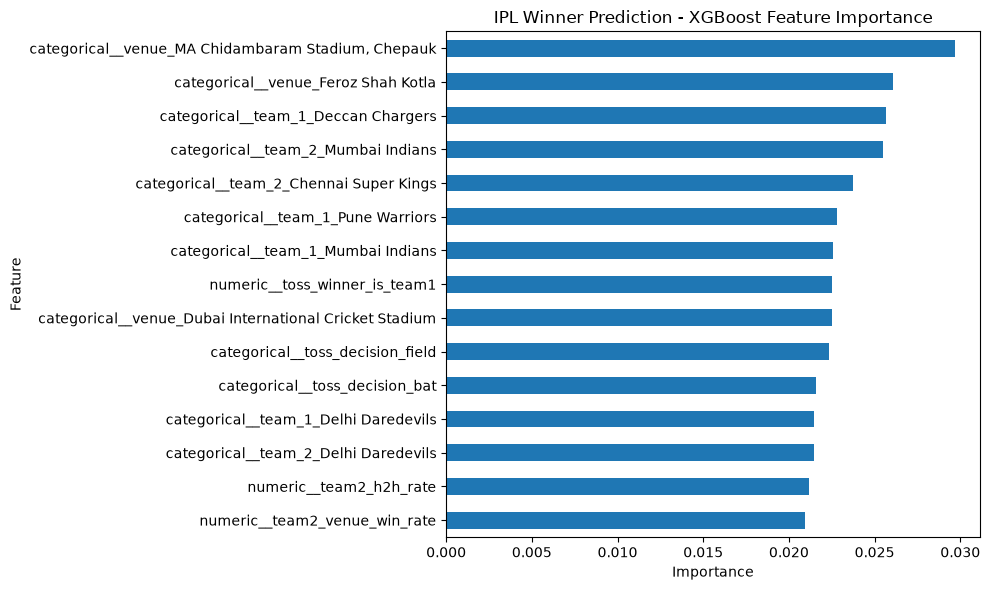

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the trained XGBoost model
xgb = xgb_model.named_steps["classifier"]

# Get encoded feature names
feature_names = xgb_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 15 features:")
print(importance_df.head(15).to_string(index=False))

# Plot feature importance
importance_df.head(15).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(10, 6)
)

plt.title("IPL Winner Prediction - XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

split_index = int(len(data) * 0.8)
train = data.iloc[:split_index]
test = data.iloc[split_index:]

feature_sets = {
    "A - Teams + Venue": [
        "team_1", "team_2", "venue"
    ],
    "B - Teams + Venue + Toss": [
        "team_1", "team_2", "venue",
        "toss_winner_is_team1", "toss_decision"
    ],
    "C - All Features": [
        "team_1", "team_2", "venue",
        "toss_winner_is_team1", "toss_decision",
        "team1_h2h_rate", "team2_h2h_rate",
        "team1_recent_form", "team2_recent_form",
        "team1_venue_win_rate", "team2_venue_win_rate"
    ]
}

results = []

for name, features in feature_sets.items():
    categorical = [
        col for col in features
        if train[col].dtype == "object"
    ]
    numeric = [col for col in features if col not in categorical]

    preprocessor = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", "passthrough", numeric)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=2,
            eval_metric="logloss",
            random_state=42
        ))
    ])

    model.fit(train[features], train["target"].astype(int))
    pred = model.predict(test[features])

    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(test["target"].astype(int), pred) * 100, 2
        )
    })

print(pd.DataFrame(results).to_string(index=False))

ValueError: could not convert string to float: 'Royal Challengers Bangalore'

In [14]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

feature_sets = {
    "A - Teams + Venue": [
        "team_1", "team_2", "venue"
    ],
    "B - Teams + Venue + Toss": [
        "team_1", "team_2", "venue",
        "toss_winner_is_team1", "toss_decision"
    ],
    "C - All Features": [
        "team_1", "team_2", "venue",
        "toss_winner_is_team1", "toss_decision",
        "team1_h2h_rate", "team2_h2h_rate",
        "team1_recent_form", "team2_recent_form",
        "team1_venue_win_rate", "team2_venue_win_rate"
    ]
}

split_index = int(len(data) * 0.8)
train = data.iloc[:split_index]
test = data.iloc[split_index:]

results = []

for name, features in feature_sets.items():

    # Explicitly identify categorical columns
    categorical = [
        col for col in features
        if col in ["team_1", "team_2", "venue", "toss_decision"]
    ]
    numeric = [col for col in features if col not in categorical]

    preprocessor = ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             categorical),
            ("num", "passthrough", numeric)
        ]
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=2,
            eval_metric="logloss",
            random_state=42
        ))
    ])

    X_train = train[features].copy()
    X_test = test[features].copy()
    y_train = train["target"].astype(int)
    y_test = test["target"].astype(int)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions) * 100

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy, 2)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

                   Model  Accuracy (%)
       A - Teams + Venue         47.55
B - Teams + Venue + Toss         48.53
        C - All Features         50.00


In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(
    train[["team_1"]],
    train["target"].astype(int)
)

baseline_predictions = baseline.predict(test[["team_1"]])

print(
    "Baseline Accuracy:",
    round(accuracy_score(
        test["target"].astype(int),
        baseline_predictions
    ) * 100, 2),
    "%"
)

Baseline Accuracy: 48.53 %


In [16]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

features = [
    "team_1", "team_2", "venue",
    "toss_winner_is_team1", "toss_decision",
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

categorical = ["team_1", "team_2", "venue", "toss_decision"]
numeric = [c for c in features if c not in categorical]

data["start_date"] = pd.to_datetime(data["start_date"])
data = data.dropna(subset=features + ["target"]).copy()

results = []

for year in sorted(data["start_date"].dt.year.unique()):
    train = data[data["start_date"].dt.year < year]
    test = data[data["start_date"].dt.year == year]

    if len(train) < 100 or len(test) == 0:
        continue

    preprocessor = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", "passthrough", numeric)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=2,
            eval_metric="logloss",
            random_state=42
        ))
    ])

    model.fit(train[features], train["target"].astype(int))
    pred = model.predict(test[features])

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(train[["team_1"]], train["target"].astype(int))
    baseline_pred = baseline.predict(test[["team_1"]])

    results.append({
        "Test Year": year,
        "Matches": len(test),
        "Model Accuracy (%)": round(
            accuracy_score(test["target"].astype(int), pred) * 100, 2
        ),
        "Baseline Accuracy (%)": round(
            accuracy_score(test["target"].astype(int), baseline_pred) * 100, 2
        )
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

if not results_df.empty:
    print("\nAverage Model Accuracy:",
          round(results_df["Model Accuracy (%)"].mean(), 2), "%")
    print("Average Baseline Accuracy:",
          round(results_df["Baseline Accuracy (%)"].mean(), 2), "%")

 Test Year  Matches  Model Accuracy (%)  Baseline Accuracy (%)
      2010       60               61.67                  55.00
      2011       72               62.50                  54.17
      2012       74               43.24                  44.59
      2013       76               50.00                  71.05
      2014       60               51.67                  46.67
      2015       57               52.63                  54.39
      2016       60               51.67                  46.67
      2017       59               52.54                  54.24
      2018       60               50.00                  46.67
      2019       59               50.85                  38.98
      2020       60               40.00                  50.00
      2021       60               48.33                  38.33
      2022       74               50.00                  50.00
      2023       73               64.38                  54.79

Average Model Accuracy: 52.11 %
Average Baseline Accur

In [17]:
# Check chronological order
data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

history_cols = [
    "team1_h2h_rate",
    "team2_h2h_rate",
    "team1_recent_form",
    "team2_recent_form",
    "team1_venue_win_rate",
    "team2_venue_win_rate"
]

print("Total matches:", len(data))
print("\nMissing historical values:")
print(data[history_cols].isna().sum())

print("\nHistorical feature summary:")
print(data[history_cols].describe().round(3))

print("\nFirst 5 chronological matches:")
print(data[["match_id", "start_date", "team_1",
            "team_2", "target"] + history_cols].head())

Total matches: 1019

Missing historical values:
team1_h2h_rate          0
team2_h2h_rate          0
team1_recent_form       0
team2_recent_form       0
team1_venue_win_rate    0
team2_venue_win_rate    0
dtype: int64

Historical feature summary:
       team1_h2h_rate  team2_h2h_rate  team1_recent_form  team2_recent_form  \
count        1019.000        1019.000           1019.000           1019.000   
mean            0.491           0.509              0.499              0.505   
std             0.243           0.243              0.226              0.228   
min             0.000           0.000              0.000              0.000   
25%             0.385           0.400              0.400              0.400   
50%             0.500           0.500              0.500              0.600   
75%             0.600           0.615              0.600              0.600   
max             1.000           1.000              1.000              1.000   

       team1_venue_win_rate  team2_venue_w

In [18]:
# Check whether each date has multiple matches
date_counts = (
    match_level_new.groupby("start_date")["match_id"]
    .nunique()
    .reset_index(name="matches_on_date")
)

print("Dates with multiple matches:")
print(date_counts[date_counts["matches_on_date"] > 1].head(10))

print("\nHistorical feature values for same-date matches:")
same_dates = date_counts.loc[
    date_counts["matches_on_date"] > 1, "start_date"f
].head(3)

for date in same_dates:
    print(f"\nDate: {date}")
    print(
        match_level_new.loc[
            match_level_new["start_date"] == date,
            ["match_id", "team_1", "team_2",
             "team1_h2h_rate", "team2_h2h_rate",
             "team1_recent_form", "team2_recent_form"]
        ].to_string(index=False)
    )

Dates with multiple matches:
   start_date  matches_on_date
1  2008-04-19                2
2  2008-04-20                2
8  2008-04-26                2
9  2008-04-27                2
13 2008-05-01                2
15 2008-05-03                2
16 2008-05-04                2
20 2008-05-08                2
23 2008-05-11                2
29 2008-05-17                2

Historical feature values for same-date matches:

Date: 2008-04-19 00:00:00
 match_id           team_1              team_2  team1_h2h_rate  team2_h2h_rate  team1_recent_form  team2_recent_form
   335983  Kings XI Punjab Chennai Super Kings             0.5             0.5                0.5                0.5
   335984 Delhi Daredevils    Rajasthan Royals             0.5             0.5                0.5                0.5

Date: 2008-04-20 00:00:00
 match_id                team_1                      team_2  team1_h2h_rate  team2_h2h_rate  team1_recent_form  team2_recent_form
   335985        Mumbai Indians Royal Challen

In [19]:

from collections import defaultdict
import pandas as pd

# Sort matches chronologically
data = match_level_new.copy()

data["start_date"] = pd.to_datetime(data["start_date"])
data = data.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

# Store past match results
team_results = defaultdict(list)
h2h_results = defaultdict(list)
venue_results = defaultdict(list)

feature_rows = []

# Process all matches on the same date together
for date, group in data.groupby("start_date", sort=True):

    daily_features = []

    # First calculate features for every match of this date
    for _, row in group.iterrows():

        t1 = row["team_1"]
        t2 = row["team_2"]
        venue = row["venue"]
        winner = row["winner"]

        pair = tuple(sorted([t1, t2]))

        h2h = h2h_results[pair]
        recent1 = team_results[t1][-5:]
        recent2 = team_results[t2][-5:]

        venue1 = venue_results[(t1, venue)]
        venue2 = venue_results[(t2, venue)]

        # Default to 0.5 when history is unavailable
        features = {
            "match_id": row["match_id"],
            "team1_h2h_rate": (
                sum(w == t1 for w in h2h) / len(h2h)
                if h2h else 0.5
            ),
            "team2_h2h_rate": (
                sum(w == t2 for w in h2h) / len(h2h)
                if h2h else 0.5
            ),
            "team1_recent_form": (
                sum(recent1) / len(recent1)
                if recent1 else 0.5
            ),
            "team2_recent_form": (
                sum(recent2) / len(recent2)
                if recent2 else 0.5
            ),
            "team1_venue_win_rate": (
                sum(venue1) / len(venue1)
                if venue1 else 0.5
            ),
            "team2_venue_win_rate": (
                sum(venue2) / len(venue2)
                if venue2 else 0.5
            )
        }

        daily_features.append(features)

    # Only after all same-date features are calculated,
    # add that date's match results to historical records
    for _, row in group.iterrows():

        t1 = row["team_1"]
        t2 = row["team_2"]
        venue = row["venue"]
        winner = row["winner"]

        pair = tuple(sorted([t1, t2]))

        h2h_results[pair].append(winner)

        team_results[t1].append(int(winner == t1))
        team_results[t2].append(int(winner == t2))

        venue_results[(t1, venue)].append(int(winner == t1))
        venue_results[(t2, venue)].append(int(winner == t2))

    feature_rows.extend(daily_features)

# Attach recalculated historical features
features_df = pd.DataFrame(feature_rows)

match_level_new = match_level_new.drop(
    columns=[
        "team1_h2h_rate", "team2_h2h_rate",
        "team1_recent_form", "team2_recent_form",
        "team1_venue_win_rate", "team2_venue_win_rate"
    ],
    errors="ignore"
)

match_level_new = match_level_new.merge(
    features_df, on="match_id", how="left",
    validate="one_to_one"
)

print("Total matches:", len(match_level_new))
print("\nMissing historical values:")
print(match_level_new[[
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]].isna().sum())

print("\nUpdated historical features:")
print(match_level_new[[
    "match_id", "start_date", "team_1", "team_2",
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]].head(10).to_string(index=False))

Total matches: 1019

Missing historical values:
team1_h2h_rate          0
team2_h2h_rate          0
team1_recent_form       0
team2_recent_form       0
team1_venue_win_rate    0
team2_venue_win_rate    0
dtype: int64

Updated historical features:
 match_id start_date                      team_1                      team_2  team1_h2h_rate  team2_h2h_rate  team1_recent_form  team2_recent_form  team1_venue_win_rate  team2_venue_win_rate
   335982 2008-04-18 Royal Challengers Bangalore       Kolkata Knight Riders             0.5             0.5                0.5                0.5                   0.5                   0.5
   335983 2008-04-19             Kings XI Punjab         Chennai Super Kings             0.5             0.5                0.5                0.5                   0.5                   0.5
   335984 2008-04-19            Delhi Daredevils            Rajasthan Royals             0.5             0.5                0.5                0.5                   0.5            

In [20]:

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

features = [
    "team_1", "team_2", "venue",
    "toss_winner_is_team1", "toss_decision",
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

categorical = [
    "team_1", "team_2", "venue", "toss_decision"
]
numeric = [c for c in features if c not in categorical]

results = []

for year in sorted(data["start_date"].dt.year.unique()):
    train = data[data["start_date"].dt.year < year]
    test = data[data["start_date"].dt.year == year]

    if len(train) < 100 or test.empty:
        continue

    preprocessor = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", "passthrough", numeric)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=2,
            eval_metric="logloss",
            random_state=42
        ))
    ])

    X_train = train[features]
    X_test = test[features]
    y_train = train["target"].astype(int)
    y_test = test["target"].astype(int)

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train[["team_1"]], y_train)
    baseline_pred = baseline.predict(X_test[["team_1"]])

    results.append({
        "Season": year,
        "Matches": len(test),
        "Model Accuracy (%)": round(
            accuracy_score(y_test, pred) * 100, 2
        ),
        "Baseline Accuracy (%)": round(
            accuracy_score(y_test, baseline_pred) * 100, 2
        )
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

print("\nAverage Model Accuracy:",
      round(results_df["Model Accuracy (%)"].mean(), 2), "%")
print("Average Baseline Accuracy:",
      round(results_df["Baseline Accuracy (%)"].mean(), 2), "%")

 Season  Matches  Model Accuracy (%)  Baseline Accuracy (%)
   2010       60               61.67                  55.00
   2011       72               62.50                  54.17
   2012       74               43.24                  44.59
   2013       76               50.00                  71.05
   2014       60               51.67                  46.67
   2015       57               52.63                  54.39
   2016       60               51.67                  46.67
   2017       59               52.54                  54.24
   2018       60               50.00                  46.67
   2019       59               50.85                  38.98
   2020       60               40.00                  50.00
   2021       60               48.33                  38.33
   2022       74               50.00                  50.00
   2023       73               64.38                  54.79

Average Model Accuracy: 52.11 %
Average Baseline Accuracy: 50.4 %


In [21]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score
import pandas as pd

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

features = [
    "team_1", "team_2", "venue",
    "toss_winner_is_team1", "toss_decision",
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

categorical = ["team_1", "team_2", "venue", "toss_decision"]
numeric = [c for c in features if c not in categorical]

season_results = []

for year in sorted(data["start_date"].dt.year.unique()):
    train = data[data["start_date"].dt.year < year]
    test = data[data["start_date"].dt.year == year]

    if len(train) < 100 or test.empty:
        continue

    preprocess = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", "passthrough", numeric)
    ])

    model = Pipeline([
        ("preprocess", preprocess),
        ("rf", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=5,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42
        ))
    ])

    model.fit(train[features], train["target"].astype(int))
    pred = model.predict(test[features])

    season_results.append({
        "Season": year,
        "Matches": len(test),
        "Random Forest Accuracy (%)": round(
            accuracy_score(test["target"].astype(int), pred) * 100, 2
        )
    })

rf_results = pd.DataFrame(season_results)
print(rf_results.to_string(index=False))

if not rf_results.empty:
    print(
        "\nAverage Random Forest Accuracy:",
        round(rf_results["Random Forest Accuracy (%)"].mean(), 2),
        "%"
    )

 Season  Matches  Random Forest Accuracy (%)
   2010       60                       58.33
   2011       72                       56.94
   2012       74                       54.05
   2013       76                       50.00
   2014       60                       43.33
   2015       57                       50.88
   2016       60                       56.67
   2017       59                       50.85
   2018       60                       50.00
   2019       59                       54.24
   2020       60                       40.00
   2021       60                       45.00
   2022       74                       48.65
   2023       73                       54.79

Average Random Forest Accuracy: 50.98 %


In [22]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score
import pandas as pd

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

features = [
    "team_1", "team_2", "venue",
    "toss_winner_is_team1", "toss_decision",
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

categorical = ["team_1", "team_2", "venue", "toss_decision"]
numeric = [c for c in features if c not in categorical]

results = []

for year in sorted(data["start_date"].dt.year.unique()):
    train = data[data["start_date"].dt.year < year]
    test = data[data["start_date"].dt.year == year]

    if len(train) < 100 or test.empty:
        continue

    preprocessor = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", StandardScaler(), numeric)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    model.fit(train[features], train["target"].astype(int))
    pred = model.predict(test[features])

    results.append({
        "Season": year,
        "Matches": len(test),
        "Logistic Regression Accuracy (%)": round(
            accuracy_score(test["target"].astype(int), pred) * 100, 2
        )
    })

lr_results = pd.DataFrame(results)
print(lr_results.to_string(index=False))

if not lr_results.empty:
    print(
        "\nAverage Logistic Regression Accuracy:",
        round(
            lr_results["Logistic Regression Accuracy (%)"].mean(), 2
        ),
        "%"
    )

 Season  Matches  Logistic Regression Accuracy (%)
   2010       60                             56.67
   2011       72                             59.72
   2012       74                             54.05
   2013       76                             61.84
   2014       60                             48.33
   2015       57                             50.88
   2016       60                             46.67
   2017       59                             49.15
   2018       60                             50.00
   2019       59                             40.68
   2020       60                             58.33
   2021       60                             55.00
   2022       74                             50.00
   2023       73                             58.90

Average Logistic Regression Accuracy: 52.87 %


In [23]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

features = [
    "team_1", "team_2", "venue",
    "toss_winner_is_team1", "toss_decision",
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

split_index = int(len(data) * 0.8)
train = data.iloc[:split_index]
test = data.iloc[split_index:]

categorical = ["team_1", "team_2", "venue", "toss_decision"]
numeric = [c for c in features if c not in categorical]

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("num", StandardScaler(), numeric)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(train[features], train["target"].astype(int))
pred = model.predict(test[features])
y_test = test["target"].astype(int)

print("Accuracy:", round(accuracy_score(y_test, pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test, pred,
    target_names=["Team 2 wins", "Team 1 wins"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred))

Accuracy: 51.96 %

Classification Report:
              precision    recall  f1-score   support

 Team 2 wins       0.53      0.59      0.56       105
 Team 1 wins       0.51      0.44      0.47        99

    accuracy                           0.52       204
   macro avg       0.52      0.52      0.52       204
weighted avg       0.52      0.52      0.52       204


Confusion Matrix:
[[62 43]
 [55 44]]


In [24]:

# Check recent-form features
cols = [
    "match_id",
    "start_date",
    "team_1",
    "team_2",
    "winner",
    "team1_recent_form",
    "team2_recent_form"
]

print(match_level_new[cols].head(15).to_string(index=False))

print("\nRecent form range:")
print(
    match_level_new[
        ["team1_recent_form", "team2_recent_form"]
    ].agg(["min", "max", "mean"]).round(3)
)

 match_id start_date                      team_1                      team_2                      winner  team1_recent_form  team2_recent_form
   335982 2008-04-18 Royal Challengers Bangalore       Kolkata Knight Riders       Kolkata Knight Riders           0.500000           0.500000
   335983 2008-04-19             Kings XI Punjab         Chennai Super Kings         Chennai Super Kings           0.500000           0.500000
   335984 2008-04-19            Delhi Daredevils            Rajasthan Royals            Delhi Daredevils           0.500000           0.500000
   335985 2008-04-20              Mumbai Indians Royal Challengers Bangalore Royal Challengers Bangalore           0.500000           0.000000
   335986 2008-04-20       Kolkata Knight Riders             Deccan Chargers       Kolkata Knight Riders           1.000000           0.500000
   335987 2008-04-21            Rajasthan Royals             Kings XI Punjab            Rajasthan Royals           0.000000           0.000000

In [25]:

from collections import defaultdict
import pandas as pd

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

team_history = defaultdict(list)
check_rows = []

# Process all matches on a date before adding that date's results
for date, group in data.groupby("start_date", sort=True):

    for _, row in group.iterrows():
        team1 = row["team_1"]
        team2 = row["team_2"]

        last5_team1 = team_history[team1][-5:]
        last5_team2 = team_history[team2][-5:]

        form1 = (
            sum(last5_team1) / len(last5_team1)
            if last5_team1 else 0.5
        )
        form2 = (
            sum(last5_team2) / len(last5_team2)
            if last5_team2 else 0.5
        )

        check_rows.append({
            "match_id": row["match_id"],
            "team1_form_check": form1,
            "team2_form_check": form2
        })

    # Add results only after processing all matches on this date
    for _, row in group.iterrows():
        winner = row["winner"]
        team_history[row["team_1"]].append(
            int(winner == row["team_1"])
        )
        team_history[row["team_2"]].append(
            int(winner == row["team_2"])
        )

check_df = pd.DataFrame(check_rows)

verified = match_level_new.merge(
    check_df, on="match_id", validate="one_to_one"
)

print("Team 1 form mismatches:",
      (verified["team1_recent_form"] -
       verified["team1_form_check"]).abs().gt(1e-9).sum())

print("Team 2 form mismatches:",
      (verified["team2_recent_form"] -
       verified["team2_form_check"]).abs().gt(1e-9).sum())

Team 1 form mismatches: 0
Team 2 form mismatches: 0


In [26]:

from collections import defaultdict
import pandas as pd

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

h2h_history = defaultdict(list)
h2h_checks = []

for date, group in data.groupby("start_date", sort=True):

    # Calculate H2H before adding any results from this date
    for _, row in group.iterrows():
        team1 = row["team_1"]
        team2 = row["team_2"]
        pair = tuple(sorted([team1, team2]))

        previous_winners = h2h_history[pair]

        form1 = (
            sum(w == team1 for w in previous_winners)
            / len(previous_winners)
            if previous_winners else 0.5
        )

        form2 = (
            sum(w == team2 for w in previous_winners)
            / len(previous_winners)
            if previous_winners else 0.5
        )

        h2h_checks.append({
            "match_id": row["match_id"],
            "team1_h2h_check": form1,
            "team2_h2h_check": form2
        })

    # Add results after all matches of the date are processed
    for _, row in group.iterrows():
        pair = tuple(sorted([row["team_1"], row["team_2"]]))
        h2h_history[pair].append(row["winner"])

h2h_df = pd.DataFrame(h2h_checks)

verified = match_level_new.merge(
    h2h_df, on="match_id", validate="one_to_one"
)

print(
    "Team 1 H2H mismatches:",
    (verified["team1_h2h_rate"] -
     verified["team1_h2h_check"]).abs().gt(1e-9).sum()
)

print(
    "Team 2 H2H mismatches:",
    (verified["team2_h2h_rate"] -
     verified["team2_h2h_check"]).abs().gt(1e-9).sum()
)

Team 1 H2H mismatches: 0
Team 2 H2H mismatches: 0


In [27]:

from collections import defaultdict
import pandas as pd

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

venue_history = defaultdict(list)
venue_checks = []

for date, group in data.groupby("start_date", sort=True):

    # Calculate venue win rates before today's results
    for _, row in group.iterrows():
        team1 = row["team_1"]
        team2 = row["team_2"]
        venue = row["venue"]

        history1 = venue_history[(team1, venue)]
        history2 = venue_history[(team2, venue)]

        form1 = (
            sum(history1) / len(history1)
            if history1 else 0.5
        )
        form2 = (
            sum(history2) / len(history2)
            if history2 else 0.5
        )

        venue_checks.append({
            "match_id": row["match_id"],
            "team1_venue_check": form1,
            "team2_venue_check": form2
        })

    # Update history after all matches on this date
    for _, row in group.iterrows():
        team1 = row["team_1"]
        team2 = row["team_2"]
        venue = row["venue"]
        winner = row["winner"]

        venue_history[(team1, venue)].append(
            int(winner == team1)
        )
        venue_history[(team2, venue)].append(
            int(winner == team2)
        )

venue_df = pd.DataFrame(venue_checks)

verified = match_level_new.merge(
    venue_df, on="match_id", validate="one_to_one"
)

print(
    "Team 1 venue mismatches:",
    (verified["team1_venue_win_rate"] -
     verified["team1_venue_check"]).abs().gt(1e-9).sum()
)

print(
    "Team 2 venue mismatches:",
    (verified["team2_venue_win_rate"] -
     verified["team2_venue_check"]).abs().gt(1e-9).sum()
)

Team 1 venue mismatches: 0
Team 2 venue mismatches: 0


In [28]:

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier

data = match_level_new.sort_values(
    ["start_date", "match_id"]
).reset_index(drop=True)

features = [
    "team_1", "team_2", "venue",
    "toss_winner_is_team1", "toss_decision",
    "team1_h2h_rate", "team2_h2h_rate",
    "team1_recent_form", "team2_recent_form",
    "team1_venue_win_rate", "team2_venue_win_rate"
]

categorical = ["team_1", "team_2", "venue", "toss_decision"]
numeric = [c for c in features if c not in categorical]

results = []

for year in sorted(data["start_date"].dt.year.unique()):

    train = data[data["start_date"].dt.year < year].copy()
    test = data[data["start_date"].dt.year == year].copy()

    if len(train) < 100 or test.empty:
        continue

    y_train = train["target"].astype(int)
    y_test = test["target"].astype(int)

    preprocess_lr = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", StandardScaler(), numeric)
    ])

    preprocess_tree = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", "passthrough", numeric)
    ])

    models = {
        "Logistic Regression": Pipeline([
            ("prep", preprocess_lr),
            ("model", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            ))
        ]),
        "Random Forest": Pipeline([
            ("prep", preprocess_tree),
            ("model", RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=5,
                max_features="sqrt",
                class_weight="balanced",
                random_state=42
            ))
        ]),
        "XGBoost": Pipeline([
            ("prep", preprocess_tree),
            ("model", XGBClassifier(
                n_estimators=200,
                max_depth=3,
                learning_rate=0.03,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_lambda=2,
                eval_metric="logloss",
                random_state=42
            ))
        ])
    }

    # Majority-class baseline
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(train[["team_1"]], y_train)
    baseline_pred = baseline.predict(test[["team_1"]])

    results.append({
        "Season": year,
        "Model": "Baseline",
        "Matches": len(test),
        "Correct": int((baseline_pred == y_test).sum())
    })

    for name, model in models.items():
        model.fit(train[features], y_train)
        pred = model.predict(test[features])

        results.append({
            "Season": year,
            "Model": name,
            "Matches": len(test),
            "Correct": int((pred == y_test).sum())
        })

results_df = pd.DataFrame(results)

summary = results_df.groupby("Model").agg(
    Seasons=("Season", "nunique"),
    Total_Matches=("Matches", "sum"),
    Total_Correct=("Correct", "sum")
).reset_index()

summary["Overall_Accuracy_%"] = (
    summary["Total_Correct"] / summary["Total_Matches"] * 100
).round(2)

summary["Average_Season_Accuracy_%"] = (
    results_df.assign(
        Accuracy=results_df["Correct"] / results_df["Matches"] * 100
    )
    .groupby("Model")["Accuracy"]
    .mean()
    .reindex(summary["Model"])
    .values
    .round(2)
)

print("FAIR MODEL COMPARISON")
print(summary.sort_values(
    "Overall_Accuracy_%", ascending=False
).to_string(index=False))

FAIR MODEL COMPARISON
              Model  Seasons  Total_Matches  Total_Correct  Overall_Accuracy_%  Average_Season_Accuracy_%
Logistic Regression       14            904            481               53.21                      52.87
            XGBoost       14            904            472               52.21                      52.11
      Random Forest       14            904            462               51.11                      50.98
           Baseline       14            904            459               50.77                      50.40


In [29]:

import joblib
from pathlib import Path

# Save the fitted Logistic Regression pipeline
model_path = Path("ipl_winner_model.pkl")

joblib.dump(model, model_path)

print("Model saved successfully!")
print("File location:", model_path.resolve())

Model saved successfully!
File location: C:\Users\Aman Kumar\OneDrive\Documents\Data Analysis\IPL Match Prediction & Performance Analysis\ipl_winner_model.pkl
